### Continued on Aug-19-2026

This notes will be continued, and re-named as **Token_Monster_Notes**.
- Added contents from Applied Deep Learning;
- Added contents from LLMs and their Application;
- Go over the TF2 codes, but in PyTorch this time.
- Also, some random timbits from my Multi-Agent Chatroom project.



#### Target Environments Architecture

We are getting deep into this ML journey, having marched from a basic Jupyter Notebook environment to a TensorFlow 2 environment, then pivoted to PyTorch, with possibly more ahead. The need for a better-managed environments architecture is real: we might need to run TF2 code one moment, then switch to PyTorch the next. 

**ipykernel** will be our savior.

So at the beginning of Token_Monster, we will redesign the environments architecture as follows:

```text
 jupyter-env
     jupyterlab
     ipykernel

 tf2-env
     tensorflow
     ipykernel

 torch-env
     pytorch
     ipykernel

 llm-env
     transformers
     ipykernel
```

This way, we can easily switch from one kernel to another, without actually needing to activate/deactivate the venvs.



### Mar-06-2026

#### Backpropagation Demo, with a basic Feedforward Neural Network
* A Feedforward Neural Network (FNN) is the simplest type of neural network.
* Data flows in one direction—from the input layer, through one or more hidden layers, to the output layer—without any cycles or feedback connections.
  * Hidden layers are usually dense (fully connected) layers, where each neuron is connected to all neurons in the previous layer.
* FNNs can learn complex, non-linear relationships by applying activation functions between layers.
  * Compared to linear regression with feature engineering (manual design of interaction terms/features/high-order-variables), FNNs automatically learn feature interactions through the composition of multiple layers and weights.
* Feedforward Neural Networks (FNNs) provide a clear and standard framework for demonstrating the backpropagation algorithm used to compute gradients and update weights.
* Backpropagation is used to calculate gradients in multilayer networks during gradient descent.
  * It is performed backward because the loss is computed at the output layer and must be propagated back through the network to determine how each earlier layer contributed to the error.

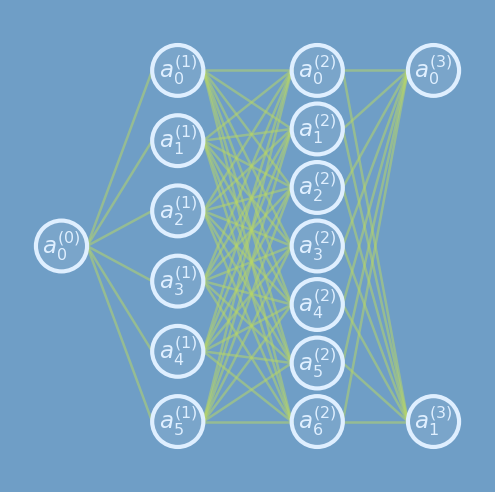

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# --------- layout (layers and nodes) ----------
layers = [1, 6, 7, 2]  # a^(0):1, a^(1):6, a^(2):7, a^(3):2
x_positions = [0.10, 0.35, 0.65, 0.90]

# (optional) labels to match your image style
def node_label(layer_idx, node_idx):
    return rf"$a_{{{node_idx}}}^{{({layer_idx})}}$"

# --------- style ----------
bg = "#6f9ec6"         # blue background
node_edge = "#dfefff"  # light ring
node_face = (1, 1, 1, 0.08)
edge_color = "#b6d56a" # yellow-green connections

r = 0.055  # node radius in axes coords

fig, ax = plt.subplots(figsize=(4, 4), dpi=150)
fig.patch.set_facecolor(bg)
ax.set_facecolor(bg)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

# --------- compute node positions ----------
positions = {}  # (layer_idx, node_idx) -> (x, y)
for li, (n, x) in enumerate(zip(layers, x_positions)):
    if n == 1:
        ys = [0.5]
    else:
        top, bottom = 0.88, 0.12
        ys = [top - i * (top - bottom) / (n - 1) for i in range(n)]
    for ni, y in enumerate(ys):
        positions[(li, ni)] = (x, y)

# --------- draw fully-connected edges between consecutive layers ----------
for li in range(len(layers) - 1):
    left_n = layers[li]
    right_n = layers[li + 1]
    for i in range(left_n):
        x1, y1 = positions[(li, i)]
        for j in range(right_n):
            x2, y2 = positions[(li + 1, j)]
            ax.plot([x1 + r, x2 - r], [y1, y2],
                    color=edge_color, lw=1.2, alpha=0.55, zorder=1)

# --------- draw nodes and labels ----------
for (li, ni), (x, y) in positions.items():
    c = Circle((x, y), r, facecolor=node_face, edgecolor=node_edge, lw=2.0, zorder=3)
    ax.add_patch(c)
    ax.text(x, y, node_label(li, ni), ha="center", va="center",
            color=node_edge, fontsize=11, zorder=4)

plt.show()


1-What's this Neural Network.
* Start with one input $\alpha_0^{(0)}$, outputs two coordinates $\alpha_0^{(3)}$ and $\alpha_1^{(3)}$;
* Draw $[\alpha_0^{(3)}, \alpha_1^{(3)}]$ on a X-Y axis to get a point.
* This above demo neural network has two hidden layers, make it
  * Input layer (L=0): 1 node $a_0^{(0)}$
  * Hidden layer 1 (L=1): 6 neurons $a_0^{(1)} \dots a_5^{(1)}$, with W1: (6, 1), b1: (6, 1)
  * Hidden layer 2 (L=2): 7 neurons $a_0^{(2)} \dots a_6^{(2)}$, with W2: (7, 6), b2: (7, 1)
  * Output layer (L=3): 2 neurons $a_0^{(3)}, a_1^{(3)}$, with W3: (2, 7), b3: (2, 1)


2-What's the demo plot from the trainning dataset $(x, y[y_0, y_1])$
* $x$: 100 even-spaced numbers from 0 to 1
* $y[y_0, y_1]$:
  * $y_0(x) = \frac{16\sin^3(2\pi x)}{20}$, and
  * $y_1(x) = \frac{13\cos(2\pi x)-5\cos(4\pi x)-2\cos(6\pi x)-\cos(8\pi x)}{20}$
  * The division by 20 just rescales the heart so it fits nicely in the plot.
  * `y = (y+1)/2` just relocate the heart from [-1, 1] to [0, 1] on the X-Y axis.
* Plot 100 points $[y_0, y_1]$ will give a heart-shaped curve.

(1, 100) (2, 100)


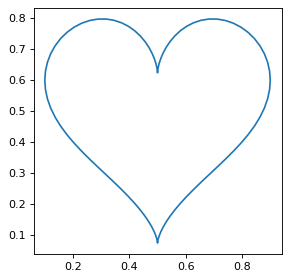

In [2]:
import numpy as np

def training_data (N = 100) :
    x = np.arange(0,1,1/N)
    #the parametric heart curve:
    y = np.array([16*np.sin(2*np.pi*x)**3,
                  13*np.cos(2*np.pi*x) - 5*np.cos(2*2*np.pi*x) - 2*np.cos(3*2*np.pi*x)- np.cos(4*2*np.pi*x)
                 ])
    # devide by 20 to scale it smaller
    y = y / 20
    # relocate the heart to [0, 1] on the X-Y axis
    y = (y+1)/2

    # turn x to a 1 by 100 np.array
    x = np.reshape(x, (1, N))
    return x, y

x, y = training_data (N = 100)
print(x.shape, y.shape)

#plot the parametric heart curve
plt.figure(figsize=(4, 4), dpi= 80)
plt.plot(y[0], y[1])
plt.show()


3-What does this neural network do.
>The core intuition of supervised learning. At its heart, whether you are using a simple linear regression or a massive neural network, you are performing function approximation: $\hat y = f(x) + \epsilon$
* This neural network would learn from a trainning dataset $(x, y[y_0, y_1])$, to output coordinates $[\alpha_0^{(3)}, \alpha_1^{(3)}]$
  * This is just to mimic those two complicated functions of $y_0(x)$, and $y_1(x)$
  * Linear Regression, or Neural Network. We justing simulating a function from real world data, then use it to predict the unknown (inference).
* Draw 100 set of $[\alpha_0^{(3)}, \alpha_1^{(3)}]$ on a X-Y axis, they would produce a curve that's roughly close to a heart-shape.

4-What math are we practising with this neural network demo.
* the linear regression, $ \mathbf{z}^{(n)} = \mathbf{W}^{(n)}\mathbf{a}^{(n-1)} + \mathbf{b}^{(n)} $
* the activation function, $ \mathbf{a}^{(n)} = \sigma(\mathbf{z}^{(n)}) $
* the logistic function, $ \sigma(\mathbf{z}) = \dfrac{1}{1 + \exp(-\mathbf{z})} $
* Because the output layer has 2 neurons, the squared-error cost becomes

$$C =
\frac{1}{n}
\left(
(a_0^{(3)} - y_0)^2 +
(a_1^{(3)} - y_1)^2
\right)
$$
* Equivalently, the cost in Vector Form

$$
C =
\frac{1}{n}
|\alpha^{(3)} - y|^2
$$

* as shown in the codes below
```python
np.linalg.norm(network_function(x)[-1] - y)**2 / x.size
```

5-Understanding the Error, Cost/Loss Function
* Cost/Loss Functiion: $L = \frac{1}{2}\|\mathbf{\hat{y}} - \mathbf{y}\|^2 = \frac{1}{2} \|\mathbf{w}x + \mathbf{b} - \mathbf{y}\|^2$
* Error: $\mathbf{e} = \mathbf{\hat{y}} - \mathbf{y}$
* note the difference
  * number of component (in a single output)
  * number of dataset (how many rows of data)
  * together, they can form a (n, m) matrix/tensor
* The loss/cost is not defined by the shape itself, but by the task.
  * Regression with output: 3×3 matrix of continuous values
    * Mean Squared Error (MSE): $\text{MSE} = \frac{1}{9} \sum_{i=1}^{3} \sum_{j=1}^{3} (y_{ij} - \hat{y}_{ij})^2$
  * Classification (per element) with output: 3×3 matrix with each componet (e.g., 0 or 1, or probabilities)
    * Binary/Categorical Cross-Entropy (BCE), applied element-wise.
    * Then: Sum or average over all 9 positions
  * Structured output (e.g., image, segmentation): 3×3 matrix is like a tiny image or label map
    * pixel-wise loss: MSE (for continuous), Cross-entropy (for class labels)
    * Same idea: loss is computed per cell, then aggregated
* Key idea: Even though the output is a matrix
  * the loss is usually: element-wise loss → then aggregated (mean or sum)
* Back to $C = \frac{1}{n} \left((a_0^{(3)} - y_0)^2 + (a_1^{(3)} - y_1)^2\right)$
  * aggregated (mean or sum), sum here $\left((a_0^{(3)} - y_0)^2 + (a_1^{(3)} - y_1)^2\right)$
    * when comparing the difference of two nearby loss, mean or sum doesn't matter
  * and the $\frac{1}{n}$ is about the number of rows ` x.size`, not the 2 elements in output coordinates $[\alpha_0^{(3)}, \alpha_1^{(3)}]$
* Loss functions are NOT Metrics
  * Loss function, is what the model uses to learn.
  * The model updates weights by minimizing the loss, (via backpropagation)
  * Examples:
    * Mean Squared Error (MSE)
    * Cross-Entropy Loss
  * Metric, is what you use to evaluate performance.
  * Not necessarily used to update weights
  * Examples:
    * Accuracy
    * Precision / Recall
    * F1-score


6-Understanding the Simple Linear Regression Setup, with closed-form solution
* A simple linear regression setup
  * Input: one number $x$
  * Output: two numbers $(y_1, y_2)$
  * Dataset: 1000 rows → $(x^{(i)}, y_1^{(i)}, y_2^{(i)})$
  * Model: $\hat{y}_1 = w_1 x + b_1,\quad \hat{y}_2 = w_2 x + b_2$
  * Weights: $w_1, w_2$
  * Biases: $b_1, b_2$
* Loss function (per data point, MSE): $L = \frac{1}{2} \left[(y_1 - \hat{y}_1)^2 + (y_2 - \hat{y}_2)^2 \right]$
* Full Gradient Descent (GD):
  * Uses all 1000 rows at once to update/calculate $w_1, b_1, w_2, b_2$
  * Vectorized form: $\hat{\mathbf{Y}} =\begin{bmatrix} \hat{Y}_1 \\ \hat{Y}_2 \end{bmatrix} = \begin{bmatrix} w_1 \\ w_2 \end{bmatrix} X + \begin{bmatrix} b_1 \\ b_2 \end{bmatrix}$
  * where $X, \hat{Y}_1, \hat{Y}_2 \in \mathbb{R}^{1000 \times 1}$
* Closed-form solution:
  * For linear regression, a closed-form solution exists (normal equation), so Gradient Descent is optional.
  * normal equation: $w = (X^T X)^{-1} X^T y$
  * GD is still often used for large datasets
    * calculating a closed-form solution is expensive for large datasets
    * GD scales better

7-Understanding `stochastic gradient descent (SGD)`
* Stochastic Gradient Descent (SGD)
  * Efficiency: Instead of processing the entire dataset (1000 rows) for a single gradient step
    * we update parameters using only one randomly selected row at a time.
    * 1 row $\rightarrow$ 1 update.
    * This introduces "noise" that can actually help the model escape local minima.
  * Core Math (Vector Form):
    * Prediction: $\mathbf{\hat{y}} = \mathbf{w}x + \mathbf{b}$
    * Loss Functiion: $L = \frac{1}{2}\|\mathbf{\hat{y}} - \mathbf{y}\|^2 = \frac{1}{2} \|\mathbf{w}x + \mathbf{b} - \mathbf{y}\|^2$
      * Error: $\mathbf{e} = \mathbf{\hat{y}} - \mathbf{y}$
    * Weight Update: $\mathbf{w} \leftarrow \mathbf{w} - \eta (\mathbf{e}x)$
      * __Gradient__ with respect to Weight ($\mathbf{w}$)
      * Using the chain rule, the gradient $\nabla_{\mathbf{w}}L$ is: $\dfrac{\partial L}{\partial \mathbf{w}} = (\mathbf{\hat{y}} - \mathbf{y})x = \mathbf{e}x$
      * $\mathbf{w} \leftarrow \mathbf{w} - \eta (\mathbf{e}x)$, the term $(\mathbf{e}x)$ is exactly the gradient.
    * Bias Update: $\mathbf{b} \leftarrow \mathbf{b} - \eta \mathbf{e}$
      * __Gradient__ with respect to Bias ($\mathbf{b}$)
      * $\frac{\partial L}{\partial \mathbf{b}} = (\mathbf{\hat{y}} - \mathbf{y})(1) = \mathbf{e}$
      * $\mathbf{b} \leftarrow \mathbf{b} - \eta \mathbf{e}$, the term $\mathbf{e}$ is the gradient.
  * Practical Noise
    * `self.W1 = self.W1 - dW1 * aggression * (1 + np.random.randn() * noise)`
    * This adds the "jitter" or Stochastic Noise.
    * It multiplies the gradient by a random number near 1.0.
    * This can sometimes help a network jump out of "local minima" (traps where the error stops decreasing).
  * How to determine if your model has converged.
    * The Gradient Norm (Mathematical Approach), the model stops moving when the gradient $\nabla L \approx 0$.
      * You can track the magnitude (norm) of the gradient vector: $\|\nabla L\| = \sqrt{\sum (\text{gradients})^2}$
      * Convergence criteria: If $\|\nabla L\| < \epsilon$ (where $\epsilon$ is a tiny threshold like $10^{-4}$), the surface is flat, and you have reached a local minimum.
    * Also with:
      * Monitoring the Loss Curve (Visual Approach)
      * Change in Parameters (Tolerance): $\|\mathbf{w}_{new} - \mathbf{w}_{old}\| < \text{tolerance}$, (e.g., `1e-6`)
    * and, Practical Implementation: Early Stopping
      * Instead of waiting for the gradient to hit exactly zero, you:
      * Split your data into Training and Validation sets.
      * Monitor the loss on the Validation set.
      * If the validation loss stops decreasing for a set number of rounds (called `patience`), you stop the training.
    



    

8-The math of Chain Rule, and the Procedure of Backpropagation (a computational algorithm)
* For each Layer
  * the Linear Regression $z = wx + b$
  * the activation funciton $a = \sigma(z)$
* But only the output layer has
  * the Loss Function $L = \text{loss}(a, y)$
* So we started from the `back` to calculate the gradient decent $\mathbf{w} \leftarrow \mathbf{w} - \eta \cdot (\nabla_{\mathbf{w}}L)$
* To get `the gradient of the Loss` with respect to the `weight` $w$:
  * we use the __Chain Rule__: $\dfrac{\partial L}{\partial w} = \dfrac{\partial L}{\partial a} \cdot \dfrac{\partial a}{\partial z} \cdot \dfrac{\partial z}{\partial w}$
* Doing this systematically from output layer back to earlier layers for all weights is __Backpropagation__.

9-Let's break down the math of chain rule calculation
* At the output layer, the cost for one training example is $C(x,y)$, then we write the gradient of Loss Function with regard to the weights in layer 3: $\dfrac{\partial C}{\partial \mathbf{W}^{(3)}}$
$$
\frac{\partial C}{\partial \mathbf{W}^{(3)}} =
\frac{\partial C}{\partial \mathbf{a}^{(3)}}
\frac{\partial \mathbf{a}^{(3)}}{\partial \mathbf{z}^{(3)}}
\frac{\partial \mathbf{z}^{(3)}}{\partial \mathbf{W}^{(3)}}
$$
* with input a0=x, we generate some random weight and bias, and calcuate values in each layer
```python
def network_function(a0) :
    z1 = W1 @ a0 + b1
    a1 = sigma(z1)
    z2 = W2 @ a1 + b2
    a2 = sigma(z2)
    z3 = W3 @ a2 + b3
    a3 = sigma(z3)
    return a0, z1, a1, z2, a2, z3, a3
```
* then calculate each of the derivation in the chain rule
  * Firstly, we calculate  $\dfrac{\partial C}{\partial \mathbf{a}^{(3)}} = \dfrac{\partial (\mathbf{a}^{(3)} - y)^2 /n}{\partial \mathbf{a}^{(3)}} = \dfrac{2}{n} \, (\mathbf{a}^{(3)} - y)$
  * Next, calculate $\dfrac{\partial \mathbf{a}^{(3)}}{\partial \mathbf{z}^{(3)}} = \dfrac{\partial (sigma(\mathbf{z}^{(3)})}{\partial \mathbf{z}^{(3)}} = d\_sigma(\mathbf{z}^{(3)})$
  * Next, calculte $\dfrac{\partial \mathbf{z}^{(3)}}{\partial \mathbf{W}^{(3)}} =  \dfrac{\partial(\mathbf{W}^{(3)}\mathbf{a}^{(2)} + \mathbf{b}^{(3)})}{\partial \mathbf{W}^{(3)}} = \mathbf{a}^{(2)}$
*  finally, chain rule them together $\dfrac{\partial C}{\partial \mathbf{W}^{(3)}} = \dfrac{2}{n} \, (\mathbf{a}^{(3)} - y) \cdot d\_sigma(\mathbf{z}^{(3)}) \cdot \mathbf{a}^{(2)}$


10-Expand the $ \mathbf{W}^{(3)}$ example to all parameters
* With regard to the bias in Layer 3: $\mathbf{b}^{(3)}$
$$ \frac{\partial C}{\partial \mathbf{b}^{(3)}} =
   \frac{\partial C}{\partial \mathbf{a}^{(3)}}
   \frac{\partial \mathbf{a}^{(3)}}{\partial \mathbf{z}^{(3)}}
   \frac{\partial \mathbf{z}^{(3)}}{\partial \mathbf{b}^{(3)}}
   $$
* Moving backward to Layer 2, we need to calculate this in Layer 3 first, that's the reason of backprop
$$ \frac{\partial \mathbf{a}^{(3)}}{\partial \mathbf{a}^{(2)}} =
   \frac{\partial \mathbf{a}^{(3)}}{\partial \mathbf{z}^{(3)}}
   \frac{\partial \mathbf{z}^{(3)}}{\partial \mathbf{a}^{(2)}} =
   \sigma'(\mathbf{z}^{(3)})
   \mathbf{W}^{(3)}$$
* With regard to the weights/bias in Layer 2:
$$ \frac{\partial C}{\partial \mathbf{W}^{(2)}} =
   \frac{\partial C}{\partial \mathbf{a}^{(3)}}
   \left(
   \frac{\partial \mathbf{a}^{(3)}}{\partial \mathbf{a}^{(2)}}
   \right)
   \frac{\partial \mathbf{a}^{(2)}}{\partial \mathbf{z}^{(2)}}
   \frac{\partial \mathbf{z}^{(2)}}{\partial \mathbf{W}^{(2)}}
   $$
$$ \frac{\partial C}{\partial \mathbf{b}^{(2)}} =
   \frac{\partial C}{\partial \mathbf{a}^{(3)}}
   \left(
   \frac{\partial \mathbf{a}^{(3)}}{\partial \mathbf{a}^{(2)}}
   \right)
   \frac{\partial \mathbf{a}^{(2)}}{\partial \mathbf{z}^{(2)}}
   \frac{\partial \mathbf{z}^{(2)}}{\partial \mathbf{b}^{(2)}}
   $$
* With regard to the weights/bias in Layer 1: note the requried calculation in parentheses from previous layers.
$$ \frac{\partial C}{\partial \mathbf{W}^{(1)}} =
   \frac{\partial C}{\partial \mathbf{a}^{(3)}}
   \left(
   \frac{\partial \mathbf{a}^{(3)}}{\partial \mathbf{a}^{(2)}}
   \frac{\partial \mathbf{a}^{(2)}}{\partial \mathbf{a}^{(1)}}
   \right)
   \frac{\partial \mathbf{a}^{(1)}}{\partial \mathbf{z}^{(1)}}
   \frac{\partial \mathbf{z}^{(1)}}{\partial \mathbf{W}^{(1)}}
   $$
$$ \frac{\partial C}{\partial \mathbf{b}^{(1)}} =
   \frac{\partial C}{\partial \mathbf{a}^{(3)}}
   \left(
   \frac{\partial \mathbf{a}^{(3)}}{\partial \mathbf{a}^{(2)}}
   \frac{\partial \mathbf{a}^{(2)}}{\partial \mathbf{a}^{(1)}}
   \right)
   \frac{\partial \mathbf{a}^{(1)}}{\partial \mathbf{z}^{(1)}}
   \frac{\partial \mathbf{z}^{(1)}}{\partial \mathbf{b}^{(1)}}
   $$

11-lastly, let's train this demo neural network, to silumlate that two parametric heart funcitons.
* input  $\alpha_0^{(0)} = x$
* Do the Neural Network Thing, output
* $\alpha_0^{(3)} \approx y_0(x) = \frac{16\sin^3(2\pi x)}{20}$, and
* $\alpha_1^{(3)} \approx y_1(x) = \frac{13\cos(2\pi x)-5\cos(4\pi x)-2\cos(6\pi x)-\cos(8\pi x)}{20}$
* Draw $[\alpha_0^{(3)}, \alpha_1^{(3)}]$, to get a heart shape plot, well, more or less.

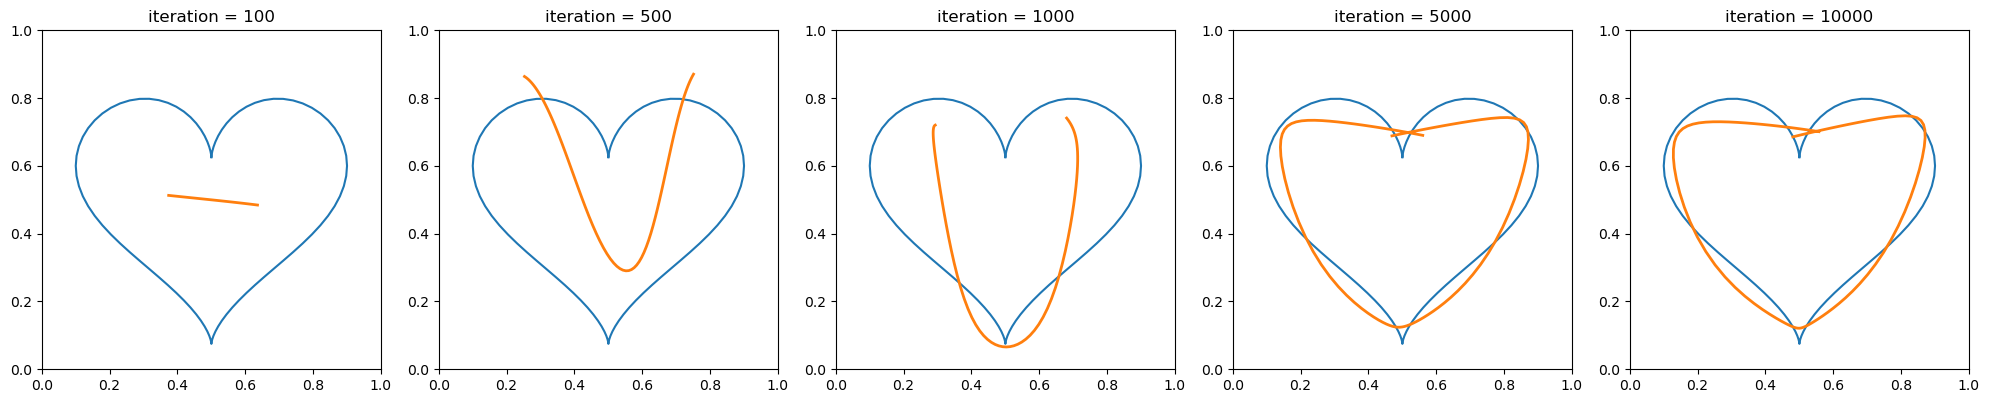

In [3]:
import numpy as np
import matplotlib.pyplot as plt

class NeuralNetwork:
    def __init__(self, n0=1, n1=6, n2=7, n3=2):
        # Activation function and its derivative
        self.sigma = lambda z: 1 / (1 + np.exp(-z))
        self.d_sigma = lambda z: np.cosh(z/2)**(-2) / 4
        
        # Initialize weights and biases
        self.W1 = np.random.randn(n1, n0) / 2
        self.W2 = np.random.randn(n2, n1) / 2
        self.W3 = np.random.randn(n3, n2) / 2
        
        self.b1 = np.random.randn(n1, 1) / 2
        self.b2 = np.random.randn(n2, 1) / 2
        self.b3 = np.random.randn(n3, 1) / 2

    def feed_forward(self, a0):
        z1 = self.W1 @ a0 + self.b1
        a1 = self.sigma(z1)
        z2 = self.W2 @ a1 + self.b2
        a2 = self.sigma(z2)
        z3 = self.W3 @ a2 + self.b3
        a3 = self.sigma(z3)
        return a0, z1, a1, z2, a2, z3, a3

    def get_cost(self, x, y):
        return np.linalg.norm(self.feed_forward(x)[-1] - y)**2 / x.size

    def get_gradients(self, x, y):
        a0, z1, a1, z2, a2, z3, a3 = self.feed_forward(x)
        m = x.size # normalized by size

        # Layer 3 Gradients
        dC_da3 = 2 * (a3 - y)
        delta3 = dC_da3 * self.d_sigma(z3)
        dW3 = delta3 @ a2.T / m
        db3 = np.sum(delta3, axis=1, keepdims=True) / m

        # Layer 2 Gradients
        delta2 = (self.W3.T @ delta3) * self.d_sigma(z2)
        dW2 = delta2 @ a1.T / m
        db2 = np.sum(delta2, axis=1, keepdims=True) / m

        # Layer 1 Gradients
        delta1 = (self.W2.T @ delta2) * self.d_sigma(z1)
        dW1 = delta1 @ a0.T / m
        db1 = np.sum(delta1, axis=1, keepdims=True) / m

        return dW1, dW2, dW3, db1, db2, db3

    def train(self, x, y, iterations=10000, aggression=7, noise=1):
        checkpoints = [100, 500, 1000, 5000, 10000]
        snapshots = {}

        for i in range(1, iterations + 1):
            grads = self.get_gradients(x, y)
            
            # Apply gradients with optional noise
            for param, grad in zip(['W1', 'W2', 'W3', 'b1', 'b2', 'b3'], grads):
                n = (1 + np.random.randn() * noise)
                current_val = getattr(self, param)
                setattr(self, param, current_val - grad * aggression * n)

            if i in checkpoints:
                snapshots[i] = self.feed_forward(x)[-1].copy()

        self._plot_results(y, checkpoints, snapshots)

    # a private method for this class to use internally
    def _plot_results(self, y, checkpoints, snapshots):
        fig, axes = plt.subplots(1, 5, figsize=(20, 4))
        for ax, step in zip(axes, checkpoints):
            ax.set_xlim([0, 1]); ax.set_ylim([0, 1]); ax.set_aspect(1)
            ax.plot(y[0], y[1], lw=1.5, label='Target')
            nf = snapshots[step]
            ax.plot(nf[0], nf[1], lw=2, label='Output')
            ax.set_title(f"iteration = {step}")
        plt.tight_layout()
        plt.show()

# Usage:
nn = NeuralNetwork()
# Assuming training_data() exists and returns x, y
x, y = training_data() 
nn.train(x, y)


12-Understanding
```python
# Apply gradients with optional noise
for param, grad in zip(['W1', 'W2', 'W3', 'b1', 'b2', 'b3'], grads):
    n = (1 + np.random.randn() * noise)
    current_val = getattr(self, param)
    setattr(self, param, current_val - grad * aggression * n)
```
| Function | What it does | Example |
|---|---|---|
| hasattr() | Asks: "Do you have this?" | if hasattr(self, "W4"): ... |
| getattr() | Asks: "Give me this." | weights = getattr(self, "W1") |
| setattr() | Tells: "Change this to X." | setattr(self, "W1", new_matrix) |

Note, it uses String, the name of that variable, but return the value of that variable
```python
for name in ["W1", "W2", "W3"]:
    val = getattr(self, name) # "Hey Python, get me the thing named 'W1'"
```

#### Redo this Heart Formula Neural Network with TensorFlow Keras
* Same Goal, use tensorflow to simulate the formula to plot a heart shape
* The heart formula
  * $y_0(x) = \dfrac{16\sin^3(2\pi x)}{20}$, and
  * $y_1(x) = \dfrac{13\cos(2\pi x)-5\cos(4\pi x)-2\cos(6\pi x)-\cos(8\pi x)}{20}$

1-Generate 10,000 trainning data points
* each (y0, y1) is just a point on the heart shape
* the total 10,000 (x) points are still in this [0, 1] range
* this whole dataset, although with this 10k points, just plot one heart

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

# 10,000 random x values in [0, 1]
x = np.random.rand(10000, 1)

# heart formulas
y0 = 16 * np.sin(2 * np.pi * x[:, 0])**3
y1 = 13 * np.cos(2 * np.pi * x[:, 0]) \
     - 5 * np.cos(4 * np.pi * x[:, 0]) \
     - 2 * np.cos(6 * np.pi * x[:, 0]) \
     - np.cos(8 * np.pi * x[:, 0])

# combine into shape (10000, 2)
y = np.stack([y0, y1], axis=1)

# scale and relocate to [0, 1]
y = y / 20
y = (y + 1) / 2

print("x shape:", x.shape)   # (10000, 1)
print("y shape:", y.shape)   # (10000, 2)

x shape: (10000, 1)
,,,,,,y shape: (10000, 2)


2-Build the Keras model
* 5 layers

Check out the model layers

```python
model = models.Sequential([layers.Input(shape=(1,)),
                           layers.Dense(32, activation='tanh'),
                           layers.Dense(64, activation='tanh'),
                           layers.Dense(64, activation='tanh'),
                           layers.Dense(2)
                          ])

model.summary()

```

3-Compile and Train the model


```python
model.compile(optimizer='adam',
              loss='mse',
              metrics=['mae']
             )

history = model.fit(x, y,
                    epochs=20,
                    batch_size=32,
                    validation_split=0.2,
                    verbose=0  # hide the output progress
                   )

```

4-Plot training history

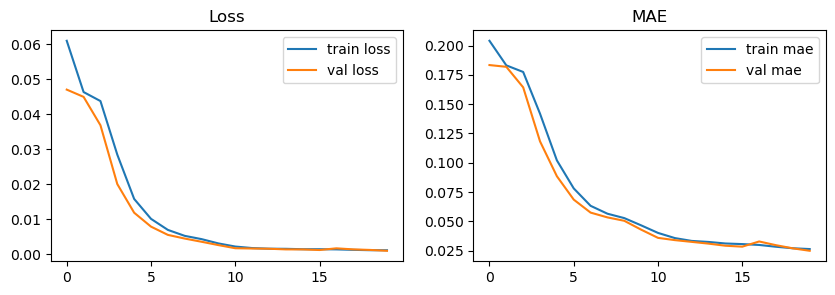

In [7]:
plt.figure(figsize=(10, 3))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.legend()
plt.title("Loss")

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='train mae')
plt.plot(history.history['val_mae'], label='val mae')
plt.legend()
plt.title("MAE")

plt.show()

5-Plot the hearts from Heart Formula, and Model Prediction.

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


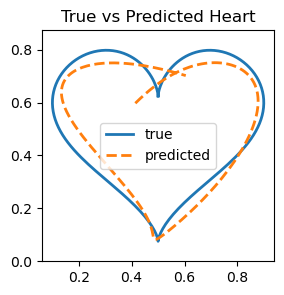

In [8]:
x_test = np.linspace(0, 1, 200).reshape(-1, 1)
y_pred = model.predict(x_test)

# true curve from exact formulas
y0_true = 16 * np.sin(2 * np.pi * x_test[:, 0])**3
y1_true = 13 * np.cos(2 * np.pi * x_test[:, 0]) \
          - 5 * np.cos(4 * np.pi * x_test[:, 0]) \
          - 2 * np.cos(6 * np.pi * x_test[:, 0]) \
          - np.cos(8 * np.pi * x_test[:, 0])

y_true = np.stack([y0_true, y1_true], axis=1)
y_true = y_true / 20
y_true = (y_true + 1) / 2

plt.figure(figsize=(3, 3))
plt.plot(y_true[:, 0], y_true[:, 1], label='true', linewidth=2)
plt.plot(y_pred[:, 0], y_pred[:, 1], '--', label='predicted', linewidth=2)
plt.title("True vs Predicted Heart")
plt.axis("equal")
plt.legend()
plt.show()

6-All code in one block, with `epochs_list = [1, 5, 10, 20]` for comparison

C:\Users\NXT51\miniconda3\envs\tf_env_py310\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
,,,,,,  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
,,,,,,313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
,,,,,,313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
,,,,,,313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


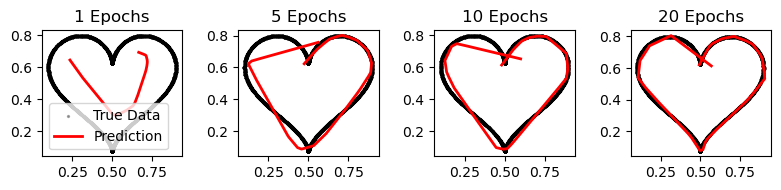

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# 1. Improved helper function
# Passing input_dim makes the function more robust and reusable
def build_new_model(input_dim):
    model = Sequential([
        Dense(64, activation='relu', input_shape=(input_dim,)),
        Dense(64, activation='relu'),
        Dense(2) 
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

# --- Data Check ---
# 10,000 random x values in [0, 1]
x = np.random.rand(10000, 1)

# heart formulas
y0 = 16 * np.sin(2 * np.pi * x[:, 0])**3
y1 = 13 * np.cos(2 * np.pi * x[:, 0]) \
     - 5 * np.cos(4 * np.pi * x[:, 0]) \
     - 2 * np.cos(6 * np.pi * x[:, 0]) \
     - np.cos(8 * np.pi * x[:, 0])

# combine into shape (10000, 2)
y = np.stack([y0, y1], axis=1)

# scale and relocate to [0, 1]
y = y / 20
y = (y + 1) / 2
# ------------------

# 2. Setup
epochs_list = [1, 5, 10, 20]
fig, axes = plt.subplots(1, 4, figsize=(8, 2))

# Sort x to ensure the prediction line connects points in order
idx_sort = np.argsort(x[:, 0])
x_sorted = x[idx_sort]

for i, num_epochs in enumerate(epochs_list):
    # Build and train a fresh instance
    current_model = build_new_model(x.shape[1])
    current_model.fit(x, y, epochs=num_epochs, batch_size=32, verbose=0)
    
    # Predict on the sorted values
    y_pred = current_model.predict(x_sorted)
    
    ax = axes[i]
    
    # Plot True Data (faded scatter)
    ax.scatter(y[:, 0], y[:, 1], color='black', s=2, label='True Data', alpha=0.3)
    
    # Plot Prediction (solid line)
    # Using the sorted predictions creates a continuous path
    ax.plot(y_pred[:, 0], y_pred[:, 1], color='red', linewidth=2, label='Prediction')
    
    ax.set_title(f"{num_epochs} Epochs")
    ax.axis("equal")
    if i == 0: 
        ax.legend()

plt.tight_layout()
plt.show()

#### How to get the Weights and Bias from a Dense Layer
```python
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.layers.Dense(3, input_shape=(4,))
])

# Build the model by calling it once
model(tf.random.normal((1, 4)))

weights = model.layers[0].get_weights()
print(weights)
```

### Mar-29-2026

#### Understanding Convolutional Neural Network
* We are using a 2D convolutional layer from `Keras`
* It does `Feature Map Extraction`
* `layers.Conv2D(32, (3, 3), activation='relu', name='target_conv_layer')`
  * it has 32 filter matrix, each with a dimention of 3 by 3
  * 

1-Load a MNIST handwritten digit image (28 by 28, grey scale).

,,,,,,,,,11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


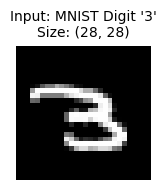

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, datasets

# Load MNIST dataset and pick a random digit
(x_train, y_train), _ = datasets.mnist.load_data()

#idx = np.random.randint(0, len(x_train))
idx = 250
digit_image = x_train[idx].astype("float32") / 255.0

plt.figure(figsize=(2, 2))
plt.imshow(digit_image, cmap='gray')
plt.title(f"Input: MNIST Digit '{y_train[idx]}'\nSize: {x_train[idx].shape}", fontsize=10)
plt.axis('off')
plt.tight_layout()
plt.show()

2-Initiate an Conv2D model from `Keras.layers`
* This creates 32 3x3 matrix
* Each component is a weight
* All values in the matrix are randomly initiated

In [2]:
# Define the Conv2D layer
model = models.Sequential([layers.Input(shape=(28, 28, 1)),
                           layers.Conv2D(32, (3, 3), activation='relu', name='target_conv_layer')
                          ])

# Get weights for the layer: (height, width, in_channels, out_channels)
weights, biases = model.get_layer('target_conv_layer').get_weights()

# Show the first 3x3 filter matrix
print("Randomly Initiated, Filter #1 Matrix:\n\n", weights[:, :, 0, 0])

Randomly Initiated, Filter #1 Matrix:
,,,,,,,,,
,,,,,,,,, [[-0.09353065  0.12178136  0.05542119]
,,,,,,,,, [-0.02756535  0.13826631 -0.13247152]
,,,,,,,,, [ 0.13024624 -0.0330933   0.13129388]]


3-Demo of the `Convolving` process, with Filter #1 Matrix
* fisrt, split the digit image (28x28) into a 26x26 matrix, each componet is a (3x3) slice
* second, multiply the Filter #1 Matrix to that 26x26 matrix.
* third, add the bias, and activation function (ReLU)

In [3]:
def extract_slices(image, filter_size=3):
    """
    Splits an image into a grid of overlapping slices.
    For a 28x28 image and 3x3 filter, returns a 26x26 grid of 3x3 slices.
    """
    rows = len(image)
    cols = len(image[0])
    
    # Calculate how many steps the window can take
    # Formula: (Input - Filter) + 1
    num_rows = rows - filter_size + 1
    num_cols = cols - filter_size + 1
    
    all_slices = []
    
    for r in range(num_rows):
        row_slices = []
        for c in range(num_cols):
            # The slicing step
            # image[r : r + filter_size] gets the horizontal rows
            # [row[c : c + filter_size] ...] gets the vertical columns within those rows
            slice_3x3 = [row[c : c + filter_size] for row in image[r : r + filter_size]]
            row_slices.append(slice_3x3)
            
        all_slices.append(row_slices)
        
    return np.array(all_slices)

In [4]:
sliced_digit_image = extract_slices(digit_image, filter_size=3)
sliced_digit_image.shape

(26, 26, 3, 3)

In [5]:
# use np.einsum('ijkl,kl->ij', A, W) (Einstein summation) to apply this feature extraction


# Step 1: dot product (what you already have)
raw = np.einsum('ijkl,kl->ij', sliced_digit_image, weights[:, :, 0, 0])

# Step 2: add the bias for filter 0 (filter 1 in 1-indexed terms)
raw_with_bias = raw + biases[0]

# Step 3: apply ReLU
filter_1_output_digit_image = np.maximum(0, raw_with_bias)

filter_1_output_digit_image.shape

(26, 26)

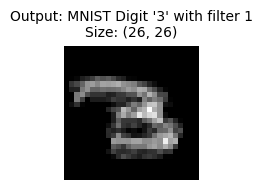

In [6]:
plt.figure(figsize=(2, 2))
plt.imshow(filter_1_output_digit_image, cmap='gray')
plt.title(f"Output: MNIST Digit '{y_train[idx]}' with filter 1\nSize: {filter_1_output_digit_image.shape}", fontsize=10)
plt.axis('off')
plt.tight_layout()
plt.show()

4-Let's tensorflow do all the 32 fiters heavy lifting
* note, need to reshape the input matrix from (28, 28) to (1, 28, 28, 1)

In [7]:
# Build the extractor
feature_extractor = models.Model(inputs=model.inputs,
                                 outputs=model.get_layer('target_conv_layer').output
                                )

# Reshape for the model: (Batch, Height, Width, Channels)
# axis=(0, -1) adds two new axes at begin and end
sample_image = np.expand_dims(digit_image, axis=(0, -1))
print(sample_image.shape)

# Predict (Run the convolution with all 32 filter)
feature_maps = feature_extractor.predict(sample_image)

(1, 28, 28, 1)
,,,,,,,,,WARNING:tensorflow:TensorFlow GPU support is not available on native Windows for TensorFlow >= 2.11. Even if CUDA/cuDNN are installed, GPU will not be used. Please use WSL2 or the TensorFlow-DirectML plugin.
,,,,,,,,,1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step


5-Plot the 32 feature map output

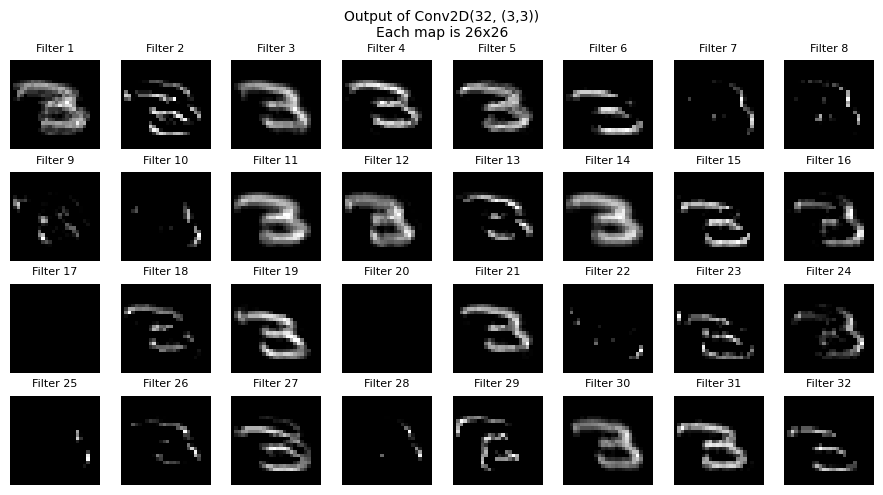

In [8]:
# FIGURE 2: THE 32 OUTPUT FEATURE MAPS
fig2, axes2 = plt.subplots(4, 8, figsize=(9, 5))
fig2.suptitle(f"Output of Conv2D(32, (3,3))\nEach map is 26x26", fontsize=10)

for i, ax in enumerate(axes2.flat):
    f_map = feature_maps[0, :, :, i]
    ax.imshow(f_map, cmap='gray')
    ax.axis('off')
    ax.set_title(f"Filter {i+1}", fontsize=8)

plt.tight_layout()
plt.subplots_adjust(top=0.88) # Make room for the suptitle
plt.show()

In [9]:
# This will pass if the difference is within a tiny tolerance: atol=1e-6

np.testing.assert_allclose(filter_1_output_digit_image, 
                           feature_maps[0, :, :, 0], 
                           atol=1e-6)
#if True, this part will run
print("The arrays are essentially the same!")

The arrays are essentially the same!


6-Fit the model, to find the optimal weights and bias
* To move from random numbers to meaningful features, the model must go through the Training Loop.
* This involves three things you haven't called in your snippet yet:
  * `model.compile()`: This is where you choose your Loss Function (how the model measures error) and your Optimizer (the math used to update the weights).
  * `model.fit()`: This is the actual training process. The model looks at thousands of images, realizes its random weights are causing high error (loss), and uses Backpropagation to nudge those weights into better values.
  * Gradient Descent: This is the specific mechanism that "improves" the weights based on the loss function.

In [10]:
# Add a flattening and dense layer so the model can actually "learn" to classify
fit_model = models.Sequential([layers.Input(shape=(28, 28, 1)),
                               layers.Conv2D(32, (3, 3), activation='relu', name='target_conv_layer'),
                               layers.MaxPooling2D((2, 2)),
                               layers.Flatten(),
                               layers.Dense(10, activation='softmax')
                              ])

fit_model.compile(optimizer='adam', 
                  loss='sparse_categorical_crossentropy', 
                  metrics=['accuracy']
                 )

# Train for just 2 epochs (MNIST is fast!)
fit_model.fit(x_train.reshape(-1, 28, 28, 1), y_train, epochs=2, batch_size=64)

Epoch 1/2
,,,,,,,,,938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.9379 - loss: 0.6992
,,,,,,,,,Epoch 2/2
,,,,,,,,,938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9760 - loss: 0.0875


Understanding the `models.Sequential([])`
* `layers.Input(shape=(28, 28, 1))`
  * This is the entry point of your network.
  * What it does: It defines the dimensions of your incoming data. In this case, it’s expecting a 28x28 pixel image.
  * The "1": This represents the color channel. Since it's 1, the model is expecting grayscale (if it were 3, it would be RGB color).

* `layers.Conv2D(32, (3, 3), activation='relu')`
  * This is the feature extractor (the "eyes" of the model).
  * What it does: It slides 32 different filters (each 3x3 in size) over the image. These filters look for specific patterns like edges, curves, or textures.
  * Activation ('relu'): This stands for Rectified Linear Unit. It replaces all negative pixel values with zero, which helps the model learn complex patterns by introducing "non-linearity." Without it, the model would just be a giant, glorified linear equation.

* `layers.MaxPooling2D((2, 2))`
  * This is the concentrator or "summarizer."
  * What it does: It looks at 2x2 blocks of the image and keeps only the maximum value from each block.
  * Why? It reduces the spatial size of the data by half. This makes the model faster and helps it become "translation invariant"—meaning it can recognize a shape even if it's shifted slightly to the left or right.

* `layers.Flatten()`
  * This is the bridge between 2D and 1D.
  * What it does: Up until now, your data is a 3D "cube" of features. The `Dense` layer at the end can't read cubes; it only understands long lists (vectors). `Flatten` takes that cube and unrolls it into one long, single line of numbers.

* `layers.Dense(10, activation='softmax')`
  * This is the classifier (the "brain").
  * What it does: It takes all those flattened features and connects them to 10 output nodes (likely representing digits 0-9).
  * Activation ('softmax'): This turns the final scores into probabilities that add up to 100%. For example, it might say: "I'm 92% sure this is a '7' and 8% sure it's a '1'."


In [11]:
fit_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ target_conv_layer (Conv2D)           │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 5408)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 10)                  │          54,090 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 163,232 (637.63 KB)

 Trainable params: 54,410 (212.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 108,822 (425.09 KB)

In [12]:
# Get the learned weights
fit_weights, fit_biases = fit_model.get_layer('target_conv_layer').get_weights()

# Show the first 3x3 filter matrix, after fitting(trainning) the model
print("After Trainning, Filter #1 Matrix:\n\n", fit_weights[:, :, 0, 0])

After Trainning, Filter #1 Matrix:
,,,,,,,,,
,,,,,,,,, [[ 0.02936277 -0.07216038  0.03748665]
,,,,,,,,, [-0.04386743  0.01193451 -0.01335237]
,,,,,,,,, [-0.0126987  -0.04590547 -0.01203603]]


In [13]:
# Create a model that outputs the 'target_conv_layer' activations
fit_feature_extractor = models.Model(inputs=fit_model.inputs,
                                     outputs=fit_model.get_layer('target_conv_layer').output
                                    )

# sample image already reshaped to match the feature_extractor
# Extract the features
fit_feature_maps = fit_feature_extractor.predict(sample_image)

print(f"Feature map shape: {fit_feature_maps.shape}") 
# Expected: (1, 26, 26, 32) -> 32 filters of 26x26 pixels

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
,,,,,,,,,Feature map shape: (1, 26, 26, 32)


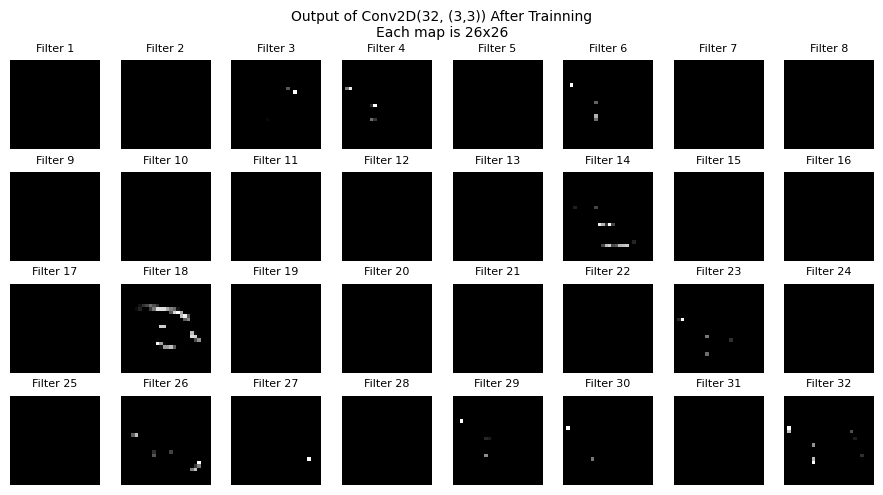

In [14]:
# FIGURE 3: THE 32 OUTPUT FEATURE MAPS
fig3, axes3 = plt.subplots(4, 8, figsize=(9, 5))
fig3.suptitle(f"Output of Conv2D(32, (3,3)) After Trainning\nEach map is 26x26", fontsize=10)

for i, ax in enumerate(axes3.flat):
    f_map = fit_feature_maps[0, :, :, i]
    ax.imshow(f_map, cmap='gray')
    ax.axis('off')
    ax.set_title(f"Filter {i+1}", fontsize=8)

plt.tight_layout()
plt.subplots_adjust(top=0.88) # Make room for the suptitle
plt.show()

7-What do those Filter Matrix mean
* We already know that the the dot product of the a filter matrix and a image slice will be a large postive number if they are similiar, and 0 by ReLU activation for other cases.
* So we can plot each filter matrix as a heatmap to illustrate what kind of feature it represents.
* In the feature map above, the brighter part means `high similarity` to each filter matrix.

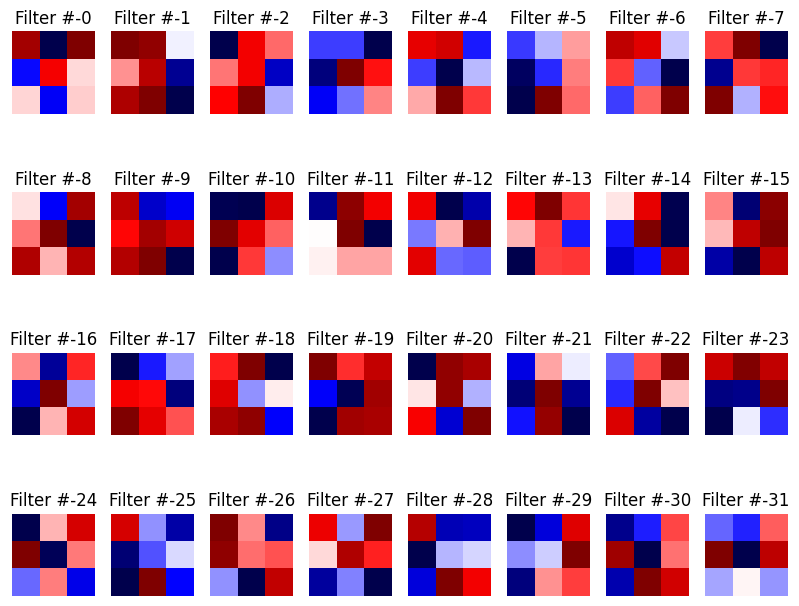

In [17]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Get the weights from the layer you named 'target_conv_layer'
# weights[0] are the filter kernels, weights[1] are the biases
filters, biases = fit_model.get_layer('target_conv_layer').get_weights()

# 2. Normalize filter values to 0-1 so they look good as a heatmap
f_min, f_max = filters.min(), filters.max()
filters = (filters - f_min) / (f_max - f_min)

# 3. Plot all 32 filters
plt.figure(figsize=(10, 8))
for i in range(32):
    # Get the ith filter (3x3)
    f = filters[:, :, 0, i]
    
    plt.subplot(4, 8, i+1) # 4 rows, 8 columns
    plt.imshow(f, cmap='seismic') # or'viridis' or 'gray' are great for heatmaps
    plt.axis('off')
    plt.title(f'Filter #-{i}')

plt.show()

### Apr-03-2026

#### Understanding Binary Cross-Entropy (BCE) Loss Function
* Simple average error, commonly used ones like:
  * Mean Squared Error (MSE):$\dfrac{1}{n}\sum_{i=1}^n (\hat{y}_i - y_i)^2$
  * Mean Absolute Error (MAE): $\dfrac{1}{n}\sum_{i=1}^n |\hat{y}_i - y_i|$
* Good for Regression (predicting continuous numbers like house prices)
* They are avoided for binary classification:
  * Non-Convexity: When paired with a Sigmoid activation, MSE creates a "wavy" loss surface with many local minima, making it hard for Gradient Descent to find the global best.
  * Vanishing Gradients: If a prediction is confidently wrong (e.g., predicting 0.99 when the truth is 0), the Sigmoid gradient becomes very flat. MSE doesn't punish this enough, so the model learns incredibly slowly.
* Binary Cross-Entropy (BCE) is generally preferred for binary classification.
  * BCE is defined as:$(-\dfrac{1}{n}) \sum_{i=1}^n \left[y_i \cdot \log(\hat{y}_i) + (1-y_i) \cdot \log(1-\hat{y}_i)\right]$
    * True label $y$, binary 0 or 1
    * Predicted probability $\hat{y} = \sigma(z) = \dfrac{1}{1 + e^{-z}}$, in range $[0, 1]$; note the Logit ($z$)
  * BCE measures how close a model’s predicted probability is to the true label.
    * If the true label $y = 1$: The second half of the formula $(1 - y)$ becomes zero. You are left only with $-\log(\hat{y})$. As your prediction $\hat{y}$ gets closer to 1, the loss drops to 0.
    * If the true label $y = 0$: The first half of the formula becomes zero. You are left only with $-\log(1 - \hat{y})$. As your prediction $\hat{y}$ gets closer to 0, the loss drops to 0.
    * If the model is "confidently wrong" (e.g., $y=1$ but $\hat{y}=0.01$), the logarithm creates an exponentially high penalty, forcing the model to change its weights quickly.





#### Review the SciKit-Learn Pipeline
* with IRIS dataset
* understanding `GridSearchCV`, it's just configuration
  * `pipeline`: StandardScaler → PCA → LogisticRegression
  *  train this pipeline many times with every combination of parameter settings
    * `"pca__n_components"` → targets the PCA step
    * `"clf__C"` → targets Logistic Regression
    * note the `__` (double underscore)
  * `cv=5` (5-fold Cross Validation)
  * `scoring="accuracy"`
    * `"f1"`
    * `"precision"`
    * `"recall"`
  * `n_jobs=-1`: use all CPU cores
  * The actual work happens here: `grid.fit(X_train, y_train)`


In [9]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

# Load data
X, y = load_iris(return_X_y=True)

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Pipeline
pipeline = Pipeline([("scaler", StandardScaler()),
                     ("pca", PCA()),
                     ("clf", LogisticRegression(max_iter=1000))
                    ])

# Param grid
# Small C → stronger regularization
# Large C → weaker regularization
param_grid = {"pca__n_components": [2, 3, 4],
              "clf__C": [0.01, 0.1, 1, 10],
             }

# GridSearchCV configuration
# n_jobs=-1: use all CPU cores
grid = GridSearchCV(pipeline,
                    param_grid,
                    cv=5,
                    scoring="accuracy",
                    n_jobs=-1,
                    return_train_score=True
                   )

# Fit,  actual work happens here
grid.fit(X_train, y_train)

# Convert cv_results_ to DataFrame
df = pd.DataFrame(grid.cv_results_)

# Select important columns for readability
cols = ["param_pca__n_components",
        "param_clf__C",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "rank_test_score"
       ]

df_results = df[cols].sort_values(by="rank_test_score")
df_results

,param_pca__n_components,param_clf__C,mean_test_score,std_test_score,mean_train_score,rank_test_score
7,3,1.00,0.958333,0.045644,0.970833,1
8,4,1.00,0.958333,0.045644,0.970833,1
11,4,10.00,0.958333,0.064550,0.981250,1
10,3,10.00,0.950000,0.061237,0.979167,4
6,2,1.00,0.916667,0.052705,0.927083,5
9,2,10.00,0.916667,0.074536,0.927083,5
4,3,0.10,0.900000,0.077280,0.914583,7
5,4,0.10,0.900000,0.077280,0.912500,7
0,2,0.01,0.858333,0.042492,0.841667,9
1,3,0.01,0.850000,0.056519,0.858333,10


#### Review of Weight Regularization
* $\text{Total Loss} = \text{Data Loss} + \lambda \cdot \text{Regularization Term}$
  * Data Loss → how wrong predictions are (e.g., cross-entropy)
  * λ (lambda) → controls strength of regularization
  * $C$ is the inverse of regularization strength ($C = 1/\lambda$)
  * Regularization Term → penalizes large weights
* L2 Regularization (Ridge), Sci-Kit Learn default
  * $\text{Loss} = L(y, \hat{y}) + \lambda \sum_{i=1}^{n} w_i^2$
  * Penalizes squared weights
  * Encourages small, smooth weights
  * Rarely makes weights exactly zero
  * Keeps all features, but shrinks them
* L1 Regularization (Lasso)
  * $\text{Loss} = L(y, \hat{y}) + \lambda \sum_{i=1}^{n} |w_i|$
  * Penalizes absolute values of weights
  * Can push weights exactly to 0
  * Reduce features
* Elastic Net, combination of L1 and L2
  * $\text{Loss} = L(y, \hat{y}) + \lambda_1 \sum |w_i| + \lambda_2 \sum w_i^2$
  * $\lambda \left( \alpha \sum |w_i| + (1 - \alpha) \sum w_i^2 \right)$
  * `LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5)`
    * `l1_ratio = 1` → pure L1
    * `l1_ratio = 0` → pure L2


### Apr-07-2026

#### How to Handle Overfitting in TF2
In TensorFlow 2, overfitting occurs when your model starts "memorizing" noise in the training data rather than learning general patterns, leading to high training accuracy but poor validation performance.

Why don't we just Simplify the Model Architecture? 
* Same case with Sci-Kit Learn models, overfitting starts to occur when there are too many features. Yet, the best strategy is to start with a feature-rich model and then refine it with weight regularization and cross-validation.

In TF2, overfitting is best addressed by training a high-capacity model and applying these approaches:
* Dropout
* Early Stopping
* Regularization (L2/L1)

1-Dropout, randomly sets a fraction of neurons’ output activations to 0 during each training step. For the neurons dropped in that step, their associated weights and biases are not updated by gradient descent because no gradient flows through them. During inference, dropout is disabled, and all neurons remain active.
```python
import tensorflow as tf
model = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.5), # 50% of neurons are randomly disabled each step
    tf.keras.layers.Dense(1)
])
```

2-Early stopping, halts training when the validation loss stops improving for n consecutive epochs, where n is the patience value.

```python
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Instantiate EarlyStopping: monitors val_loss, stops after 30 epochs of no improvement
early_stopping = EarlyStopping(monitor='val_loss', 
                               mode='min', 
                               patience=30)

# Instantiate ReduceLROnPlateau: reduces LR by factor of 0.2 after 20 epochs of no improvement
learning_rate_reduction = ReduceLROnPlateau(monitor='val_loss', 
                                            factor=0.2, 
                                            patience=20)

# Train with added callbacks parameters
history_with_callback = model.fit(train_data, train_targets, epochs=800, validation_split=0.15,
                                  callbacks=[early_stopping, learning_rate_reduction],
                                  verbose=0)
```

3-Weight Regularization (L1/L2), adds a penalty term to the loss function, similar to regularization in Scikit-learn.
* L2 Regularization (Weight Decay): penalizes the square of the weights, encouraging them to remain small and distributed.
* L1 Regularization: penalizes the absolute value of the weights, which can drive some weights exactly to zero and thus promote sparsity (weight is 0, thus that neuron not used).
```python
from tensorflow.keras import regularizers
model = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001))
])
```

#### Understanding the Demo Code

1-the model setup, with regularization, dropout layer, and BatchNormalization
```python
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2

# Define the L2 regularizer using the weight_decay argument
regularizer = l2(weight_decay = 0.001)

model = Sequential([
    # Layer 1: 64 units
    # kernel_initializer, He uniform weights, Named after Kaiming He
    # bias_initializer, biases initialized to 1
    Dense(64, activation='relu', input_shape=input_shape,
          kernel_initializer='he_uniform',
          bias_initializer=tf.keras.initializers.Ones(),
          kernel_regularizer=regularizer),
    
    # Layers 2-3: 128 units + L2
    Dense(128, activation='relu', kernel_regularizer=regularizer),
    Dense(128, activation='relu', kernel_regularizer=regularizer),
    
    # Dropout layer after the 3rd Dense layer
    Dropout(dropout_rate = 0.3),
    
    # Layers 4-5: 128 units + L2
    Dense(128, activation='relu', kernel_regularizer=regularizer),
    Dense(128, activation='relu', kernel_regularizer=regularizer),
    
    # Batch Normalisation layer
    BatchNormalization(),
    
    # Layers 6-7: 64 units + L2
    Dense(64, activation='relu', kernel_regularizer=regularizer),
    Dense(64, activation='relu', kernel_regularizer=regularizer),
    
    # Another Dropout layer
    Dropout(dropout_rate = 0.3),
    
    # Layers 8-9: 64 units + L2
    Dense(64, activation='relu', kernel_regularizer=regularizer),
    Dense(64, activation='relu', kernel_regularizer=regularizer),
    
    # Layer 10: Final 3-way softmax (No L2 regularisation per requirement)
    Dense(3, activation='softmax')
])
```

2-compile the model
```python
from tensorflow.keras.optimizers import Adam

# Initialize the Adam optimizer with the specified learning rate
#  a "version" of Gradient Descent
model.compile(
    optimizer = Adam(learning_rate=0.0001),
    loss = 'categorical_crossentropy',
    metrics = ['accuracy']
)
```

3-train the model, keep the log in history
```python
# simple, not cross validation, with 15% validation split
history = model.fit(
    train_data, 
    train_targets, 
    epochs = 800, 
    batch_size = 40, 
    validation_split = 0.15,
    verbose = 0
)
```

4-the regularisation would help to reduce the overfitting of the network.

Next, we will incorporate callbacks into a new training run that implements early stopping (stop at 180 instead of 800 epoch) and learning rate reduction on plateaux.

```python
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
# Instantiate EarlyStopping: monitors val_loss, stops after 30 epochs of no improvement
early_stopping = EarlyStopping(monitor='val_loss', 
                               mode='min', 
                               patience=30)

# Instantiate ReduceLROnPlateau: reduces LR by factor of 0.2 after 20 epochs of no improvement
learning_rate_reduction = ReduceLROnPlateau(monitor='val_loss', 
                                            factor=0.2, 
                                            patience=20)

# Train with added callbacks parameters
history_with_callback = model.fit(train_data, train_targets, epochs=800, validation_split=0.15,
                                  callbacks=[early_stopping, learning_rate_reduction],
                                  verbose=0)

```

5-Comparing Callback with SciKit-Learn's Convergence Check (Tolerance)
| Feature | Scikit-Learn | Keras / TensorFlow |
| :--- | :--- | :--- |
| **Max Iterations** | `max_iter=200` | `epochs=200` |
| **Convergence Limit** | `tol=1e-4` | `min_delta=1e-4` (inside Callback) |
| **Patience** | `n_iter_no_change=10` | `patience=10` (inside Callback) |
| **Behavior** | Stops at convergence OR max_iter. | Stops **only** at `epochs` unless Callback is added. |


### Apr-08-2026

#### Understanding Class, method overriding, subclassing
1-With a method in a parent Class
```python
class Animal:
    def speak(self):
        print("Some sound")
a = Animal()
a.speak()   # Some sound
```
a child class can override `def speak(self):`, by having the same funciton name
```python
class Dog(Animal):
    def speak(self):
        print("Bark")
d = Dog()
d.speak()   # Bark
```
2-You can also extend the parent behavior, not completely replace it. Having the same function name, but adding `super().greet()`.
```python
class Parent:
    def greet(self):
        print("Hello from Parent")

class Child(Parent):
    def greet(self):
        super().greet()
        print("Hello from Child")

c = Child()
c.greet()  # Hello from Parent, and,  Hello from Child
```
3-The gentleman's agreement
* Internal Funciton `_parentFunc`
* Hide with Dunder `__parentFunc`

With regard to the Tutorial example `class TrainingCallback(Callback):`
```python
# TF2 has this method in its stock Callback class
class Callback:
    def on_train_begin(self, logs=None):
        pass   # The stock pass does nothing
# We can modify how it behaves with Method Overriding
from tensorflow.keras.callbacks import Callback
class MyCallback(Callback):
    def on_train_begin(self, logs=None):
        print("Training started")   # The stock pass, is now overridden with "Training started"
```


### Apr-21-2026

#### Keras, from Sequential API to Functional API: the flow of data through layers 
* Sequential API: The 'Fixed List ', designed for a simple, layer-by-layer stack where each layer has exactly one input tensor and one output tensor.
  * Limitation: It cannot handle multiple inputs, multiple outputs, or shared layers. 
* Functional API: The 'Directed Graph', that treats layers as functions that take a tensor as an input and return another tensor as output.
  * This creates a Directed Acyclic Graph (DAG) of layers.
  * Multiple Inputs/Outputs: You can easily build models that take different types of data
    * image and text
    * predict multiple targets at once
  * Shared Layers: A single layer can be reused multiple times in the same model

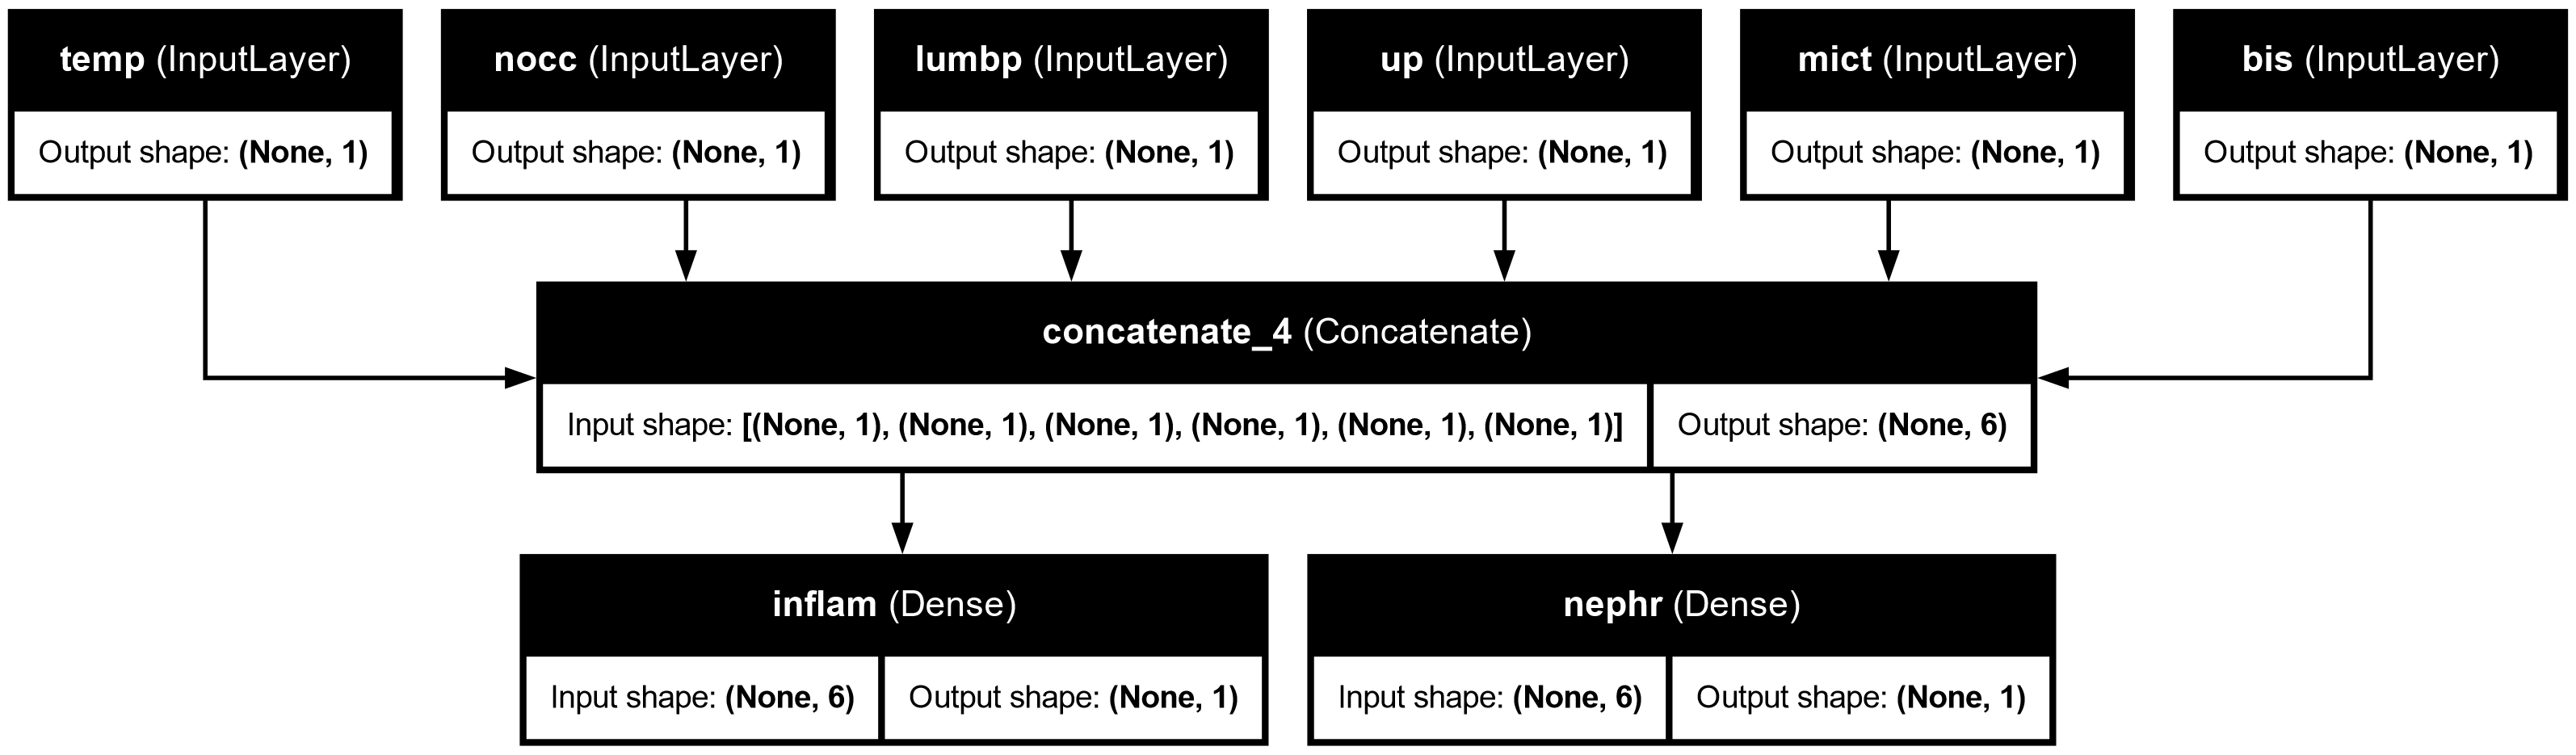

In [6]:
# Here we will create and plot the Model for acute inflammations classifier
# to illustrate the outline of a Functional API model
import tensorflow as tf
from tensorflow.keras import Input, layers

# prepare the 6 input layers
shape_inputs = (1,)
temperature = Input(shape=shape_inputs, name='temp')
nausea_occurence = Input(shape=shape_inputs, name='nocc')
lumbar_pain = Input(shape=shape_inputs, name='lumbp')
urine_pushing = Input(shape=shape_inputs, name='up')
micturition_pains = Input(shape=shape_inputs, name='mict')
bis = Input(shape=shape_inputs, name='bis')

list_inputs = [temperature, nausea_occurence, lumbar_pain, urine_pushing, micturition_pains, bis]

# as Dense layer would expect a single tensor input, we concatenate all 6 layers into 1
x = layers.Concatenate()(list_inputs)

# Use a logistic regression classifier for disease prediction
# note the same input layer, x, has been used twice for two Output layers
inflammation_pred = layers.Dense(1, activation='sigmoid', name='inflam')(x)
nephritis_pred = layers.Dense(1, activation='sigmoid', name='nephr')(x)

list_outputs = [inflammation_pred, nephritis_pred]

# Create the model object
model = tf.keras.Model(inputs=list_inputs, outputs=list_outputs)

# Display the multiple input/output model
# note this is requried: to_file='model.png'
from tensorflow.keras.utils import plot_model

plot_model(model, to_file='model.png', show_shapes=True, show_layer_names=True)

### Apr-22-2026

#### Loading Weights, Freezing Layers, and Repurposing Models by Transfer Learning
* Loading Weights
  * Sequential API loads weights by position (default), requiring matching layer order and compatible weight shapes
    * adding, removing, or shifting layers causes silent mismatches (no error, but just won't work).
  * Functional API, layers are named objects, can load by name
* Freezing Layers: Freezing prevents weights from being updated during training by setting `layer.trainable = False`
  * Both Functional API and Sequential API can freeze layers
    * check syntax for detail
* Repurposing (Transfer Learning): both API work, but the Functional API shines
  * In Sequential: To repurpose, you often create a new Sequential model that "wraps" a pre-trained base model as its first layer (the base model is treated as a single layer object), followed by your new classification layers.
  * In Functional: You "call" the pre-trained model on your new input, take its output, and feed it directly into new layers. This allows you to tap into middle layers of a model (e.g., using features from the middle of a ResNet) which is much harder to do in Sequential. 


1-Checkpoints
*  Using checkpoints is the standard way to protect your progress during long training sessions and enables you to run inference later without retraining.
```python
# Create Tensorflow checkpoint object
from tensorflow.keras.callbacks import ModelCheckpoint

checkpoint = ModelCheckpoint(
    filepath='model_checkpoints/ckpt_{epoch}.weights.h5',
    save_freq='epoch',
    save_weights_only=True,
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

# Fit model, with simple checkpoint which saves (and overwrites) model weights every epoch
model.fit(x=x_train, y=y_train, epochs=3, callbacks=[checkpoint])

# Load weights to a new Model Instance, to save the training time.
model_new.load_weights('model_checkpoints/ckpt_3.weights.h5')
```
* Create Tensorflow checkpoint object with epoch and batch details
```python
# Create Tensorflow checkpoint object, specify epoch and batch details
checkpoint_5000 = ModelCheckpoint(
    filepath='model_checkpoints_5000/ckpt_5000_epoch_{epoch:02d}_{batch:04d}.weights.h5',
    save_weights_only=True,
    save_freq=5000,
    verbose=1
)

# Fit model with that specific checkpoint
model.fit(x=x_train, y=y_train, epochs=3,
           validation_data=(x_test, y_test), batch_size=10,
           callbacks=[checkpoint_5000])
```

2-Save the entire model
* with or without Checkpoints
 ```python
from tensorflow.keras.callbacks import ModelCheckpoint

# Save the entire model with checkpoints
checkpoint_path = 'model_checkpoints/model_epoch_{epoch:02d}.keras'
checkpoint = ModelCheckpoint(filepath=checkpoint_path, 
                             save_weights_only = False, 
                             save_freq = 'epoch', 
                             verbose=0)

# Save from a trained model
model_trained.save('my_trained_model.keras')
```
* Load the saved model to a new instance
```python
from tensorflow.keras.models import load_model
model_new = load_model('model_checkpoints/model_epoch_03.keras')
# or
model_new = load_model('my_trained_model.keras')
```


3-Demo with `ResNet50`
* ResNet50:  50 layers organized into 4 stages, addressing the vanishing gradient problem
* Allow to use `model_load.summary()` to check every layer
```python
from tensorflow.keras.models import load_model
from tensorflow.keras.applications import ResNet50

model_load = ResNet50(weights='imagenet')

# Not Necessarily needed to save then load
#model_load.save('model_checkpoints/resnet50_model.keras')
#model_new = load_model('model_checkpoints/resnet50_model.keras')

model_new = model_load
```
* Prepare new image for prediction, using `model_new`
```python
# Import 3 sample ImageNet images
from tensorflow.keras.utils import load_img

lemon_img = load_img('lemon.jpg', target_size=(224, 224))
viaduct_img = load_img('viaduct.jpg', target_size=(224, 224))
water_tower_img = load_img('water_tower.jpg', target_size=(224, 224))

# Useful function: presents top 5 predictions and probabilities
from tensorflow.keras.preprocessing.image import img_to_array
from tensorflow.keras.applications.resnet50 import preprocess_input, decode_predictions
import numpy as np
import pandas as pd

def get_top_5_predictions(img):
    x = img_to_array(img)[np.newaxis, ...]
    x = preprocess_input(x)
    preds = decode_predictions(model_new.predict(x), top=5)
    top_preds = pd.DataFrame(columns=['prediction', 'probability'],
                             index=np.arange(5)+1)
    for i in range(5):
        top_preds.loc[i+1, 'prediction'] = preds[0][i][1]
        top_preds.loc[i+1, 'probability'] = preds[0][i][2]
    return top_preds
```

4-Demo with Tensorflow Hub, MobileNet v1 model
* Transfer Learning way, use as a whole layer, can not check each layers
```python
import tensorflow as tf
import tensorflow_hub as hub
import requests
from tensorflow import keras

# Download ImageNet Categories
labels_url = "https://storage.googleapis.com/download.tensorflow.org/data/ImageNetLabels.txt"
response = requests.get(labels_url)
# The first label is often 'background', so we split and store
categories = response.text.splitlines()

# Load the model from Tensorflow Hub
module_url = "https://tfhub.dev/google/imagenet/mobilenet_v1_050_160/classification/4"
model = keras.Sequential([hub.KerasLayer(module_url)])

#model = keras.Sequential([hub.KerasLayer(module_url, trainable=False),   # whole model = 1 layer
#                          Dense(10, activation='softmax')                # add your head on top
#                          ])

model.build(input_shape=[None, 160, 160, 3])
```

5-Freeze layers with Sequential API
* set `trainable=False` inside the layer parameters
```python
# Build the model
from tensorflow.keras import layers, Sequential

model = Sequential([
    layers.Dense(
        units=4, 
        input_shape=(4,), 
        activation='relu', 
        kernel_initializer='random_uniform',
        bias_initializer='ones', 
        trainable=False,
        name='frozen_input_layer'
    ),
    layers.Dense(
        units=2, 
        activation='relu', 
        kernel_initializer='lecun_normal', 
        bias_initializer='ones',
        name='hidden_layer_1'
    ),
    layers.Dense(
        units=4, 
        activation='softmax',
        name='output_layer'
    ),
])
```
* index layer and set `model.layers[1].trainable = False`
* Don't forget to `compile`

6-Code Timbits
* Some Bash codes
```python
! ls -lh model_checkpoints
! rm -r model_checkpoints
! rm my_model.h5
```
* Upload files to CoLab
```python
# upload 3 sample ImageNet images from local drive
from google.colab import files
uploaded = files.upload()
```


### Apr-23-2026

#### Understanding The Functional API

1-Understanding the `acute inflammations` demo dataset.
* This dataset has 8 columns, 6 are inputs
  * Temperature of patient : 35C-42C
  * Occurrence of nausea : yes/no
  * Lumbar pain : yes/no
  * Urine pushing (continuous need for urination) : yes/no
  * Micturition pains : yes/no
  * Burning of urethra, itch, swelling of urethra outlet : yes/no
* and 2 are outputs:
  * decision 1: Inflammation of urinary bladder : yes/no
  * decision 2: Nephritis of renal pelvis origin : yes/no

In [2]:
import pandas as pd

columns = ["Temperature", "Nausea", "Lumbar_pain", "Urine_pushing",
           "Micturition_pains", "Urethra_burning", "Bladder_inflammation", "Nephritis"]
data = [[35.5, 'no', 'yes', 'no', 'no', 'no', 'no', 'no'],
        [35.9, 'no', 'no', 'yes', 'yes', 'yes', 'yes', 'no'],
        [35.9, 'no', 'yes', 'no', 'no', 'no', 'no', 'no'],
        [36.0, 'no', 'no', 'yes', 'yes', 'yes', 'yes', 'no'],
        [36.0, 'no', 'yes', 'no', 'no', 'no', 'no', 'no'],
        [36.0, 'no', 'yes', 'no', 'no', 'no', 'no', 'no'],
        [36.2, 'no', 'no', 'yes', 'yes', 'yes', 'yes', 'no'],
        [36.2, 'no', 'yes', 'no', 'no', 'no', 'no', 'no'],
        [36.3, 'no', 'no', 'yes', 'yes', 'yes', 'yes', 'no']]
df = pd.DataFrame(data, columns=columns)

# Convert yes/no to 1/0 and ensure the dtype is integer
df = df.map(lambda x: 1 if x == 'yes' else (0 if x == 'no' else x))

dataset = df.values
dataset.shape


(9, 8)

2-How Functional API builds the input layers
* `Input()` is a function that returns a tensor, and it also creates an InputLayer object
* so now, each feature column can be defined as a separate input layer using `Input()`.
  * With this demo dataset,6 columns becomes 6 input tensors.
  * Each input has shape `(1,)` because each feature contains a single value per sample
  * and each input is also given a name, used as dictionary key
  * so, training data can be fed into the model as a dictionary `{'temp': 36.5, 'nocc': 0, ...}`
```python
# these are all seperate layers
from tensorflow.keras import Input, layers

shape_inputs = (1,)

temperature = Input(shape=shape_inputs, name='temp')
nausea_occurence = Input(shape=shape_inputs, name='nocc')
lumbar_pain = Input(shape=shape_inputs, name='lumbp')
urine_pushing = Input(shape=shape_inputs, name='up')
micturition_pains = Input(shape=shape_inputs, name='mict')
bis = Input(shape=shape_inputs, name='bis')
```
* After defining these separate input layers, we combine them with `layers.concatenate()`.
  * Dense layers expect a single tensor, so we use `layers.concatenate` to  "glues" those six separate layers into a single tensor.
```python
# these are the input layers, 
# to pass to the model = tf.keras.Model(inputs=list_inputs, outputs=list_outputs)
list_inputs = [temperature, nausea_occurence, lumbar_pain, urine_pushing, micturition_pains, bis]

# because Dense layers expect a single tensor
x = layers.concatenate(list_inputs)
```

3-A typical outline for building a model with the Functional API
* In the Keras Functional API, a model is built by
  * defining the input layers
  * connecting them to other layers
  * then specifying the final outputs.
```python
# with x from preivious cell
# Connect the combined input tensor to two prediction layers
inflammation_pred = layers.Dense(1, activation='sigmoid', name='inflam')(x)
nephritis_pred = layers.Dense(1, activation='sigmoid', name='nephr')(x)

# Put the outputs into a list
list_outputs = [inflammation_pred, nephritis_pred]

# Create the final model
# Note the inputs list and outputs list
model = tf.keras.Model(inputs=list_inputs, outputs=list_outputs)
```
* This demo shows one of the main advantages of the Functional API:
  * the same intermediate tensor can be reused by multiple output layers.
  * as a result, the model can produce more than one prediction from the same set of inputs.
* Plot the model to better show the outline
```python
# Display the multiple input/output model
# require Graphviz(extra installation), and Pydot(Module installation)
tf.keras.utils.plot_model(model, 'multi_input_output_model.png', show_shapes=True, show_layer_names=True)
``` 

4-multi-output model: compile, fit, and evaluate with dictionaries
* In a multi-output model, each output layer can have its own loss function and evaluation metric.
  * When compiling the model, dictionaries can be used to match each loss and metric to the corresponding output layer by name.
  * To train the model, the input data can also be provided as a dictionary, where each key matches the name of an input layer.
  * Similarly, the target values can be passed as a dictionary, where each key matches the name of an output layer.
  * So is the same case with evaluation: the test inputs and outputs can also be passed as dictionaries.
```python
# Compile the model, note how to use dictionary to assign different loss and metrics
from tensorflow.keras.optimizers import RMSprop
model.compile(optimizer=RMSprop(learning_rate=0.001),
              loss={'inflam': 'binary_crossentropy', 'nephr': 'binary_crossentropy'},
              metrics={'inflam': 'acc', 'nephr': 'acc'}
              )

# Train the model, note how dictionary is used
inputs_train = {'temp': temp_train, 'nocc': nocc_train, 'lumbp': lumbp_train,
                'up': up_train, 'mict': mict_train, 'bis': bis_train}
outputs_train = {'inflam': inflam_train, 'nephr': nephr_train}

history = model.fit(inputs_train, outputs_train, epochs=1000, batch_size=128, verbose=False)

# Evaluate the model
model.evaluate([temp_test, nocc_test, lumbp_test, up_test, mict_test, bis_test], [inflam_test, nephr_test])

# Plot the learning curves
import matplotlib.pyplot as plt

plt.plot(history.history['inflam_acc'], label='Inflammation Accuracy')
plt.plot(history.history['nephr_acc'], label='Nephritis Accuracy')
plt.legend()
plt.show()
````

### Apr-24-2026

#### TF2 Objects: Variable and Tensor

1-Variable objects: `tf.Variable()`
```python
# Create Variable objects of different type with tf.Variable
strings = tf.Variable(["Hello world!"], tf.string)
floats  = tf.Variable([3.14159, 2.71828], tf.float64)
ints = tf.Variable([1, 2, 3], tf.int32)
complexs = tf.Variable([25.9 - 7.39j, 1.23 - 4.91j], tf.complex128)
```

2-Tensor objects: `tf.constant()`/`tf.convert_to_tensor()`
```python
# Create a Tensor, with type float32
x = tf.constant([[1, 2, 3], [4, 5, 6], [7, 8, 9]], dtype=tf.float32)

# Create a numpy array
coeffs = np.arange(16)
# Initialise shapes
shape = [8, 2]
# Create Tensors with given shape
a = tf.constant(coeffs, shape=shape)

# oneliner
a = tf.constant(np.arange(16), shape=[8,2])
# reshape it
a2 = tf.reshape(t, [4, 4])
```

3-Variables are mutable, and Tensors are not. Here's a demo to differenciate
  * When you run w = v + 1, TensorFlow performs an operation and creates a Tensor, The calculation creates a Tensor: standard immutable tf.Tensor.
  * Tensors don't have the .assign() method: Only tf.Variable objects have the .assign_sub() method.
```python
v = tf.Variable(0.0)
v.assign_add(1.0) # v is now 1.0
v.assign_sub(1.0) # v is back to 0.0

w = v + 1.0 # w is now 1.0, an is immuatable tensor
# This won't work
w.assign_sub(1.0) #  cause an AttributeError

# This works
v = tf.Variable(0.0)
w = tf.Variable(v + 1.0) # w is a new, independent Variable
w.assign_sub(1.0)
```

4-Useful Tensor operations, much like that in Numpy
* Here with the rank as an exmple. Check the web for all other operations.
```python
# Get the rank of a Tensor
rank = tf.rank(t)
```
| Rank | Also Called | Example |
|---|---|---|
| 0 | Scalar | A single number: `5` |
| 1 | Vector | A list: `[1, 2, 3]` |
| 2 | Matrix | A table: `[[1,2],[3,4]]` |
| 3 | 3D Tensor | A cube of numbers |
| N | N-D Tensor | N nested dimensions |


####  Why Bother: TensorFlow Variables vs NumPy
On the surface they look very similar, but TensorFlow has very specific reasons to exist. Here's the full picture:
* TensorFlow is built *on top of* NumPy `ideas`
  * NumPy is a great math tool.
  * TensorFlow is a complete machine learning engine.
  * As your models grow bigger and more complex, NumPy simply can't keep up — TensorFlow is built for exactly that scale.
* GPU / TPU Acceleration
  * NumPy — Vectrorization, but CPU only, always
  * TensorFlow — runs on GPU/TPU automatically
  * TensorFlow essentially takes the same vectorized array math idea from NumPy and extends it to run across GPU/TPU hardware
* Automatic Differentiation (`tf.GradientTape`)
  * TensorFlow can automatically compute gradients — NumPy cannot.
  * Gradients are ESSENTIAL for training neural networks (backpropagation).
  * You'd have to compute every derivative by hand with NumPy
* `tf.Variable` is Trainable — NumPy arrays are not
  * `tf.Variable` tracks its own history and is mutable by design for training loops
  * NumPy arrays are just passive data containers — no training awareness
* Building Computation Graphs (`tf.function`)
  * TensorFlow can compile your Python code into an optimized static graph
  * This makes repeated operations (like training steps) much faster
  * NumPy re-executes Python line by line every time — no compilation
* Distributed Computing
  * TensorFlow is built for large-scale, distributed training
    * NumPy runs on a single CPU core — no distribution support
    * Multi-machine training is the most common real-world use of  distributed training


#### Accessing model layers and their outputs
* demo with the `VGG19` model
  * VGG: the Visual Geometry Group, with 19 layers
  * from the `keras.applications` library
  * trained on the ImageNet database
  * to classify images into 1000 object categories

1-Load the `VGG19` base model, and assign the inputs and layers to variables
```python
# Load the VGG19 base model
from tensorflow.keras.applications import VGG19
vgg_model = VGG19()

# Get the inputs, layers and display the summary
vgg_input = vgg_model.input
vgg_layers = vgg_model.layers
vgg_model.summary()
```

2-Build a wrapper_model around the `VGG19` base_model, to access the layer outputs
```python
from tensorflow.keras.models import Model
# Build a wrapper_model that returns the layer outputs
layer_outputs = [layer.output for layer in vgg_layers]
wrapper_model = Model(inputs=vgg_input, outputs=layer_outputs)
```
understanding `layer.output`
| Attribute | Returns | Use Case |
|---|---|---|
| `layer.name` | String | Identify the layer |
| `layer.dtype` | String | Check data type |
| `layer.trainable` | Bool | Check if frozen |
| `layer.input` | Tensor | Get input tensor |
| `layer.output` | Tensor | Get output tensor |
| `layer.input_shape` | Tuple | Check input dimensions |
| `layer.output_shape` | Tuple | Check output dimensions |
| `layer.weights` | List of tensors | Inspect learned weights |
| `layer.trainable_weights` | List of tensors | See what will be updated |
| `layer.non_trainable_weights` | List of tensors | See what is frozen |
| `layer.count_params()` | Int | Count parameters |
| `layer.get_config()` | Dict | Full layer configuration |

3-Prepare the image for inference
```python
# This shows what the input should be formated
img = np.random.random((1, 224, 224, 3)).astype('float32')

# Preprocess any image, to meet the input format
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.preprocessing import image

img_path = 'cool_cat.jpg'
img = image.load_img(img_path, target_size=(224, 224))
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)
x = preprocess_input(x)
```

4-Understanding `f1` and `imgs` from `extracted_features[0] = raw image (unchanged)`
* So far, layer `[0]` is the input layer, it hasn't transformed anything yet.
* `imgs` is just the original input image x
* Loop to plot each chanel in grayscale
```python
# The first whole process
from tensorflow.keras.applications import VGG19
from tensorflow.keras.models import Model
vgg_model = VGG19()
vgg_input = vgg_model.input
vgg_layers = vgg_model.layers

layer_outputs = [layer.output for layer in vgg_layers]
wrapper_model = Model(inputs=vgg_input, outputs=layer_outputs)

# for the pre-processed image x
extracted_features = wrapper_model(x)

# what are these
# layer[0] is the input layer
f1 = extracted_features[0]
# f1 shape: (1, 224, 224, 3)
# 1     = one image (batch size)
# 224   = image height
# 224   = image width
# 3     = RGB channels

imgs = f1[0, :, :]
# shape: (224, 224, 3)
# [0]  = grab the first (only) image from the batch
# [:,:]= take ALL rows and ALL columns
# This gives you the raw image as a 224x224x3 array


for n in range(imgs.shape[2]):
  ax = plt.subplot(1, 3, n+1)
  plt.imshow(imgs[:, :, n], cmap='gray')
# imgs.shape      # (224, 224, 3)
# imgs.shape[0]   # 224  ← height
# imgs.shape[1]   # 224  ← width
# imgs.shape[2]   # 3    ← RGB chanels

# loop to plot a grayscale for each chanel 
# imgs[:, :, 0]   # Red   channel
# imgs[:, :, 1]   # Green channel
# imgs[:, :, 2]   # Blue  channel


```

5-VGG19 is a 19-layer deep network — each layer transforms the image into increasingly abstract representations:
* Outputs from some layers
| Layer | What it outputs | Shape example |
|---|---|---|
| `[0]` Input | Raw image | `(1, 224, 224, 3)` |
| `[1]` Conv1 | Edge feature maps, detects edges, basic lines | `(1, 224, 224, 64)` |
| `[2]` Conv2 | More edge maps, detects textures, corners | `(1, 224, 224, 64)` |
| `[5]` Conv deeper | Texture maps, detects high-level objects | `(1, 112, 112, 128)` |
| `[18]` Dense | Class scores, final classification | `(1, 1000)` |

```python
# for layer[1]
f2 = extracted_features[1] # f2.shape:  (1, 224, 224, 64)
```
* Each layer can also be accessed with layer name
```python
# build a wrapper_model to get the layer 'block5_conv4' output
extracted_features_block5_conv4 = Model(inputs=features.input, 
                                        outputs=features.get_layer('block5_conv4').output)

block5_conv4_pool_features = extracted_features_block5_conv4.predict(x)
```

### Apr-26-2026

#### Transfer Learning
* Instantiate: Load a pre-trained base_model
  * we will use the pre-trained MobileNet V2 model,from Keras Applications
* Attach: Add new trainable layers (the "head") for your specific task.
* Freeze: Set base_model.trainable = False.
* Recompile: Critical step—you must call model.compile() after changing any trainable flags to lock them in. 

1-Download the base_model, modify it to keep only the feature_extractor_layers

In [17]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.applications import MobileNetV2

# download the base model
base_model = MobileNetV2(weights='imagenet')

# keep the same input layer
old_input = base_model.input

# keep only the feature_extractor_layers
# upto the last pooling layer before classification
# new_output = base_model.get_layer('global_average_pooling2d_6').output
new_output = base_model.layers[-2].output

# Create a new model using the original input and the new pooling output
feature_extractor_model = Model(inputs=old_input, outputs=new_output, name="mobilenetv2_feature_extractor")

len(feature_extractor_model.layers)

155

2-Use Sequential API to create a new_model, and use the downloaded base_model as layer_0

```python
from tensorflow.keras.models import  Sequential, Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout

new_model = Sequential([
    # 1. Feature extractor
    feature_extractor_model,

    # 2. Dense layer
    Dense(32, activation='relu', name='dense_32_relu'),

    # 3. Dropout
    Dropout(0.5, name='dropout_0_5'),

    # 4. Output layer
    Dense(1, activation='sigmoid', name='output_sigmoid')
])

# Display the multiple input/output model
# note this is requried: to_file='model.png'
# from tensorflow.keras.utils import plot_model
# plot_model(new_model, to_file='model1.png', show_shapes=True, show_layer_names=True)

new_model.summary()

```

3-Freeze the pre-trained weights, and re-compile
```python
from tensorflow.keras.optimizers import RMSprop
# Freeze the first layer (the feature_extractor_model)
new_model.layers[0].trainable = False

# Compile the model with specific requirements
new_model.compile(
    optimizer=RMSprop(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['binary_accuracy']
)
```

4-re-Train the Transfer Learning Model
```python
# Train the model and save its training history
earlystopping = tf.keras.callbacks.EarlyStopping(patience=2)

history_new_model = new_model.fit(images_train, labels_train, epochs=10, batch_size=32,
                                                validation_data=(images_valid, labels_valid), 
                                                callbacks=[earlystopping])
```

5-Plot training history, and evaluate the new_model
```python
# Grab the correct accuracy key
acc_key = [k for k in history_benchmark.history.keys() if 'acc' in k and 'val' not in k][0]
val_acc_key = 'val_' + acc_key

plt.figure(figsize=(15, 5))
plt.subplot(121)
plt.plot(history_new_model.history[acc_key])
plt.plot(history_new_model.history[val_acc_key])
plt.title('Accuracy vs. epochs')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Training', 'Validation'], loc='lower right')

plt.subplot(122)
plt.plot(history_new_model.history['loss'])
plt.plot(history_new_model.history['val_loss'])
plt.title('Loss vs. epochs')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Training', 'Validation'], loc='upper right')
plt.show()

new_model_test_loss, new_model_test_acc = new_model.evaluate(images_test, labels_test, verbose=0)
print("Test loss: {}".format(new_model_test_loss))
print("Test accuracy: {}".format(new_model_test_acc))
```

6-The good old Confusion Matrix
```python
# Plot confusion matrices for benchmark and transfer learning models

plt.figure(figsize=(15, 5))

preds = benchmark_model.predict(images_test)
preds = (preds >= 0.5).astype(np.int32)
cm = confusion_matrix(labels_test, preds)
df_cm = pd.DataFrame(cm, index=['Dog', 'Cat'], columns=['Dog', 'Cat'])
plt.subplot(121)
plt.title("Confusion matrix for benchmark model\n")
sns.heatmap(df_cm, annot=True, fmt="d", cmap="YlGnBu")
plt.ylabel("Predicted")
plt.xlabel("Actual")

preds = frozen_new_model.predict(images_test)
preds = (preds >= 0.5).astype(np.int32)
cm = confusion_matrix(labels_test, preds)
df_cm = pd.DataFrame(cm, index=['Dog', 'Cat'], columns=['Dog', 'Cat'])
plt.subplot(122)
plt.title("Confusion matrix for transfer learning model\n")
sns.heatmap(df_cm, annot=True, fmt="d", cmap="YlGnBu")
plt.ylabel("Predicted")
plt.xlabel("Actual")
plt.show()
```

### Apr-27-2026

#### Understanding Python Generator

In [1]:
# define a generator function, with `yield`
def count_up_to(n):
    for i in range(n):
        yield i

# call the generator function to return a generator object
# print(gen)  # <generator object ...>
gen = count_up_to(3)

# execute the generator, yielding values
print(next(gen))  # 0
print(next(gen))  # 1
print(next(gen))  # 2

# A generator is stateful and one-time-use. Once it reaches the end, it’s exhausted
# need to re-call it again
gen = count_up_to(3)  # reset
print(next(gen))      # 0 again

0
,,,1
,,,2
,,,0


#### Feed Data in Batches using Python Generator

1-We'll start with a `WRONG` Demo. 
```python
# define a Python generator function
# this yields a 100 rows of data per batch
def get_generator(features, labels, batch_size=100):
    while True:
        for n in range(0, len(features), batch_size):
            yield features[n:n+batch_size], labels[n:n+batch_size]

# prepare the featurs and lables for training, from this huge_dataset
training_features = huge_dataset[:, :-1]
training_labels = huge_dataset[:, -1]

# get the generator object
train_gen = get_generator(training_features, training_labels, batch_size=100)

# fit the model per batch per time
# TensorFlow internally calls `next(train_gen)` per batch(=100)
# Note that 'get_generator` has a `while True:` loop, it will never stop on its own.
# Thus, after this `steps_per_epoch=len(training_features) // 100` many batches/rounds, 
# `model.fit` will stop, reset the metrics, and move to the next Epoch(total of 10).
model.fit(train_gen, steps_per_epoch=len(training_features) // 100, epochs=10)
```
Understanding the code
| where is `next(train_gen)`  | TensorFlow Handles it |
| :--- | :--- |
| `batch_1 = next(train_gen)` | `model.fit(train_gen, ...)` |
| `model.train_on_batch(batch_1)` | |
| `batch_2 = next(train_gen)` | |
| `model.train_on_batch(batch_2)` | |


2-Why this demo is `WRONG`
* The `get_generator` from the demo above, adds complexity without benefit, because
  * No memeory efficiency: huge_dataset, training_features, and training_labels are all fully loaded in memory
  * we could have just used this code
```python 
model.fit(huge_dataset[:, :-1], huge_dataset[:, -1], batch_size=100, epochs=10)
```
* If we want to be truly memory-efficient (loading data from the hard drive only when needed), the `get_generator` should be opening a file or using a "Memory Map" inside the `while` loop, rather than slicing an array that is already sitting in memory.

3-The Memory-Efficient Generator
* This is still `WRONG`. TF is moving away from Python Generator
```python
# define a Python generator that uses pandas `chunksize=batch_size`
def get_generator_from_file(file_path, batch_size=100):
    while True:
        # Use pandas 'chunksize' to read only a piece of the file at a time
        # Double check if that CSV file has header row
        for chunk in pd.read_csv(file_path, chunksize=batch_size, skiprows=1, header=None):
            # Convert the chunk to numpy
            data = chunk.to_numpy()
            
            # Split into features and labels
            features = data[:, :-1]
            labels = data[:, -1]
            
            yield features, labels

# Prepare the path/directory instead of the dataset variable
file_path = "huge_dataset.csv"

# Create the generator object
train_gen = get_generator_from_file(file_path, batch_size=100)

# Count the total number of rows, without loading the entire dataset
# Assuming the dataset is intact one block, with one header row
# This iterates through the file line by line, only keeping one line in memory at a time
def count_rows(file_path):
    with open(file_path, 'r') as f:
        # Counts every line in the file
        total_lines = sum(1 for line in f)
    # Subtract 1 to skip the header row
    return total_lines - 1

total_row_number = count_rows('your_file.csv')

# fit the model per batch per time
model.fit(train_gen, steps_per_epoch=(total_row_number // 100), epochs=10)
```

4-TensorFlow has moved away from traditional Python generators (like `yield` loops or `ImageDataGenerator`) in favour of `tf.data.Dataset`.

### Apr-28-2026

#### TensorFlow Dataset Pipeline: .csv file

1- `tf.data.Dataset.from_generator()` with full TensorFlow Dataset Pipeline support
```python
# define the Python generator
def get_generator_from_file(file_path, batch_size=100):
    """
    Yields (features, labels) one chunk at a time using pandas chunksize.
    Loops forever so tf.data can call it repeatedly across epochs.
    """
    while True:
        for chunk in pd.read_csv(file_path, chunksize=batch_size, skiprows=1, header=None):
            data = chunk.to_numpy(dtype=np.float32)   # explicit dtype for TF
            features = data[:, :-1]
            labels   = data[:, -1]
            yield features, labels

# count the total number of rows for that huge_dataset
def count_rows(file_path):
    """Counts data rows without loading the file into memory."""
    with open(file_path, 'r') as f:
        total_lines = sum(1 for line in f)
    return total_lines - 1          # subtract header row

# prepare the dataset
file_path  = "huge_dataset.csv"
batch_size = 100
num_rows   = count_rows(file_path)

# Derive the number of features from the first row (minus the label column)
num_features = len(pd.read_csv(file_path, nrows=1).columns) - 1


# Build tf.data.Dataset
dataset = tf.data.Dataset.from_generator(
    generator=lambda: get_generator_from_file(file_path, batch_size),

    # Tell TensorFlow the dtype of each yielded element
    output_signature=(
        tf.TensorSpec(shape=(None, num_features), dtype=tf.float32),  # features
        tf.TensorSpec(shape=(None,),              dtype=tf.float32),  # labels
    )
)

# tf.data pipeline
# pre-load next batch while GPU trains on current
dataset = (dataset.prefetch(tf.data.AUTOTUNE))

# train the model
steps_per_epoch = num_rows // batch_size

model.fit(dataset, steps_per_epoch=steps_per_epoch, epochs=10)
```

2-The new TensorFlow way: a much more efficient way to handle this workflow. 
* Instead of using a manual Python generator, and pandas chunksize
* TensorFlow now uses `tf.data.experimental.make_csv_dataset`
```python
file_path = "huge_dataset.csv"
batch_size = 100

# 1. Directly create the dataset from the CSV file
# This replaces get_generator_from_file, count_rows, and from_generator
dataset = tf.data.experimental.make_csv_dataset(
    file_path,
    batch_size=batch_size,
    label_name='target_column_name', # Specify your label column header here
    num_epochs=1,                   # Controls how many times to loop
    shuffle=True,                   # Efficiently shuffles data from disk
    header=True
)

# 2. Optimization: Prefetch next batch while GPU is training
dataset = dataset.prefetch(tf.data.AUTOTUNE)

# 3. Train your model
# You no longer need steps_per_epoch; Keras handles it automatically
model.fit(dataset, epochs=10)
```

### Apr-29-2026

#### TensorFlow Dataset Pipeline: folder of images
* demo source: LSUN (Large-Scale Scene Understanding)
```python
# directory of folder location for the training, validation and test datasets
train_dir = 'data/lsun/train'
valid_dir = 'data/lsun/valid'
test_dir = 'data/lsun/test'
```

1-Prepare the dataset
* No longer using the `ImageDataGenerator` class.
```python
def get_dataset(directory, seed=None):
    """
    Uses image_dataset_from_directory to return a tf.data.Dataset.
    Normalization (rescaling) is handled via a map function or 
    within the model layers.
    """
    dataset = tf.keras.utils.image_dataset_from_directory(
        directory,
        labels='inferred',
        label_mode='categorical',
        class_names=['classroom', 'conference_room', 'church_outdoor'],
        image_size=(64, 64),
        batch_size=20,
        seed=seed,
        shuffle=True if seed else False 
    )
    
    # Standardizing the data: Replaces ImageDataGenerator(rescale=1./255)
    normalization_layer = tf.keras.layers.Rescaling(1./255)
    dataset = dataset.map(lambda x, y: (normalization_layer(x), y))
    
    # Performance optimization: Keeps data in memory or prefetches it
    return dataset.prefetch(buffer_size=tf.data.AUTOTUNE)

# Define training and validation datasets
# No need to reset as of the old Python Generator way
train_dataset = get_dataset(train_dir, seed=42)
valid_dataset = get_dataset(valid_dir, seed=42)
```

2-Data Augmentation
* a technique used to artificially increase the size and diversity of a training dataset
  * by creating modified versions of existing data
  * different colors, rorations
* In machine learning, it is primarily used to improve model generalization and prevent overfitting
```python
# modify the function to incoperate Data Augmentation
# also added the augment=False argument
def get_dataset(directory, seed=None, augment=False):
    dataset = tf.keras.utils.image_dataset_from_directory(
        directory,
        labels='inferred',
        label_mode='categorical',
        class_names=['classroom', 'conference_room', 'church_outdoor'],
        image_size=(64, 64),
        batch_size=20, # can be re-batched to 100 before model training
        seed=seed,
        shuffle=True if seed is not None else False 
    )

    # 1. Define the augmentation and rescaling pipeline
    augmentation_layers = tf.keras.Sequential([
        tf.keras.layers.Rescaling(1./255),
        tf.keras.layers.RandomRotation(factor=30/360), # 30 degrees
        tf.keras.layers.RandomBrightness(factor=0.5),  # range [0.5, 1.5]
        tf.keras.layers.RandomFlip("horizontal"),
    ])

    # 2. Apply augmentation only to training data
    # added `augment` argument keyword here
    if augment:
        dataset = dataset.map(lambda x, y: (augmentation_layers(x, training=True), y),
                              num_parallel_calls=tf.data.AUTOTUNE)
    else:
        # Just rescale for validation
        normalization_layer = tf.keras.layers.Rescaling(1./255)
        dataset = dataset.map(lambda x, y: (normalization_layer(x), y),
                              num_parallel_calls=tf.data.AUTOTUNE)

    return dataset.prefetch(buffer_size=tf.data.AUTOTUNE)

# Define datasets, set augment=True or False
train_dataset = get_dataset(train_dir, seed=42, augment=True)
valid_dataset = get_dataset(valid_dir, seed=42, augment=False)
```



3-Compile and Train
```python
# Compile the model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])


# un-batch and then Re-batch to 100, from the default 20
train_dataset = train_dataset.unbatch().batch(100).prefetch(tf.data.AUTOTUNE)
valid_dataset = valid_dataset.unbatch().batch(100).prefetch(tf.data.AUTOTUNE)

# 1. Define Callbacks list[]
callbacks = [
    # Stop training if validation loss doesn't improve for 3 epochs
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),
    # Lower learning rate by half if validation loss plateaus
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        verbose=1
    ),
    # Optional: Save the best model automatically
    tf.keras.callbacks.ModelCheckpoint(
        filepath='best_model.keras',
        monitor='val_accuracy',
        save_best_only=True
    )
]

# 2. Run Training
history = model.fit(
    train_dataset,
    validation_data=valid_dataset,
    epochs=10,
    callbacks=callbacks
)
```



4-Plot the first batch of 100 images for human view
* `.take(1)`: This is the most efficient way to access data without iterating through the entire dataset. It just pulls the first batch of 100 images.
* `images[idx].numpy()`: tf.data yields tensors, so we convert the specific image to a NumPy array for Matplotlib to read it.
* `np.argmax(labels[idx])`: This identifies which position in the one-hot array has the 1, giving you the correct index for your class_names list.
```python
import matplotlib.pyplot as plt
import numpy as np

# Define your class names (must match your get_dataset function)
class_names = ['classroom', 'conference_room', 'church_outdoor']

# Define the function
def show_random_samples(dataset, class_names):
    # 1. Grab one batch of 100 images from the dataset
    for images, labels in dataset.take(1):
        
        # 2. Select 9 random indices from that batch
        indices = np.random.choice(images.shape[0], 9, replace=False)
        
        plt.figure(figsize=(10, 10))
        for i, idx in enumerate(indices):
            ax = plt.subplot(3, 3, i + 1)
            
            # 3. Plot the image
            # Images are already rescaled to [0, 1] in your pipeline
            plt.imshow(images[idx].numpy())
            
            # 4. Get the label name
            # labels[idx] is one-hot, e.g., [1, 0, 0] -> argmax is 0
            label_index = np.argmax(labels[idx])
            plt.title(class_names[label_index])
            plt.axis("off")
            
    plt.tight_layout()

# Call the function
show_random_samples(train_dataset, class_names)
```

5-Integrate the re-Scaling and Data Augment into Keras Layers
```python
import tensorflow as tf

model = tf.keras.Sequential([
    # Input shape
    tf.keras.layers.Input(shape=(64, 64, 3)),
    
    # 1. Preprocessing Layers (Part of the model now!)
    # re-scaling layer
    tf.keras.layers.Rescaling(1./255),
    # data augment layer
    tf.keras.layers.RandomRotation(factor=30/360),
    tf.keras.layers.RandomBrightness(factor=0.5),
    tf.keras.layers.RandomFlip("horizontal"),

    # 2. Convolutional Base
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # 3. Classifier
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

def get_dataset(directory, seed=None):
    dataset = tf.keras.utils.image_dataset_from_directory(
        directory,
        labels='inferred',
        label_mode='categorical',
        class_names=['classroom', 'conference_room', 'church_outdoor'],
        image_size=(64, 64),
        batch_size=100, # Updated to your batch size
        seed=seed,
        shuffle=True if seed else False 
    )
    # No more .map() here; the model does the work!
    return dataset.prefetch(buffer_size=tf.data.AUTOTUNE)

train_dataset = get_dataset(train_dir, seed=42)
valid_dataset = get_dataset(valid_dir, seed=42)

# Augmentation IS active:
predictions = model(images, training=True)

# Augmentation IS NOT active (standard for validation/inference):
predictions = model(images, training=False)
```

### Apr-30-2026

#### Understanding One-Hot Encoding
* One-hot encoding is a technique to represent categorical data (like words in a text sequence) as binary vectors.
* One-hot encoding is the foundation, understanding it is essential before moving to dense embeddings.
* demo with text of a 100-word sequence

1-Sample Text (~100 words with punctuation)
```python
input_text = 'The cat sat on the mat. The cat was happy, very happy! The dog ran past the cat. The dog barked loudly, then stopped. A bird flew over the mat. The bird was small, very small! The cat looked up. The dog looked down. Both were curious, very curious! Suddenly, the bird landed near the mat. The cat crouched low. The dog watched, silent and still. The bird hopped once, twice, then flew away. The cat sighed. The dog yawned. The mat lay empty, quiet and still.'
```

2-Tokenization
* Split the text into **tokens** (words and punctuation are all separate tokens)
* We'll limit it to 100 tokens, and words beyond that will get truncated
```python
first_100_token = ["The", "cat", "sat", "on", "the", "mat", ".", "The", "cat", "was",
 "happy", ",", "very", "happy", "!", "The", "dog", "ran", "past", "the",
 "cat", ".", "The", "dog", "barked", "loudly", ",", "then", "stopped", ".",
 "A", "bird", "flew", "over", "the", "mat", ".", "The", "bird", "was",
 "small", ",", "very", "small", "!", "The", "cat", "looked", "up", ".",
 "The", "dog", "looked", "down", ".", "Both", "were", "curious", ",", "very",
 "curious", "!", "Suddenly", ",", "the", "bird", "landed", "near", "the", "mat",
 ".", "The", "cat", "crouched", "low", ".", "The", "dog", "watched", ",",
 "silent", "and", "still", ".", "The", "bird", "hopped", "once", ",", "twice",
 ",", "then", "flew", "away", ".", "The", "cat", "sighed", ".", "The"]
```

3-Build the Vocabulary
* Collect all **unique tokens** and sort them (including punctuation)
* Vocabulary size = 48 unique tokens
| Index | Token      | Index | Token      | Index | Token      | Index | Token      | Index | Token      |
|-------|------------|-------|------------|-------|------------|-------|------------|-------|------------|
| 0     | `!`        |	10    | `bird`     |		20    | `looked`   |		30    | `ran`      |		40    | `up`       |
| 1     | `,`        |	11    | `cat`      |		21    | `loudly`   |		31    | `sat`      |		41    | `very`     |
| 2     | `.`        |	12    | `crouched` |		22    | `low`      |		32    | `sighed`   |		42    | `watched`  |
| 3     | `A`        |	13    | `curious`  |		23    | `mat`      |		33    | `silent`   |		43    | `was`      |
| 4     | `Both`     |	14    | `dog`      |		24    | `near`     |		34    | `small`    |		44    | `were`     |
| 5     | `Suddenly` |	15    | `down`     |		25    | `on`       |		35    | `still`    |		45    | `yawned`   |
| 6     | `The`      |	16    | `flew`     |		26    | `once`     |		36    | `stopped`  |		46    | `empty`    |
| 7     | `and`      |	17    | `happy`    |		27    | `over`     |		37    | `the`      |		47    | `lay`      |
| 8     | `away`     |	18    | `hopped`   |		28    | `past`     |		38    | `then`     |		||
| 9     | `barked`   |	19    | `landed`   |		29    | `quiet`    |		39    | `twice`    |		||



4-Encode Each Token as a One-Hot Vector
* Total of 48 tokens, we'll represent each token with a vector of 48 components
  * Every position is `0`
  * Except the position matching the token's index, which is `1`

**`"The"` → index 6**
$$\underbrace{[0,0,0,0,0,0,}_{0-5}\underbrace{1,}_{6}\underbrace{0,0,...,0]}_{7-47}$$

**`"cat"` → index 11**
$$[0,0,0,0,0,0,0,0,0,0,0,\underbrace{1}_{11},0,0,...,0]$$

**`"."` → index 2**
$$[\underbrace{0,0,}_{0-1}\underbrace{1,}_{2}\underbrace{0,0,...,0}_{3-47}]$$

**`","` → index 1**
$$[\underbrace{0,}_{0}\underbrace{1,}_{1}\underbrace{0,0,...,0}_{2-47}]$$

5-The Full Encoding Matrix
* this 100-token sequence becomes a matrix, (100, 48)
* each row = one token
* each column = one vocabulary entry.

```
Token List:  | !  ,  .  A  Both  ... The  ... cat  ... mat  ...
------------|-----------------------------------------------
"The"       | 0  0  0  0   0   ...  1   ...  0   ...  0   ...
"cat"       | 0  0  0  0   0   ...  0   ...  1   ...  0   ...
"sat"       | 0  0  0  0   0   ...  0   ...  0   ...  0   ...
"on"        | 0  0  0  0   0   ...  0   ...  0   ...  0   ...
"the"       | 0  0  0  0   0   ...  0   ...  0   ...  0   ...
"mat"       | 0  0  0  0   0   ...  0   ...  0   ...  1   ...
"."         | 0  0  1  0   0   ...  0   ...  0   ...  0   ...
...         | ...
```

#### TensorFlow Dataset Pipeline: sequence data
* demo with text: sequence of words and punctuations
* a basic sentiment analysis model that take a string upto 250 words, and predict sentiment as postive or negative 

1- Configure the Vectorization Layer
* `output_mode='int'`, Instead of using one-hot encoding, that massive array of 0s and 1s
  * Keras assigns a unique integer ID to each word in your vocabulary
  * For example, the sentence "I love cats" -> [4, 28, 105].
```python
# set the vocabulary size to the 10,000 most frequent words in given dataset
# anything elese will be considered Out-of-Vocabulary (OOV)
# handld by a special index for token at the adapt step
MAX_FEATURES = 10000 

# Fixed input token length — pad/truncate to exactly 250
SEQUENCE_LENGTH = 250  

# Each token is represented as a 64-dimensional learned dense embedding vector
# Output of Embedding layer is (None, 250, 64) → batch × tokens × embedding_dim
EMBEDDING_DIM = 64  

# the Vectorization Layer, Integer Encoding, assign an index to each token
# Not the massive array of 0s and 1s in one-hot encoding
vectorize_layer = tf.keras.layers.TextVectorization(
    max_tokens=MAX_FEATURES,
    output_mode='int',
    output_sequence_length=SEQUENCE_LENGTH
)

# for now, the Vectorization Layer only contains blank vocabulary
# Before adaptation:
print(vectorize_layer.get_vocabulary())
# Output: ['', '[UNK]'], [UNK] is unknown, any of the Out-of-Vocabulary token 

# Adapt the layer
# Vectorization layer now reads through all the text in train_texts
# upto MAX_FEATURES = 10000 and learn from it
vectorize_layer.adapt(train_texts)

# After adaptation:
print(vectorize_layer.get_vocabulary())
# Output: ['', '[UNK]', 'the', 'and', 'cat', 'is', ...]

```
understanding the Vectorization Layer in Keras
* Not one-hot encoding, but integer encoding, assign an index to each token
* After adaptation, Keras setup the tokens lookup list
  * Index 0: Reserved for padding ("").
  * Index 1: Reserved for unknown words ("[UNK]").
  * Indices 2 and up: Assigned to the words in train_texts vocabulary, sorted from most frequent to least frequent.

2-Build and compile the sequence Model for sentimental analysis
* Recurrent Neural Network (RNN): networks designed to handle sequential data
  * text or time series, by passing information in a loop from one time step to the next.
* LSTM (Long Short-Term Memory): A specific, powerful variation of an RNN cell
  * using internal gates (forget, input, and output gates) to remember context over longer sequences
* Bidirectional Wrapper: This wrapper duplicates the underlying RNN layer (LSTM here in the demo).
  * One network processes the sequence from left to right (forward)
  * while the other processes it from right to left (backward).
```python
# define this sequence model with sequential api
model = tf.keras.Sequential([
    # input layer
    tf.keras.layers.Input(
        # Input string → (batch, 1) one string(text)
        # Keras will handle batch, the shape is (1,)
        shape=(1,),
        dtype=tf.string,
        name="raw_text_input"
    ),

    # vectorization layer as defined in above cell
    # Raw string → (batch, 250) int tensor
    vectorize_layer,                          

    # embedding layer
    # output is embedded matrix: (batch, 250, 64)
    tf.keras.layers.Embedding(
        input_dim=MAX_FEATURES,               # Vocabulary size, 10,000
        output_dim=EMBEDDING_DIM,             # 64-dim dense vector per token
        input_length=SEQUENCE_LENGTH,         # Explicit 250-token length
        mask_zero=True,                       # Ignore padding tokens (index 0)
        name="token_embedding"
    ),

    # other logic layers
    # Bidirectional LSTM process the 250-word sequence in both directions
    tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(64), 
        name="bi_lstm"
    ),

    # Classification Head
    tf.keras.layers.Dropout(0.5, name="dropout"),

    # Output: probability [0.0 to 1.0]
    # 0.0 = Negative,  1.0 = Positive
    tf.keras.layers.Dense(
        1,
        activation='sigmoid',                 
        name="sentiment_output")
    ])

# After the model has been defined with sequential API
# Access the embedding layer at index 2 of the model
embedding_matrix = model.layers[2].get_weights()[0]
# or retrieve this embedding layer, with its name
#embedding_layer = model.get_layer("token_embedding")

# Extract the weight matrix
# In Keras, the get_weights() method always returns a Python list of NumPy arrays
# for embedding_layer.get_weights()[0], is [numpy.ndarray]
# the Embedding layer does not have a bias term like a regular dense layer
# the embedding_matrix is just random numbers, to be 'learned/trained' with backpropagation
embedding_matrix = embedding_layer.get_weights()[0]
print("Type:", type(embedding_matrix))
print("Shape of the embedding matrix:", embedding_matrix.shape)

# Compile the model, always
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
```
| Layer Type | Length of `get_weights()` List | `[0]` Contents | `[1]` Contents | `[2]` Contents |
| :--- | :--- | :--- | :--- | :--- |
| **`Embedding`** | `1` | Embedding matrix (lookup table to be trained) | *None* | *None* |
| **`Dense`** | `2` | Kernel weights | Bias vector | *None* |
| **`LSTM`** | `3` | Kernel weights | Recurrent weights | Bias vector |


3-Dataset pipeline with Shuffling and Validation Split
* directory: a folder containing subfolders, where each subfolder represents a category
  * train/postive/0_9.txt
    * 0: index of file
    * 9: 9 out of 10 rating
  * test/negative/0_1.txt
* Inside those subfolders are many individual .txt files (one file per review).
```python
def get_datasets(directory, batch_size=32):
    # Split training folder into 80% train / 20% validation
    train_ds = tf.keras.utils.text_dataset_from_directory(
        directory,
        batch_size=batch_size,
        validation_split=0.2,
        subset='training',
        seed=42
    )
    
    val_ds = tf.keras.utils.text_dataset_from_directory(
        directory,
        batch_size=batch_size,
        validation_split=0.2,
        subset='validation',
        seed=42
    )
    
    # Shuffle and prefetch for performance
    train_ds = train_ds.shuffle(10000).prefetch(tf.data.AUTOTUNE)
    val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
    
    return train_ds, val_ds

# Load data
train_ds, val_ds = get_datasets('aclImdb/train', batch_size=BATCH_SIZE)

test_ds = tf.keras.utils.text_dataset_from_directory('aclImdb/test', batch_size=BATCH_SIZE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

# 3. Adapt the vocabulary
train_text = train_ds.map(lambda x, y: x)
vectorize_layer.adapt(train_text)
```
understanding `train_text = train_ds.map(lambda x, y: x)`
* When you load train_ds using text_dataset_from_directory, each "batch" in the dataset is a tuple of two things: (x, y)
  * x: The raw text (the movie reviews).
  * y: The labels (0 for negative, 1 for positive).
* `.map(lambda x, y: x)`
  * take the x out of (x, y)
  * You cannot put parentheses around arguments in a lambda.



4-Train and then Evaluate on the real Test Set
```python
model.fit(train_ds, validation_data=val_ds, epochs=10)

model.evaluate(test_ds)
```

### May-1-2026

#### RNN to Transformer
* RNN: LSTMs (Long Short-Term Memory) `tf.keras.layers.LSTM`
  * In an RNN, the model must read words one by one (word $t$ depends on word $t-1$).
  * RNNs rely on sequential computation, where each hidden state depends on the output of the previous time step (the recurrence over time, not layer stack)
  * This temporal dependency prevents parallelization, as the model must process the sequence one step at a time.
  * Consequently, training via Backpropagation Through Time (BPTT) is constrained by this sequence length, making it significantly slower and less scalable than the parallelizable architectures found in Transformers.
* Transformer: Multi-Head Attention `tf.keras.layers.MultiHeadAttention`
  * In a Transformer, the input is treated as a single, unified matrix.
  * The Multi-Head Attention mechanism computes the "attention scores" between every single word and every other word in the sequence at the exact same time.
  * Instead of having one single attention process, "Multi-Head" means the model runs several attention calculations (heads) in parallel.
  * By computing relationships between all tokens in parallel, Transformers bypass the need for temporal recurrence, allowing the model to capture complex long-range dependencies across the entire sequence in a single, highly efficient pass.


How Multi-Head Attention Works
* **Diverse Perspectives:** Each "head" learns to focus on different types of information. For example, one head might focus on syntactic relationships (verbs and subjects), while another focuses on semantic relationships (pronouns and the entities they refer to).
* **The Weighting Process:** Each token acts as a **Query**, looking for relevant information in the **Keys** of other tokens. It then retrieves the **Values** (the information itself) based on those relationships.
* **Simultaneous Calculation:** Because these calculations rely on matrix multiplication (which GPUs excel at), the entire sequence of attention scores can be calculated across all heads simultaneously. There is no waiting for previous time steps to finish.

| Feature | RNN/LSTM | Transformer (Multi-Head Attention) |
| :--- | :--- | :--- |
| **Data Flow** | Sequential (step-by-step) | Parallel (simultaneous) |
| **Long-Range Context** | Difficult (gradient decay over time) | Excellent (direct paths between tokens) |
| **Computation** | Linear (cannot parallelize) | Matrix-based (highly parallelizable) |
| **Bottleneck** | The sequence length | Memory limits of GPU |


### May-3-2026

#### Attention is All You Need: Scaling through Parallelization
* By replacing sequential recurrence (time dependent sequence) with a parallelizable, attention-based architecture, Transformers remove the computational bottleneck that previously limited RNNs. This structural change allows for the effective use of massive datasets, fully unlocking the benefits of modern Scaling Laws.
  * Dropped the recurrent (time-based) RNN layers
  * Added the positional (attention-based) Positional Embedding layer
* To implement this, we define two custom layers:
  * **`PositionalEmbedding`**: Adds sinusoidal positional encodings to the token embeddings.
  * **`TransformerBlock`**: Contains a self-attention mechanism and feed-forward layers.

#### 1-Sinusoidal Positional Embedding
* define the Sinusoidal Positional Embedding Layer Class
```python
# typical sub-classing in Keras
# inherit parent Keras layer class (tf.keras.layers.Layer)
class PositionalEmbedding(tf.keras.layers.Layer):
    # Constructor to initialize the layer's parameters, configuration, and internal state
    def __init__(self, sequence_length, embed_dim, **kwargs):
        # Calls the parent class constructor
        super().__init__(**kwargs)

        # create rows (pos), to match the sequence lenght
        # create a numpy array like [0 1 2 3 4], shape: (5,)
        # then increases the dimension to (5, 1), now [[0] [1] [2]  [3] [4]]
        # note, numpy array has no ','
        pos = np.arange(sequence_length)[:, np.newaxis]

        # create columns (i) to match the embedding matrix
        # create a numpy array like [0 1 2 3 4], shape: (5,)
        # then then increases the dimension to (1, 5), now [[0 1 2 3 4]]
        i = np.arange(embed_dim)[np.newaxis, :]

        # calculates the frequencies
        angle_rates = 1 / np.power(10000, (2 * (i // 2)) / np.float32(embed_dim))
        # multiply position by frequency (outer product via broadcasting)
        # to get the final angles for the Sine/Cosine functions
        angle_rads = pos * angle_rates
        
        # Apply sine to even indices and cosine to odd indices
        sines = np.sin(angle_rads[:, 0::2])
        cosines = np.cos(angle_rads[:, 1::2])

        #Initializes the matrix container
        pos_encoding = np.zeros((sequence_length, embed_dim))
        # Fills the even columns of the matrix
        pos_encoding[:, 0::2] = sines
        # Fills the odd columns of the matrix
        pos_encoding[:, 1::2] = cosines

        # Converts the NumPy array to a TensorFlow constant, fixed not trainable
        self.pos_encoding = tf.constant(pos_encoding, dtype=tf.float32)

    def call(self, x):
        # xis the output of the Embedding layer, the embedding matrix
        # x shape: (batch, sequence_length, embed_dim)
        # adding the positional matrix to the embedding matrix
        return x + self.pos_encoding[tf.newaxis, :, :]
```

1.1-Understanding `*args`, `**kwargs` in Python
* unpacking and packing operators

In [27]:
# code demo
def display_info(*args, **kwargs):
    print(args)     # tuple of positional arguments
    print(kwargs)   # dic of keyword arguments

display_info(1, 2, 3, name="Alice", role="Data Scientist", age=28)

(1, 2, 3)
,,{'name': 'Alice', 'role': 'Data Scientist', 'age': 28}


1.2-Understanding `angle_rates = 1 / np.power(10000, (2 * (i // 2)) / np.float32(embed_dim))`
* This calculates the frequencies.
* positional encoding formula: $\omega_i = \frac{1}{10000^{2i/\text{embed\_dim}}}$, where `embed_dim` is commonly denoted as $d_{\text{model}}$
* Using floor division `i // 2` ensures even and odd indices share the same frequency.
* so, assuming embed_dim=5
  * i (row vector): [[0 1 2 3 4]]
  * 2 * (i // 2): [[0 0 2 2 4]]
  * (2 * (i // 2)) / embed_dim: [[0 0 0.4 0.4 0.8]]
  * np.power(10000, exponent_numerator): [[1. 1. 10000^(0.4) 10000^(0.4) 10000^(0.8)]]
  * and last, 1 / reciprocal
* The authors of "Attention Is All You Need" chose the hyperparameter 10000 because it creates a good range of frequencies for typical sequence lengths.

In [12]:
# code demo of each steps
import numpy as np

sequence_length = 5
pos = np.arange(sequence_length)[:, np.newaxis]
print(f'this covers the sequence row number,\n{pos}\n is a numpy array of {pos.shape}')

embed_dim = 5
i = np.arange(embed_dim)[np.newaxis, :]
print(f'this covers each vector in the embedding matrix,\n{i}\n is a numpy array of {i.shape}')

this covers the sequence row number,
,,[[0]
,, [1]
,, [2]
,, [3]
,, [4]]
,, is a numpy array of (5, 1)
,,this covers each vector in the embedding matrix,
,,[[0 1 2 3 4]]
,, is a numpy array of (1, 5)


In [21]:
angle_rates = 1 / np.power(10000, (2 * (i // 2)) / np.float32(embed_dim))
print(f'this mirrors the embedding vector shape, \n{angle_rates}\n is a numpy array calulated from \n{i}')
print(f'they have the same shape {angle_rates.shape}')

angle_rads = pos * angle_rates
print(f'brocast to the row array, and we got \n{angle_rads}')

this mirrors the embedding vector shape, 
,,[[1.00000000e+00 1.00000000e+00 2.51188643e-02 2.51188643e-02
,,  6.30957344e-04]]
,, is a numpy array calulated from 
,,[[0 1 2 3 4]]
,,they have the same shape (1, 5)
,,brocast to the row array, and we got 
,,[[0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
,,  0.00000000e+00]
,, [1.00000000e+00 1.00000000e+00 2.51188643e-02 2.51188643e-02
,,  6.30957344e-04]
,, [2.00000000e+00 2.00000000e+00 5.02377286e-02 5.02377286e-02
,,  1.26191469e-03]
,, [3.00000000e+00 3.00000000e+00 7.53565929e-02 7.53565929e-02
,,  1.89287203e-03]
,, [4.00000000e+00 4.00000000e+00 1.00475457e-01 1.00475457e-01
,,  2.52382938e-03]]


In [26]:
# with that floor division `2i//2`, neighboring even and odd columns are the same
# we seperate them and turn them into sines and cosines
sines = np.sin(angle_rads[:, 0::2])
print(f'for the even columns \n{angle_rads[:, 0::2]}\n we turn them into sines \n{sines}\n')

cosines = np.cos(angle_rads[:, 1::2])
print(f'for the odd columns \n{angle_rads[:, 1::2]}\n we turn them into cosines \n{cosines}\n')

pos_encoding = np.zeros((sequence_length, embed_dim))
pos_encoding[:, 0::2] = sines
pos_encoding[:, 1::2] = cosines
print(f'lastly, we put the sines and cosines back to their original position')
print(f'and we turn the \n{angle_rads}\n into \n{pos_encoding}')

for the even columns 
,,[[0.00000000e+00 0.00000000e+00 0.00000000e+00]
,, [1.00000000e+00 2.51188643e-02 6.30957344e-04]
,, [2.00000000e+00 5.02377286e-02 1.26191469e-03]
,, [3.00000000e+00 7.53565929e-02 1.89287203e-03]
,, [4.00000000e+00 1.00475457e-01 2.52382938e-03]]
,, we turn them into sines 
,,[[ 0.00000000e+00  0.00000000e+00  0.00000000e+00]
,, [ 8.41470985e-01  2.51162229e-02  6.30957303e-04]
,, [ 9.09297427e-01  5.02165994e-02  1.26191435e-03]
,, [ 1.41120008e-01  7.52852930e-02  1.89287090e-03]
,, [-7.56802495e-01  1.00306487e-01  2.52382670e-03]]
,,
,,for the odd columns 
,,[[0.         0.        ]
,, [1.         0.02511886]
,, [2.         0.05023773]
,, [3.         0.07535659]
,, [4.         0.10047546]]
,, we turn them into cosines 
,,[[ 1.          1.        ]
,, [ 0.54030231  0.99968454]
,, [-0.41614684  0.99873835]
,, [-0.9899925   0.99716204]
,, [-0.65364362  0.99495659]]
,,
,,lastly, we put the sines and cosines back to their original position
,,and we turn the 
,,

#### 1Extra-Reviewing Activation Functions (beyond logit sigmoid & softmax)
* Logistic Sigmoid $\sigma(\hat y)=\dfrac{1}{1+e^{-\hat y}}$, together with a threshold, turn linear regression prediction into a binary classification.
  * Binary classification (0 vs 1)
  * and beyond, Multi-label classification (independent yes/no per class)
    * probabilities are independent: How true is this class?
    * Tags: `[cat: 0.8, dog: 0.7, bird: 0.6]`
    * Multiple diseases (a patient can have many diseases at the same time, not just the one with highest probability)
  * Loss Function: Binary Cross-Entropy
* Softmax (Competition between classes) $\text{softmax}(\hat y_i)=\dfrac{e^{\hat y_i}}{\sum_j e^{\hat y_j}}$
  * predicted results → e.g. `[2.0, 1.0, 0.1]`
  * probabilities → e.g. `[0.66, 0.24, 0.10]`, sum to 1: choose the highest one.
  * why not `standard_normalization`
    * `Softmax([1, 2]) = [0.27, 0.73]`: low pixel, blurry image of a chihuahua, possibly (0.73) a cat
    * `Softmax([10, 20]) = [0.00005, 0.99995]`: high pixel, image of a cat, definitely (0.99) a cat
    * `std_norm([1, 2]) = std_norm([10, 20]) = [0.33, 0.67]`: no difference
  * Multi-class classification (exactly one class)
    * digits 0–9
    * image categories
    * language tokens (Transformers)
  * Loss Function: Categorical Cross-Entropy
* Hidden layers: beyond Sigmoid and Softmax
  * Rectified Linear Unit (ReLU) $\text{ReLU}(x)=\max(0,x)$
  * Tanh (centered sigmoid) $\tanh(x)=\dfrac{e^x-e^{-x}}{e^x+e^{-x}}$
  * Gaussian Error Linear Unit (GELU) (Transformers: BERT & GPT) $\text{GELU}(x)=x\cdot \Phi(x)= x \cdot \frac{1}{2} \left[ 1 + \text{erf}\left(\frac{x}{\sqrt{2}}\right) \right]$
    * Error Function $\text{erf}(x) = \frac{2}{\sqrt{\pi}} \int_0^x e^{-t^2} dt$

1.3-Understanding Multi-Class vs. Multi-Label Classification
* Multi-Class Classification: Each item or image belongs to exactly *one* mutually exclusive category.
  * An image can be a dog __OR__ an iPhone, but it cannot be both at the same time.
  * like a single choise question.
* Multi-Label Classification: An item or image can belong to *multiple* categories simultaneously.
  * An image can contain an iPhone __AND__ a dog wearing glasses, meaning the labels are not mutually exclusive.
  * like a multiple-choise question.

1.4-Positional Encodings: from Index PE to Sinusoidal PE
* Note that Positional Encoding Formula is an additive input transformation, not a nonlinear activation applied to neuron outputs.
  * We just reviewed those Activation Functions for a clear distinction.
* Without Positional Encoding, 'man eat food' and 'food eat man' would mean the same for an LLM, just a set of tokens {'man', 'food', 'eat'}.
  * Permutation-invariant: the output does not change regardless of the order of its inputs.
  * often referred as 'Bag of Words'
* Both Index PE and Sinusoidal PE encode the positional order of tokens, but Sinusoidal PE captures relative distances more effectively.
  * Sinusoidal PE has the advantage of depending only on the relative distance $k$ between tokens, not their specific positions in the sequence.
  * Index PE (e.g., assigning integers 1, 2, 3, ...) does encode order, but it does not generalize well; it can't handle sequences longer than those seen during training, and distances are not normalized.

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def positional_encoding(seq_len, d_model):
    # Positions (seq_len x 1)
    pos = np.arange(seq_len)[:, np.newaxis]
    
    # Dimensions (1 x d_model)
    i = np.arange(d_model)[np.newaxis, :]
    
    # Compute angle rates
    angle_rates = 1 / np.power(10000, (2 * (i // 2)) / np.float32(d_model))
    
    # Compute angles
    angle_rads = pos * angle_rates
    
    # Apply sin to even indices, cos to odd indices
    angle_rads[:, 0::2] = np.sin(angle_rads[:, 0::2])
    angle_rads[:, 1::2] = np.cos(angle_rads[:, 1::2])
    
    return angle_rads, pos*i

In [16]:
# set up the Parameters
seq_len = 100
d_model = 32

# Generate positional encoding
sines_pe, index_pe = positional_encoding(seq_len, d_model)

In [14]:
# Here is a WRONG demo
(sines_pe[10, :] - sines_pe[5, :]) == (sines_pe[20, :] - sines_pe[15, :])

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False])

In [15]:
(index_pe[10, :] - index_pe[5, :]) == (index_pe[20, :] - index_pe[15, :])

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True])

1.6-Understanding that `WRONG` demo
* This comparison highlights a common misconception about what "linear relationship" means in the context of sinusoidal encodings.
* The Indexed Case,  `index_pe[10] - index_pe[5]) == (index_pe[20] - index_pe[15]`
  * The difference is constant.
* The Sinusoidal Case, `sines_pe[10] - sines_pe[5]) == (sines_pe[20] - sines_pe[15]`
  * The difference changes.
* The "relativeness" of sinusoidal PE isn't about subtraction (differences); it’s about rotation (multiplication).
  * To move 5 steps, you multiply by a "Rotation Matrix" ($M_5$).
  * $PE_{10} = M_5 \cdot PE_{5}$
  * $PE_{20} = M_5 \cdot PE_{15}$
* The Rotation Matrix ($M_5$) is the same in both cases. The model’s Attention mechanism (which uses dot products) is designed to "feel" this constant rotation rather than looking for a constant subtracted difference.

1.7-Understanding the Rotation Matrix
* The Standard 2D Rotation Matrix we have learned
$$M_{\theta} = \begin{bmatrix} \cos(\theta) & \sin(\theta) \\ -\sin(\theta) & \cos(\theta) \end{bmatrix}$$ 
* The Rotation Matrix ($M$)
For any fixed offset $k$, there exists a transformation matrix $M$ such that:
$$PE_{pos+k} = M_k \cdot PE_{pos}$$
$$\underbrace{\begin{bmatrix} \sin((pos+k)\omega) \\ \cos((pos+k)\omega) \end{bmatrix}}_{\text{Encoding at } pos+k} = \underbrace{\begin{bmatrix} \cos(k\omega) & \sin(k\omega) \\ -\sin(k\omega) & \cos(k\omega) \end{bmatrix}}_{\text{Rotation Matrix } (M_k)} \underbrace{\begin{bmatrix} \sin(pos \cdot \omega) \\ \cos(pos \cdot \omega) \end{bmatrix}}_{\text{Encoding at } pos}$$ 
Expand the right part
$$\left[\begin{matrix}\cos (k\omega )\cdot \sin (pos\cdot \omega )+\sin (k\omega )\cdot \cos (pos\cdot \omega )\\ -\sin (k\omega )\cdot \sin (pos\cdot \omega )+\cos (k\omega )\cdot \cos (pos\cdot \omega )\end{matrix}\right]$$
Based on the Trigonometric Addition Formulas
$$\sin(A + B) = \sin A \cos B + \cos A \sin B$$
$$\cos(A + B) = \cos A \cos B - \sin A \sin B$$
We got
$$\left[\begin{matrix}\cos (k\omega )\cdot \sin (pos\cdot \omega )+\sin (k\omega )\cdot \cos (pos\cdot \omega )\\ -\sin (k\omega )\cdot \sin (pos\cdot \omega )+\cos (k\omega )\cdot \cos (pos\cdot \omega )\end{matrix}\right] = \begin{bmatrix} \sin(pos \cdot \omega + k\omega) \\ \cos(pos \cdot \omega + k\omega) \end{bmatrix}$$
This means the relationship between two words (e.g., "The" at pos 0 and "Cat" at pos 2) depends only on the distance ($k=2$), not their specific spots in the sentence. The "shift" from one to the other is always the same "rotation" regardless of whether they are at positions 0 and 2 or 100 and 102.


1.8-Expanding the Rotation Matrix Equation to vectors

* Then the **2D rotation block** generalizes to a **block-diagonal rotation matrix**:

$$M_k = \begin{bmatrix} R(k\omega_0) & & \\ & R(k\omega_1) & \\ & & \ddots \\ & & & R(k\omega_{d/2-1}) \end{bmatrix}$$

where each block is a 2×2 rotation:

$$R(k\omega_i) = \begin{bmatrix} \cos(k\omega_i) & \sin(k\omega_i) \\ -\sin(k\omega_i) & \cos(k\omega_i) \end{bmatrix}$$

The full relationship becomes:

$$PE_{pos+k} = M_k \cdot PE_{pos}$$

where $M_k$ is a $d \times d$ **block-diagonal orthogonal matrix**

1.9-Rotation Matrix Property $PE_{pos+k} = M_k \cdot PE_{pos}$
* Introduced in  "Attention Is All You Need" 2017.
* Rotation Matrix Property is the mathematical "superpower" of sinusoidal PE.
  * Translation Invariance: Without this property, the model would only know absolute positions (e.g., "This is word #5"). With it, the model can learn a single rule for "the word 2 places to the left," and that rule applies equally whether the words are at positions 5 and 3 or 100 and 98.
  * Attention Compatibility: Since the Transformer's core operation is the dot product, and dot products are geometrically tied to the angles between vectors, the rotation matrix ensures that the "distance signal" is preserved through the network's calculations.
  * Generalization: It allows the model to handle distances it hasn't seen exactly in training because the "angle" of the rotation is consistent across the entire range of the sine/cosine waves.
* The other advantages (no parameters, bounded values) are helpful for efficiency, but the rotation property is what actually enables the model to understand the structure and relationship of a sequence.

#### 1Extra-Understanding RoPE

**RoPE** is a method that gives Transformers information about **token position** by *rotating* parts of the query $\widetilde q_p=R_pq_p$ and key $\widetilde k_p=R_pk_p$ vectors. It is widely used in models such as LLaMA.

---

Before moving on to RoPE, let’s do a quick review of the `additive sinusoidal PE`.

After tokenization and embedding, a text sequence is represented as a matrix, where each token corresponds to a vector. Let $e_p$ denote the embedding of the token at position $p$; that is, row $p$ of the embedding matrix.

Sinusoidal PE adds a position-dependent “tag” to each token embedding. The resulting position-aware representation is:

$$x_p = e_p + PE(p)$$

For a sequence of length $L$ and embedding dimension $d$:

- $L$ is the number of tokens in the sequence.
- $d$ is the model/embedding dimension.
- Row $p$ of $E \in \mathbb{R}^{L \times d}$, $e_p$, is the token embedding at position $p$.
- Row $p$ of $PE \in \mathbb{R}^{L \times d}$, $PE(p)$, is the positional embedding for position $p$.
- Row $p$ of $X$, $x_p$, is the combined input representation.

---

The original Transformer’s sinusoidal positional encoding is commonly called **additive sinusoidal positional encoding** because it is **added** to the token embedding:

$$
x_p = e_p + PE(p).
$$

Here:

- $e_p$ is the token embedding at position $p$.
- $PE(p)$ is the fixed sinusoidal position vector.
- $x_p$ is the representation passed into the Transformer layers.

It is “sinusoidal” because it uses sine and cosine waves, and “additive” because it combines position and content by vector addition.

By contrast, **RoPE** is usually called **rotary positional embedding**:

$$
\widetilde q_p=R_pq_p,
\qquad
\widetilde k_p=R_pk_p.
$$

It encodes position through position-dependent rotations of $Q$ and $K$, rather than by adding $PE(p)$ to the input token embeddings.

---

In the original Transformer, each position $p$ gets a fixed vector $PE(p)$ with alternating sine and cosine entries:

for even $2i$ column: 
$$PE(p, 2i) = \sin\left(\frac{p}{10000^{2i/d}}\right) = \sin (\omega p)$$

for odd $2i+1$ column: 
$$PE(p, 2i+1) = \cos\left(\frac{p}{10000^{2i/d}}\right) =  \cos (\omega p)$$

where,

- $p$: position (row index in the positional encoding matrix, that token's position in sequence)
- $2i$, $2i+1$: even/odd embedding dimension (column index)
- $d$: embedding dimension size, total number of columns in the token embedding vector
- $\omega = \frac{1}{10000^{2i/d}}$

So if d=512 (in original Transformer paper), then i ranges from 0 to 255, generating 256 sine/cosine pairs, which together fill all 512 columns.

---

A clearer way to introduce queries, keys, and values is to use a sentence where a word can refer to more than one thing.

Consider these two sentences:

* *Why doesn't the chicken cross the road? Because it is tired.*
* *Why doesn't the chicken cross the road? Because it is wide.*

In both sentences, the word **"it"** appears. However:

* In the first sentence, **"it"** refers to the **chicken** because chickens can be tired.
* In the second sentence, **"it"** refers to the **road** because roads can be wide.

Humans resolve this ambiguity naturally by looking at the surrounding context. Transformers solve a similar problem using the attention mechanism.

---


Now let's walk through a short sequence of tokens, `"The cat sat"`, to understand

$$x_p = e_p + PE(p)$$

After embedding and adding positional encoding, each token has a vector representation:

$$x_{\text{The}} = e_{\text{The}} + PE({\text{The}})$$

$$x_{\text{cat}} = e_{\text{cat}} + PE({\text{cat}})$$

$$x_{\text{sat}} = e_{\text{sat}} + PE({\text{sat}})$$

These vectors contain both the meaning of the token and its position in the sequence.

The Transformer does not compare these vectors directly. Instead, it projects each token into three different representations:

$$q_p = x_p W_Q$$

$$k_p = x_p W_K$$

$$v_p = x_p W_V$$

where $W_Q$, $W_K$, and $W_V$ are learned matrices acquired during pre-training (start with random weights, improved with training).

Think of these representations as different roles:

* **Query (Q):** "What information am I looking for?"
* **Key (K):** "What information do I contain?"
* **Value (V):** "What information should I contribute if I am relevant?"

---


Returning to the chicken example, when the model encounters the word **"it"**, its query asks:

> "Which earlier word best explains who or what 'it' refers to?"

The key vectors of **"chicken"** and **"road"** advertise the information they contain. The query from **"it"** is compared against those keys:

* In *"it is tired"*, the query matches more strongly with **"chicken"**.
* In *"it is wide"*, the query matches more strongly with **"road"**.

The attention mechanism uses these query-key matches to determine which value vectors should contribute most to the final representation of **"it"**. This allows the Transformer to dynamically decide which previous words are most relevant in a given context.

---


**Example**

Suppose we're processing: "The cat sat", and we're looking at the token "sat".

Its query might encode something like:

- "I need to know who performed the action.", That is $q_{\text{sat}}$.

The keys for other words might encode:

- $k_{\text{The}}$: article/determiner
- $k_{\text{cat}}$: noun, possible subject
- $k_{\text{sat}}$: verb

---

**Attention scores use only Query and Key**

- $q_{\text{sat}}^\top k_{\text{cat}}$

Suppose we're computing attention for position $p$.

We compare its query against every token's key: $q_p^\top k_0$, $q_p^\top k_1$, $q_p^\top k_2$, etc.

The dot product tells us how similar they are.

- Large positive value: $q_p^\top k_t \gg 0$ means: "Token $t$ contains information that token $p$ wants."
- Small or negative value means: "Not very relevant."


---


**Now, let's walk through this process with this text as an example**:

```text
"the cat sat on the mat"
```

We represent this sequence as six tokens:

```text
 token_0 = "the"
 token_1 = "cat"
 token_2 = "sat"
 token_3 = "on"
 token_4 = "the"
 token_5 = "mat"
```

Each token is first represented by an embedding vector. We use $e_p$ for the embedding vector of the token at position $p$:

```text
 e_0 = [1, 0, 2, 1]     embedding of "the"
 e_1 = [0, 2, 1, 1]     embedding of "cat"
 e_2 = [1, 1, 0, 2]     embedding of "sat"
 e_3 = [0, 1, 2, 0]     embedding of "on"
 e_4 = [1, 0, 2, 1]     embedding of "the"
 e_5 = [2, 1, 1, 0]     embedding of "mat"
```

We stack the token-embedding vectors as rows of the **token-embedding matrix** $E$:

$$
E=
\begin{bmatrix}
1&0&2&1\\
0&2&1&1\\
1&1&0&2\\
0&1&2&0\\
1&0&2&1\\
2&1&1&0
\end{bmatrix}
$$

```text
         [1  0  2  1]    <- "the" at position 0
         [0  2  1  1]    <- "cat" at position 1
     E = [1  1  0  2]    <- "sat" at position 2
         [0  1  2  0]    <- "on"  at position 3
         [1  0  2  1]    <- "the" at position 4
         [2  1  1  0]    <- "mat" at position 5

 E has:

     6 rows    = 6 tokens
     4 columns = 4 numbers in each embedding vector

 Therefore:

     E.shape = 6 × 4

 In general:

     E.shape = n × d_model

 where:

     n       = number of tokens
     d_model = size of each token-embedding vector
```

One token is represented by a **vector**, while all token embeddings are represented by a **matrix**:

```text
 One token embedding:

     "cat" -> e_1 = [0, 2, 1, 1]

 All token embeddings:

     "the cat sat on the mat" -> E

 Therefore:

     one token embedding -> one vector e_p
     all embeddings      -> one matrix E
```

---

Adding sinusoidal positional encodings

The embedding matrix $E$ describes the identity and learned properties of each token. It does not, by itself, distinguish where identical tokens occur in the sequence.

For example, the two occurrences of `"the"` have the same illustrative embedding:

$$
e_0=e_4=
\begin{bmatrix}
1&0&2&1
\end{bmatrix}
$$

```text
 e_0 represents "the" at position 0.
 e_4 represents "the" at position 4.

 The token is the same, so the token embeddings are the same.
 However, the two tokens occupy different positions.
```

To represent position, we create one positional-encoding vector $pe_{(p)}$ for each position $p$.

We add it to the corresponding token-embedding vector:

$$
x_p=e_p+pe_p
$$

For the entire sequence, this becomes:

$$
\boxed{X=E+PE}
$$

```text
 E  = token-embedding matrix
 PE = positional-encoding matrix
 X  = position-aware input matrix

 The addition is element by element.

 E, PE, and X must have the same shape:

     n × d_model
```

Here, $X$ is the matrix passed to the Transformer’s first attention layer.

---

Sinusoidal positional-encoding formula

For position $p$ (row number) and dimension pair $i$ (column number), the standard sinusoidal positional encoding is:

$$
PE(p,2i)=
\sin\left(
\frac{p}{10000^{2i/d_{\text{model}}}}
\right)
$$

$$
PE(p,2i+1)=
\cos\left(
\frac{p}{10000^{2i/d_{\text{model}}}}
\right)
$$

```text
 p identifies the token's position:

     p = 0, 1, 2, 3, 4, 5

 i identifies a pair of vector dimensions.

 Even dimensions use sine:

     dimensions 0, 2, 4, ...

 Odd dimensions use cosine:

     dimensions 1, 3, 5, ...

 Different dimension pairs use different frequencies.
 This gives each position a distinct numerical pattern.
```

In this example, $d_{\text{model}}=4$. The four components of the positional vector are therefore:

$$
pe_p=
\begin{bmatrix}
\sin(p)&
\cos(p)&
\sin(p/100)&
\cos(p/100)
\end{bmatrix}
$$

```text
 For dimensions 0 and 1, i = 0:

     10000^(2×0/4) = 1

 Therefore:

     PE(p, 0) = sin(p)
     PE(p, 1) = cos(p)

 For dimensions 2 and 3, i = 1:

     10000^(2×1/4) = 100

 Therefore:

     PE(p, 2) = sin(p/100)
     PE(p, 3) = cos(p/100)
```

For all six positions, the positional-encoding matrix is approximately:

$$
PE\approx
\begin{bmatrix}
 0.0000& 1.0000&0.0000&1.0000\\
 0.8415& 0.5403&0.0100&1.0000\\
 0.9093&-0.4161&0.0200&0.9998\\
 0.1411&-0.9900&0.0300&0.9996\\
-0.7568&-0.6536&0.0400&0.9992\\
-0.9589& 0.2837&0.0500&0.9988
\end{bmatrix}
$$

```text
          [ 0.0000   1.0000   0.0000   1.0000]  <- position 0
          [ 0.8415   0.5403   0.0100   1.0000]  <- position 1
     PE ≈ [ 0.9093  -0.4161   0.0200   0.9998]  <- position 2
          [ 0.1411  -0.9900   0.0300   0.9996]  <- position 3
          [-0.7568  -0.6536   0.0400   0.9992]  <- position 4
          [-0.9589   0.2837   0.0500   0.9988]  <- position 5

 PE has the same 6 × 4 shape as E.
```

---

Adding token embeddings and positional encodings

The Transformer input matrix is:

$$
X=E+PE
$$

Substituting the two matrices:

$$
X=
\begin{bmatrix}
1&0&2&1\\
0&2&1&1\\
1&1&0&2\\
0&1&2&0\\
1&0&2&1\\
2&1&1&0
\end{bmatrix}
+
\begin{bmatrix}
 0.0000& 1.0000&0.0000&1.0000\\
 0.8415& 0.5403&0.0100&1.0000\\
 0.9093&-0.4161&0.0200&0.9998\\
 0.1411&-0.9900&0.0300&0.9996\\
-0.7568&-0.6536&0.0400&0.9992\\
-0.9589& 0.2837&0.0500&0.9988
\end{bmatrix}
$$

Therefore:

$$
X\approx
\begin{bmatrix}
1.0000&1.0000&2.0000&2.0000\\
0.8415&2.5403&1.0100&2.0000\\
1.9093&0.5839&0.0200&2.9998\\
0.1411&0.0100&2.0300&0.9996\\
0.2432&-0.6536&2.0400&1.9992\\
1.0411&1.2837&1.0500&0.9988
\end{bmatrix}
$$

```text
          [1.0000   1.0000   2.0000   2.0000]  <- "the" + position 0
          [0.8415   2.5403   1.0100   2.0000]  <- "cat" + position 1
     X ≈  [1.9093   0.5839   0.0200   2.9998]  <- "sat" + position 2
          [0.1411   0.0100   2.0300   0.9996]  <- "on"  + position 3
          [0.2432  -0.6536   2.0400   1.9992]  <- "the" + position 4
          [1.0411   1.2837   1.0500   0.9988]  <- "mat" + position 5

 Each row of X contains:

     token information + position information
```

For example, the input vector for `"cat"` is:

$$
x_1=e_1+pe_1
$$

$$
x_1=
\begin{bmatrix}
0&2&1&1
\end{bmatrix}
+
\begin{bmatrix}
0.8415&0.5403&0.0100&1.0000
\end{bmatrix}
$$

$$
x_1\approx
\begin{bmatrix}
0.8415&2.5403&1.0100&2.0000
\end{bmatrix}
$$

```text
 Addition is element by element:

     x_1[0] = 0 + 0.8415 = 0.8415
     x_1[1] = 2 + 0.5403 = 2.5403
     x_1[2] = 1 + 0.0100 = 1.0100
     x_1[3] = 1 + 1.0000 = 2.0000

 x_1 now contains information about:

     1. the token "cat"
     2. its position, position 1
```

---


The two occurrences of `"the"` now have different input vectors:

$$
x_0=e_0+pe_0=
\begin{bmatrix}
1&1&2&2
\end{bmatrix}
$$

$$
x_4=e_4+pe_4
\approx
\begin{bmatrix}
0.2432&-0.6536&2.0400&1.9992
\end{bmatrix}
$$

The values shown here are rounded for human readability. 

During model training, these values are stored and processed as floating-point numbers,typically FP32 (32-bit floating point) or, in mixed-precision training, FP16 (16-bit floating point). 

```text
 The token embeddings are equal because both positions
 contain the same token:

     e_0 = e_4

 The positional encodings are different because the token
 occurs at different positions:

     pe_0 != pe_4

 Therefore, adding the positional encodings produces
 different final input vectors:

     x_0 != x_4

 During training, these vector components are represented
 using floating-point values, typically FP32 or FP16.
 The displayed numbers are rounded approximations.
```

---

Creating query, key, and value vectors

After positional encodings have been added, each row $x_p$ of $X$ is transformed into three vectors:

- **Query**: what the token at position $p$ is looking for
- **Key**: how the token at position $p$ can be matched
- **Value**: the information the token at position $p$ can provide

For one position $p$:

$$
q_p=x_pW_Q,\qquad
k_p=x_pW_K,\qquad
v_p=x_pW_V
$$

```text
 Important:

 We use x_p, not the original token embedding e_p.

 x_p already contains:

     token information + position information

 W_Q, W_K, and W_V are learned weight matrices.
```

For example, `"sat"` is at position $2$:

$$
q_2=x_2W_Q,\qquad
k_2=x_2W_K,\qquad
v_2=x_2W_V
$$

```text
 x_2 is the position-aware vector for "sat".

 Multiplying it by the three learned matrices produces:

     q_2 = query vector for "sat" at position 2
     k_2 = key vector for "sat" at position 2
     v_2 = value vector for "sat" at position 2
```

---

Transforming the entire sequence

Instead of transforming each row separately, we transform the complete input matrix $X$:

$$
Q=XW_Q,\qquad K=XW_K,\qquad V=XW_V
$$

Because $X=E+PE$, we can also write:

$$
Q=(E+PE)W_Q
$$

$$
K=(E+PE)W_K
$$

$$
V=(E+PE)W_V
$$

```text
 X contains one position-aware input vector per row.

 Matrix multiplication applies the same learned transformation
 to every row of X.

 Each row of Q is one query vector:

         [--- q_0 ---]    <- "the" at position 0
         [--- q_1 ---]    <- "cat" at position 1
     Q = [--- q_2 ---]    <- "sat" at position 2
         [--- q_3 ---]    <- "on"  at position 3
         [--- q_4 ---]    <- "the" at position 4
         [--- q_5 ---]    <- "mat" at position 5

 K and V have the same row organization.
```

If:

$$
X\in\mathbb{R}^{n\times d_{\text{model}}}
$$

and:

$$
W_Q,W_K\in\mathbb{R}^{d_{\text{model}}\times d_k},
\qquad
W_V\in\mathbb{R}^{d_{\text{model}}\times d_v},
$$

then:

$$
Q,K\in\mathbb{R}^{n\times d_k},
\qquad
V\in\mathbb{R}^{n\times d_v}.
$$

---


Comparing one token’s query with every key

Suppose we calculate attention for `"sat"` at position $p=2$.

Its query vector is $q_2$. We compare it against every token’s key:

$$
q_2^\top k_0,\quad
q_2^\top k_1,\quad
q_2^\top k_2,\quad
q_2^\top k_3,\quad
q_2^\top k_4,\quad
q_2^\top k_5
$$

```text
 q_2^T k_0 = comparison with "the" at position 0
 q_2^T k_1 = comparison with "cat" at position 1
 q_2^T k_2 = comparison with "sat" at position 2
 q_2^T k_3 = comparison with "on"  at position 3
 q_2^T k_4 = comparison with "the" at position 4
 q_2^T k_5 = comparison with "mat" at position 5

 Each dot product produces one scalar attention score.

 Although positions 0 and 4 contain the same word, their keys
 can differ because their positional encodings are different.
```

As one vector–matrix operation:

$$
q_2^\top K^\top=
\begin{bmatrix}
q_2^\top k_0&
q_2^\top k_1&
q_2^\top k_2&
q_2^\top k_3&
q_2^\top k_4&
q_2^\top k_5
\end{bmatrix}
$$

---

Comparing every query with every key

We calculate all query–key comparisons at once:

$$
S=QK^\top
$$

For the six-token sequence:

$$
S=
\begin{bmatrix}
q_0^\top k_0&q_0^\top k_1&\cdots&q_0^\top k_5\\
q_1^\top k_0&q_1^\top k_1&\cdots&q_1^\top k_5\\
\vdots&\vdots&\ddots&\vdots\\
q_5^\top k_0&q_5^\top k_1&\cdots&q_5^\top k_5
\end{bmatrix}
$$

```text
 S has shape 6 × 6.

 Each row represents one querying token.
 Each column represents one token being compared against.

 S[p, j] = q_p^T k_j

 This reminds me Einstein summation, but let's skip it for now.

 In words:

     "How strongly does the token at position p
      match the token at position j?"
```

In general:

$$
QK^\top:
\quad
(n\times d_k)(d_k\times n)
\longrightarrow
n\times n
$$

---

So far, we have calculated the attention score matrix $S=QK^\top$. 

To obtain the attention score between two given tokens, for example, $q_{\text{sat}}^\top k_{\text{cat}}$, we can simply use their respective position indices, $p$ and $j$, to retrieve the corresponding entry:

$$
S[p,j]=q_p^\top k_j.
$$

---


We use attention scores to determine **how much information each token should receive from every other token**.

The scores identify relevant tokens, while the value vectors $V$ contain the information to be combined.

Importantly, the raw attention scores are **not used directly as weights**. They are first scaled and normalized with softmax:

---


Scaling and applying softmax, to get the attention-weight matrix $A$.

The attention scores are scaled by $\sqrt{d_k}$:

$$
\widetilde{S}=
\frac{QK^\top}{\sqrt{d_k}}
$$

Then softmax is applied independently to each row:

$$
A=
\operatorname{softmax}
\left(
\frac{QK^\top}{\sqrt{d_k}}
\right)
$$

```text
 A is the attention-weight matrix.

 A has shape n × n.

 Every row contains the attention weights for one token.
 The values in each row sum to 1.

 A[p, j] tells us how much attention position p assigns
 to the value vector at position j.
```

---

For `"sat"` at position $2$, its row might look like:

$$
A_{2,:}=
\begin{bmatrix}
0.05&0.35&0.10&0.10&0.05&0.35
\end{bmatrix}
$$

Each row of $A$ contains nonnegative weights that sum to $1$. 


```text
 Illustrative interpretation:

     0.05 -> "the" at position 0
     0.35 -> "cat" at position 1
     0.10 -> "sat" at position 2
     0.10 -> "on"  at position 3
     0.05 -> "the" at position 4
     0.35 -> "mat" at position 5

 These numbers are illustrative, not calculated from the
 example matrices above because W_Q and W_K were not specified.
```

---

The **attention output** is then:

$$
O=AV.
$$

This is the contextual output matrix for the entire sequence.

For the token at position $p$, this becomes:

$$
o_p=\sum_j A[p,j]v_j.
$$

Thus, the output $o_p$ is a weighted combination of all value vectors. A token with a high attention weight contributes more information; one with a low weight contributes less.

---

For `"sat"` at position $2$:

$$
o_2=
A_{2,0}v_0+
A_{2,1}v_1+
A_{2,2}v_2+
A_{2,3}v_3+
A_{2,4}v_4+
A_{2,5}v_5
$$

Using the illustrative weights:

$$
o_2=
0.05v_0+
0.35v_1+
0.10v_2+
0.10v_3+
0.05v_4+
0.35v_5
$$

```text
 The output vector o_2 is a weighted combination of all values.

 It represents "sat" after gathering contextual information
 from the entire sequence.

 Performing the operation for every token at once gives:

     O = AV
```

---

Why are the weights applied to $V$?

The three vectors have different roles:

- **Query $q_p$:** What is the current token looking for?
- **Key $k_j$:** What kind of information does token $j$ offer?
- **Value $v_j$:** What information should token $j$ contribute if it is relevant?

The dot product

$$
q_p^\top k_j
$$

measures how relevant token $j$ is to token $p$. 

After normalization, that relevance becomes the weight applied to $v_j$.

---


For example, in:

> The cat sat on the mat because **it** was tired.

When processing `"it"`, its query may strongly match the key of `"cat"`. Therefore, the attention mechanism assigns a large weight to the value vector of `"cat"`, allowing the representation of `"it"` to incorporate information about `"cat"`.

A simple numerical example is:

$$
A[p,:]=
\begin{bmatrix}
0.05&0.70&0.10&0.10&0.05
\end{bmatrix}.
$$

The resulting output is:

$$
o_p=
0.05v_0+0.70v_1+0.10v_2+0.10v_3+0.05v_4.
$$

Here, $v_1$ contributes the most because its attention weight is $0.70$.

In short:

$$
\underbrace{QK^\top}_{\text{determine relevance}}
\quad\longrightarrow\quad
\underbrace{\operatorname{softmax}}_{\text{produce weights}}
\quad\longrightarrow\quad
\underbrace{AV}_{\text{retrieve and combine information}}.
$$

---


Complete flow

$$
\boxed{
E
\;\longrightarrow\;
X=E+PE
\;\longrightarrow\;
Q=XW_Q,\;K=XW_K,\;V=XW_V
\;\longrightarrow\;
A=\operatorname{softmax}
\left(
\frac{QK^\top}{\sqrt{d_k}}
\right)
\;\longrightarrow\;
O=AV
}
$$

```text
 E:
     token-embedding matrix

 PE:
     sinusoidal positional-encoding matrix

 X = E + PE:
     position-aware input matrix

 Q, K, V:
     query, key, and value matrices

 QK^T:
     every query compared with every key

 A:
     normalized attention-weight matrix

 O = AV:
     contextual output vectors for the entire sequence

 Summary:

     one token embedding       -> vector e_p
     all token embeddings      -> matrix E
     one positional encoding   -> vector pe_p
     all positional encodings  -> matrix PE
     one position-aware input  -> vector x_p = e_p + pe_p
     entire model input        -> matrix X = E + PE
     all attention scores      -> matrix QK^T
     all contextual outputs    -> matrix O = AV
```

---


**Returning to the big picture**

Let us not lose sight of what we set out to do: 

**transform a text sequence into numerical representations that a deep-learning network can process**.

With the attention output matrix $O$, we have transformed the sequence `"the cat sat on the mat"` into a set of **contextual vector representations**. Each row of $O$ corresponds to one token and contains information gathered from other relevant tokens in the sequence.

The matrix $O$ is then passed to the subsequent components of the Transformer, including the output projection, residual connection, layer normalization, and feed-forward neural network. These components use learned linear transformations and nonlinear activation functions to refine the representations further.

> **In plain English:** We have converted the text sequence into numbers that a deep-learning network can process. Improved on the initial token embeddings, now, these numbers also capture the contextual relationships among the words.

---


Let's further explain this

**Why do we need the attention output?**

The attention output $O$ is needed because the original input vector $x_p$ represents a token mainly through its identity and position. It does not yet contain information gathered from the other tokens in the sequence.

Attention creates a **context-aware representation** for each token:

$$
o_p=\sum_j A[p,j]v_j.
$$

Here, $A[p,j]$ indicates how much information token $p$ should retrieve from token $j$, while $v_j$ contains the information that token $j$ can provide.

Therefore, each output vector $o_p$ is a weighted combination of the value vectors from relevant tokens. This allows the same token to have different representations in different contexts.

---

Drop another example, consider the word `"bank"` in these sentences:

- “She deposited money in the **bank**.”
- “They sat on the river **bank**.”

The token embedding for `"bank"` may initially be the same in both sentences. After attention, however, its output vector incorporates information from words such as `"money"` or `"river"`. 

As a result, the model obtains a different contextual representation of `"bank"` in each sentence.

---


From token embeddings to attention outputs

For a simplified, single-head attention mechanism, the flow is:

$$
\boxed{
E
\;\longrightarrow\;
X=E+PE
\;\longrightarrow\;
Q=XW_Q,\;K=XW_K,\;V=XW_V
\;\longrightarrow\;
A=\operatorname{softmax}
\left(
\frac{QK^\top}{\sqrt{d_k}}
\right)
\;\longrightarrow\;
O=AV
}
$$

```text
 E:
     token-embedding matrix

 PE:
     positional-encoding matrix

 X = E + PE:
     position-aware input matrix

 Q, K, V:
     query, key, and value matrices

 QK^T:
     every query compared with every key

 A:
     normalized attention-weight matrix

 O = AV:
     contextual output vectors for the entire sequence
```

At each position $p$:

$$
o_p=
\sum_j A[p,j]v_j.
$$

Thus, the attention mechanism transforms each position-aware input vector into a vector that contains information gathered from the rest of the sequence.

---

Self-attention vs. multi-head attention

**How is the attention output used next?**

The attention output is not usually the final output of a Transformer layer. 

It passes through several additional operations:

1. Output projection
2. Residual connection
3. Layer normalization
4. Feed-forward network
5. Another residual connection and normalization
6. The next Transformer layer

---

1-Multi-head attention and output projection $M=O_{\text{concat}}W_O$

In practice, Transformers usually use multiple attention heads. Each head learns a different way to compare and combine tokens:

$$
O^{(h)}=
A^{(h)}V^{(h)}.
$$

The outputs of all heads are concatenated:

$$
O_{\text{concat}}=
\operatorname{Concat}
\left(
O^{(1)},O^{(2)},\ldots,O^{(H)}
\right).
$$

They are then combined using a learned output-projection matrix $W_O$:

$$
M=O_{\text{concat}}W_O.
$$

Different heads can learn to focus on different relationships, such as:

- syntactic relationships,
- subject–verb agreement,
- pronoun references,
- nearby words,
- long-range dependencies,
- semantic relationships.

The output projection mixes the information collected by these heads.

---

2-Residual connection

The model adds the attention result back to the layer’s original input:

$$
R=X+M.
$$

This is called a **residual connection**.

Attention provides newly gathered contextual information, while the residual connection preserves the token’s existing representation. 

Without this connection, useful information from the original input could be lost.

Conceptually:

$$
\text{updated representation}=
\text{original representation}
+
\text{context gathered by attention}.
$$

The dimensions of $X$ and $M$ must be the same so that they can be added.

---

3-Layer normalization

Layer normalization is applied to stabilize the representations and make training more reliable:

$$
H=\operatorname{LayerNorm}(X+M).
$$

This is the **post-normalization** form used in the original Transformer architecture.

Many modern Transformers instead use **pre-normalization**:

$$
M=\operatorname{MultiHeadAttention}
\left(
\operatorname{LayerNorm}(X)
\right),
$$

$$
H=X+M.
$$

The placement differs, but the main purpose is similar: normalization helps keep the scale of activations manageable during training.

---

4-Feed-forward network

The normalized attention result is passed through a feed-forward network:

$$
F=\operatorname{FFN}(H).
$$

A simplified feed-forward network is:

$$
\operatorname{FFN}(h)=
\sigma(hW_1+b_1)W_2+b_2,
$$

where $\sigma$ is a nonlinear activation function, such as ReLU, GELU, or SwiGLU.

The feed-forward network is applied independently to every token position:

$$
f_p=\operatorname{FFN}(h_p).
$$

Attention allows tokens to **exchange information across positions**, whereas the feed-forward network **processes and transforms the information at each position**.

A useful summary is:

- **Attention:** Which other tokens should this token gather information from?
- **Feed-forward network:** How should the gathered information be transformed?

---

5-Second residual connection and normalization

Another residual connection and layer normalization are applied:

$$
Y=\operatorname{LayerNorm}\left(H+\operatorname{FFN}(H)\right).
$$

The resulting matrix $Y$ is the output of the Transformer layer.

```text
 X:
     input representations for the layer

 M:
     contextual information produced by multi-head attention

 X + M:
     original information plus contextual information

 H:
     normalized attention representations

 FFN(H):
     nonlinear transformation applied independently
     to each token position

 Y:
     final output of the Transformer layer
```

---

6-Passing the result to the next Transformer layer

The output $Y$ becomes the input to the next Transformer layer:

$$
X^{(l+1)}=Y^{(l)}.
$$

The next layer creates new queries, keys, and values:

$$
Q^{(l+1)}=X^{(l+1)}W_Q^{(l+1)},
$$

$$
K^{(l+1)}=X^{(l+1)}W_K^{(l+1)},
$$

$$
V^{(l+1)}=X^{(l+1)}W_V^{(l+1)}.
$$

It then **performs attention again.**

The important difference is that the first layer receives token and position representations, whereas later layers receive representations that have already been contextualized by previous layers.

As information passes through more layers, the representations can become increasingly abstract:

```text
early layers:
    token identity, position, and nearby relationships

middle layers:
    phrases, syntax, references, and semantic relationships

later layers:
    higher-level meaning and task-relevant information
```

This is a simplified interpretation rather than a strict rule—individual Transformer layers and heads may learn overlapping functions.

---

**Complete Transformer-layer flow**

For the original post-normalization architecture, the expanded flow is:

$$
\boxed{
\begin{aligned}
X
&\longrightarrow Q,K,V \\[2mm]
&\longrightarrow A=
\operatorname{softmax}
\left(
\frac{QK^\top}{\sqrt{d_k}}
\right) \\[2mm]
&\longrightarrow O=AV \\[2mm]
&\longrightarrow M=
\operatorname{Concat}
\left(
O^{(1)},\ldots,O^{(H)}
\right)W_O \\[2mm]
&\longrightarrow H=
\operatorname{LayerNorm}(X+M) \\[2mm]
&\longrightarrow Y=
\operatorname{LayerNorm}
\left(
H+\operatorname{FFN}(H)
\right)
\end{aligned}
}
$$

**The output $Y$ then becomes the input to the next Transformer layer.**

```text
 Attention:
     gathers relevant information from other token positions

 Multi-head concatenation:
     combines information learned by different attention heads

 Output projection:
     mixes the outputs of the attention heads

 First residual connection:
     preserves the layer's original input

 Feed-forward network:
     transforms each token's contextual representation

 Second residual connection:
     preserves information while adding the FFN transformation

 Layer output:
     becomes the input to the next Transformer layer
```

---

How are the final representations used?

After passing through all Transformer layers, the final contextual representations can be used for different tasks.

For a language model, the representation at each position is projected to vocabulary logits:

$$
Z=HW_{\text{vocab}}+b_{\text{vocab}}.
$$

Softmax converts the logits into probabilities over the vocabulary:

$$
P=\operatorname{softmax}(Z).
$$

For example, given:

> The cat sat on the ___

the final representation of the last token position may produce high probabilities for words such as `"mat"`, `"floor"`, or `"chair"`.

For other applications, the final representations may instead be used for:

- text classification,
- named-entity recognition,
- semantic search,
- question answering,
- translation,
- summarization.

---

Complete conceptual summary

```text
Token embeddings:
    What tokens are present?

Positional encodings:
    Where are the tokens?

Queries and keys:
    Which tokens are relevant to one another?

Attention weights:
    How much information should be taken from each token?

Values:
    What information does each token provide?

Attention output:
    What contextual information has each token gathered?

Feed-forward network:
    How should that information be transformed?

Additional Transformer layers:
    How can the representations be refined further?

Final output layer:
    How should the contextual representations be used
    to make a prediction?
```

In short:

$$
\boxed{
\text{Attention output}=
\text{context gathered from relevant tokens}
}
$$

It is needed because it changes isolated token representations into **contextual representations**. These representations are then refined by residual connections, normalization, feed-forward networks, and additional Transformer layers before the model produces its final prediction.

---


**buzz word**

**Standard MoE** is not part of the multi-head attention/output-projection step.

For a normal multi-head self-attention:

$$
O^{(h)} = A^{(h)}V^{(h)}
$$

$$
M = O_{\text{concat}}W_O
$$

Here, $W_O$ is a **single dense learned matrix** that mixes the concatenated outputs from all attention heads.

In a conventional Transformer block, the flow is roughly:

1. **Multi-head attention** → produces $M$
2. **Residual connection + normalization**
3. **Feed-forward network (FFN/MLP)**
4. **Residual connection + normalization**

---


MoE usually changes step 3:
- MoE is typically applied to the feed-forward (MLP) sublayer that follows attention, where a router sends each token to a small subset of expert networks.
- instead of every token going through one shared dense FFN, a router selects a small number of expert FFNs for each token.

For example:

$$
\operatorname{MoE}(x)=
\sum_{i \in \operatorname{TopK}(x)}
g_i(x)\,E_i(x)
$$

where:

- $E_i$ is expert $i$’s feed-forward network,
- $g_i(x)$ is the router’s gate/weight for that expert,
- only the top-$k$ selected experts process a given token.

So an MoE Transformer layer commonly looks like:

$$
x
\rightarrow
\text{Multi-Head Attention}
\rightarrow
\text{MoE FFN}
$$

rather than:

$$
\text{Multi-Head Attention}
\rightarrow
\text{MoE inside } W_O
$$

#### Added, Aug-25-2026

#### Now, let’s redo this with Rotary Positional Embeddings **(RoPE)**

Use the same six-token sequence:

```text
position:    0      1      2     3      4      5
token:      "the"  "cat"  "sat" "on"   "the"  "mat"
```

With additive sinusoidal positional encoding, a position-dependent vector is **added** to each token embedding:

$$
x_p=e_p+\operatorname{PE}(p)
$$

RoPE works differently:

> RoPE does not add a positional vector to the token embedding. Instead, it encodes position by applying position-dependent rotations to the query and key vectors.

For the first Transformer layer, the input at position $p$ is typically just the token embedding:

$$
x_p=e_p
$$

More generally, in later layers, $x_p$ is the hidden state entering that layer.

The model produces queries, keys, and values:

$$
q_p=x_pW_Q,\qquad
k_p=x_pW_K,\qquad
v_p=x_pW_V
$$

RoPE then modifies the query and key:

$$
\widetilde q_p=R_pq_p
$$

$$
\widetilde k_p=R_pk_p
$$

The scaled attention logit between the token at position $p$ and the token at position $j$ becomes:

$$
S_{pj}=
\frac{\widetilde q_p^\top\widetilde k_j}{\sqrt{d_k}}
$$

```text
# q_p and k_p are the original query and key vectors.
#
# R_p is a position-dependent rotation for position p.
#
# q̃_p is the rotated query.
# k̃_p is the rotated key.
#
# Standard RoPE rotates Q and K.
# It normally does not rotate V.
```

---


Start with the query and key matrices

For this six-token sequence:

$$
Q=
\begin{bmatrix}
q_0^\top\\
q_1^\top\\
q_2^\top\\
q_3^\top\\
q_4^\top\\
q_5^\top
\end{bmatrix},
\qquad
K=
\begin{bmatrix}
k_0^\top\\
k_1^\top\\
k_2^\top\\
k_3^\top\\
k_4^\top\\
k_5^\top
\end{bmatrix}
$$

```text
# q_0 and k_0 belong to "the" at position 0.
# q_1 and k_1 belong to "cat" at position 1.
# q_2 and k_2 belong to "sat" at position 2.
# q_3 and k_3 belong to "on"  at position 3.
# q_4 and k_4 belong to "the" at position 4.
# q_5 and k_5 belong to "mat" at position 5.
```

Without RoPE, the attention scores would be:

$$
S=QK^\top
$$

with individual entries:

$$
S_{pj}=q_p^\top k_j
$$

With RoPE, each row of $Q$ and $K$ is rotated according to its position:

$$
\widetilde Q=
\begin{bmatrix}
(R_0q_0)^\top\\
(R_1q_1)^\top\\
(R_2q_2)^\top\\
(R_3q_3)^\top\\
(R_4q_4)^\top\\
(R_5q_5)^\top
\end{bmatrix}
$$

$$
\widetilde K=
\begin{bmatrix}
(R_0k_0)^\top\\
(R_1k_1)^\top\\
(R_2k_2)^\top\\
(R_3k_3)^\top\\
(R_4k_4)^\top\\
(R_5k_5)^\top
\end{bmatrix}
$$

The score matrix is then:

$$
\boxed{S=\widetilde Q\widetilde K^\top}
$$

---

What does “rotate the vector” mean?

RoPE divides the vector dimensions into pairs.

Suppose the query and key dimension is:

$$
d_k=4
$$

Then the four components are grouped into two pairs:

```text
# Pair 0: dimensions 0 and 1
# Pair 1: dimensions 2 and 3
```

For example:

$$
q_p=
\begin{bmatrix}
q_{p,0}\\
q_{p,1}\\
q_{p,2}\\
q_{p,3}
\end{bmatrix}
$$

is treated as:

$$
(q_{p,0},q_{p,1})
\qquad\text{and}\qquad
(q_{p,2},q_{p,3})
$$

Each pair is rotated in a two-dimensional plane.

For a pair $(a,b)$ and angle $\phi$, the rotation is:

$$
\begin{bmatrix}
a'\\
b'
\end{bmatrix}=
\begin{bmatrix}
\cos\phi&-\sin\phi\\
\sin\phi&\cos\phi
\end{bmatrix}
\begin{bmatrix}
a\\
b
\end{bmatrix}
$$

Therefore:

$$
a'=a\cos\phi-b\sin\phi
$$

$$
b'=a\sin\phi+b\cos\phi
$$

```text
# RoPE does not simply attach a position number.
#
# Position determines a rotation angle.
#
# The vector's two coordinates are mixed together:
#
#     new first  = old first × cos(angle)
#                - old second × sin(angle)
#
#     new second = old first × sin(angle)
#                + old second × cos(angle)
```

---

side note: **key space** as each token is projected into a vector of **key features**

$$
k_p = x_p W_K
$$

Each $k_p$ is a point/vector in a $d_k$-dimensional vector space: the **key space**.

The symbol $d_k$ simply means:

$$
d_k = \text{the dimensionality of each key vector}
$$

So if each key has 64 numbers, then:

$$
k_p \in \mathbb{R}^{64},
\qquad
d_k=64.
$$

The notation comes from the original attention formulation:

- $Q$ = query matrix
- $K$ = key matrix
- $V$ = value matrix
- $d_k$ = dimension of a single key vector
- $d_v$ = dimension of a single value vector

Usually the query and key vectors have the same dimension:

$$
q_p \in \mathbb{R}^{d_k},
\qquad
k_j \in \mathbb{R}^{d_k}
$$

because attention compares them with a dot product:

$$
q_p^\top k_j
$$

A dot product requires both vectors to have the same number of coordinates.

The scaled dot-product attention formula is therefore:

$$
\operatorname{Attention}(Q,K,V)=
\operatorname{softmax}
\left(
\frac{QK^\top}{\sqrt{d_k}}
\right)V
$$

The division by $\sqrt{d_k}$ is there because dot products tend to grow in magnitude as the vector dimension increases. Scaling helps keep the softmax numerically well-behaved.

One terminology nuance: **“key space”** is an informal descriptive name. More formally, it is the vector space $\mathbb{R}^{d_k}$ into which the key projection $W_K$ maps each input hidden state.

---


**back on track**

Different dimension pairs rotate at different speeds

RoPE uses different angular frequencies for different dimension pairs.

A common frequency definition is:

$$
\theta_i=10000^{-2i/d_k}
$$

The angle for pair $i$ at position $p$ is:

$$
\phi_{p,i}=p\theta_i
$$

For $d_k=4$, there are two dimension pairs.

For the first pair, $i=0$:

$$
\theta_0=10000^0=1
$$

For the second pair, $i=1$:

$$
\theta_1=10000^{-2/4}
=\frac{1}{100}
=0.01
$$

Thus, at position $p$:

```text
# Dimensions 0 and 1 rotate by:
#
#     p × 1 = p radians
#
# Dimensions 2 and 3 rotate by:
#
#     p × 0.01 = p/100 radians
```

The first pair changes rapidly with position, while the second pair changes more slowly.

---

The RoPE rotation matrix

For $d_k=4$, the complete rotation matrix at position $p$ is:

$$
R_p=
\begin{bmatrix}
\cos(p)&-\sin(p)&0&0\\
\sin(p)&\cos(p)&0&0\\
0&0&\cos(p/100)&-\sin(p/100)\\
0&0&\sin(p/100)&\cos(p/100)
\end{bmatrix}
$$

If:

$$
q_p=
\begin{bmatrix}
q_{p,0}\\
q_{p,1}\\
q_{p,2}\\
q_{p,3}
\end{bmatrix}
$$

then:

$$
\widetilde q_p=R_pq_p
$$

which gives:

$$
\widetilde q_p=
\begin{bmatrix}
q_{p,0}\cos(p)-q_{p,1}\sin(p)\\
q_{p,0}\sin(p)+q_{p,1}\cos(p)\\
q_{p,2}\cos(p/100)-q_{p,3}\sin(p/100)\\
q_{p,2}\sin(p/100)+q_{p,3}\cos(p/100)
\end{bmatrix}
$$

The key $k_p$ is rotated in the same way.

---

Applying RoPE to the six tokens

Each token receives a rotation based on its position:

```text
# Position 0, "the":
#
#     q̃_0 = R_0 q_0
#     k̃_0 = R_0 k_0
#
# Position 1, "cat":
#
#     q̃_1 = R_1 q_1
#     k̃_1 = R_1 k_1
#
# Position 2, "sat":
#
#     q̃_2 = R_2 q_2
#     k̃_2 = R_2 k_2
#
# Position 3, "on":
#
#     q̃_3 = R_3 q_3
#     k̃_3 = R_3 k_3
#
# Position 4, "the":
#
#     q̃_4 = R_4 q_4
#     k̃_4 = R_4 k_4
#
# Position 5, "mat":
#
#     q̃_5 = R_5 q_5
#     k̃_5 = R_5 k_5
```

At position $0$, all angles are zero:

$$
R_0=I
$$

Therefore:

$$
\widetilde q_0=q_0,
\qquad
\widetilde k_0=k_0
$$

At position $2$, corresponding to `"sat"`, the first pair is rotated by $2$ radians and the second pair by $0.02$ radians:

$$
\widetilde q_2=R_2q_2
$$

At position $5$, corresponding to `"mat"`, the first pair is rotated by $5$ radians and the second pair by $0.05$ radians:

$$
\widetilde k_5=R_5k_5
$$

---

Numerical example: `"sat"` attends to `"cat"`

Consider the query for `"sat"` at position $2$:

$$
q_2=
\begin{bmatrix}
1\\
2\\
3\\
4
\end{bmatrix}
$$

Suppose the key for `"cat"` at position $1$ is:

$$
k_1=
\begin{bmatrix}
2\\
1\\
1\\
3
\end{bmatrix}
$$


---

Rotate the `"sat"` query

Because `"sat"` is at position $2$, its two angles are:

$$
2\theta_0=2
$$

$$
2\theta_1=0.02
$$

For the first pair $(1,2)$:

$$
\begin{bmatrix}
\widetilde q_{2,0}\\
\widetilde q_{2,1}
\end{bmatrix}=
\begin{bmatrix}
\cos 2&-\sin 2\\
\sin 2&\cos 2
\end{bmatrix}
\begin{bmatrix}
1\\
2
\end{bmatrix}
$$

Approximately:

$$
\begin{bmatrix}
\widetilde q_{2,0}\\
\widetilde q_{2,1}
\end{bmatrix}
\approx
\begin{bmatrix}
-2.2347\\
0.0770
\end{bmatrix}
$$

For the second pair $(3,4)$:

$$
\begin{bmatrix}
\widetilde q_{2,2}\\
\widetilde q_{2,3}
\end{bmatrix}=
\begin{bmatrix}
\cos 0.02&-\sin 0.02\\
\sin 0.02&\cos 0.02
\end{bmatrix}
\begin{bmatrix}
3\\
4
\end{bmatrix}
$$

Approximately:

$$
\begin{bmatrix}
\widetilde q_{2,2}\\
\widetilde q_{2,3}
\end{bmatrix}
\approx
\begin{bmatrix}
2.9194\\
4.0592
\end{bmatrix}
$$

Therefore:

$$
\widetilde q_2
\approx
\begin{bmatrix}
-2.2347\\
0.0770\\
2.9194\\
4.0592
\end{bmatrix}
$$

---

Rotate the `"cat"` key

Because `"cat"` is at position $1$, its two angles are:

$$
1\theta_0=1
$$

$$
1\theta_1=0.01
$$

Applying the rotations gives:

$$
\widetilde k_1
\approx
\begin{bmatrix}
0.2391\\
2.2232\\
0.9700\\
3.0098
\end{bmatrix}
$$

---

Calculate the score

The RoPE-modified query–key score is:

$$
S_{2,1}=
\widetilde q_2^\top\widetilde k_1
$$

Therefore:

$$
S_{2,1}
\approx
(-2.2347)(0.2391)
+(0.0770)(2.2232)
+(2.9194)(0.9700)
+(4.0592)(3.0098)
$$

Approximately:

$$
S_{2,1}\approx14.69
$$

```text
# S[2,1] asks:
#
#     "How strongly does 'sat' at position 2
#      attend to 'cat' at position 1?"
#
# The score depends on:
#
#     1. the contents of q_2 and k_1
#     2. the relative positions of the tokens
```

---

The key property of RoPe: relative position $S_{pj}=q_p^\top R_{j-p}k_j$

The most important feature of RoPE appears when we expand the rotated dot product:

$$
S_{pj}=
(R_pq_p)^\top(R_jk_j)
$$

Using $(Ax)^\top=x^\top A^\top$:

$$
S_{pj}=
q_p^\top R_p^\top R_jk_j
$$

Rotation matrices satisfy:

$$
R_p^\top=R_{-p}
$$

and:

$$
R_{-p}R_j=R_{j-p}
$$

Therefore:

$$
\boxed{
S_{pj}=q_p^\top R_{j-p}k_j
}
$$

**This is the central idea behind RoPE.**

```text
# The original rotations use the absolute positions:
#
#     query rotation = p
#     key rotation   = j
#
# But their dot product depends on:
#
#     j - p
#
# This is the relative distance between the tokens.
```

For `"sat"` at position $2$ attending to `"cat"` at position $1$:

$$
j-p=1-2=-1
$$

Thus:

$$
S_{2,1}=q_2^\top R_{-1}k_1
$$

For `"sat"` at position $2$ attending to `"mat"` at position $5$:

$$
j-p=5-2=3
$$

Thus:

$$
S_{2,5}=q_2^\top R_3k_5
$$

RoPE therefore makes attention naturally sensitive to relative positions.

---

Why additive sinusoidal positional encoding is not inherently relative

With additive sinusoidal positional encoding, position information is added to the token embedding before the query and key projections:

$$
x_p=e_p+\operatorname{PE}(p)
$$

The query and key become:

$$
q_p=(e_p+\operatorname{PE}(p))W_Q
$$

$$
k_j=(e_j+\operatorname{PE}(j))W_K
$$

Define the content-derived and position-derived parts as:

$$
q_p^{\text{content}}=e_pW_Q,
\qquad
q_p^{\text{pos}}=\operatorname{PE}(p)W_Q
$$

$$
k_j^{\text{content}}=e_jW_K,
\qquad
k_j^{\text{pos}}=\operatorname{PE}(j)W_K
$$

Then the attention score expands to:

$$
\begin{aligned} q_p^\top k_j &= \left(q_p^{\text{content}} + q_p^{\text{pos}}\right)^\top \left(k_j^{\text{content}} + k_j^{\text{pos}}\right) \\ &= {q_p^{\text{content}}}^\top k_j^{\text{content}} + {q_p^{\text{content}}}^\top k_j^{\text{pos}} + {q_p^{\text{pos}}}^\top k_j^{\text{content}} + {q_p^{\text{pos}}}^\top k_j^{\text{pos}}. \end{aligned}
$$

The two cross-terms are important:

$$
{q_p^{\text{content}}}^\top k_j^{\text{pos}}
$$

and

$$
{q_p^{\text{pos}}}^\top k_j^{\text{content}}.
$$

They depend separately on:

- the content at position $p$,
- the content at position $j$,
- the absolute position $p$,
- the absolute position $j$.

Therefore, the resulting attention score is **not guaranteed to depend only on the relative distance** $j-p$.

Sinusoidal encodings do have useful relative-position structure.

For example, sine and cosine identities make it possible to express $\operatorname{PE}(p+r)$ as a linear transformation of $\operatorname{PE}(p)$. But after positional vectors are added to embeddings and passed through arbitrary learned matrices $W_Q$ and $W_K$, relative position is not built directly into every query–key comparison.

---

Comparison

| Property | Additive sinusoidal PE | RoPE |
|---|---|---|
| How position is introduced | Add a positional vector to the embedding | Rotate $Q$ and $K$ according to position |
| Input representation | $x_p=e_p+\operatorname{PE}(p)$ | Typically $x_p=e_p$ in the first layer |
| Position in attention score | Appears through several content–position and position–position terms | Appears directly through $R_{j-p}$ |
| Relative-position guarantee | Not guaranteed for the full learned attention score | Built into the $QK^\top$ attention comparison |
| Absolute position effects | Yes; $p$ and $j$ can affect the score independently | The rotation contribution depends on $j-p$ |
| Values $V$ | Position information is indirectly present because it was added to inputs | Usually not rotated |

The key distinction is:

> Additive sinusoidal encoding gives the model positional vectors that it can learn to use for relative position. RoPE makes relative displacement a direct mathematical property of the query–key dot product.

A small nuance: $q_p$ and $k_j$ in later Transformer layers may already contain contextual and positional information from previous layers. The RoPE property specifically says that the **position-dependent rotation used in the current attention calculation** reduces to the relative rotation $R_{j-p}$.

Comparing every query with every key

After rotating all queries and keys, we calculate:

$$
S=\widetilde Q\widetilde K^\top
$$

For the six-token sequence:

$$
S=
\begin{bmatrix}
\widetilde q_0^\top\widetilde k_0&
\widetilde q_0^\top\widetilde k_1&
\cdots&
\widetilde q_0^\top\widetilde k_5\\
\widetilde q_1^\top\widetilde k_0&
\widetilde q_1^\top\widetilde k_1&
\cdots&
\widetilde q_1^\top\widetilde k_5\\
\vdots&\vdots&\ddots&\vdots\\
\widetilde q_5^\top\widetilde k_0&
\widetilde q_5^\top\widetilde k_1&
\cdots&
\widetilde q_5^\top\widetilde k_5
\end{bmatrix}
$$

Equivalently, each entry is:

$$
\boxed{
S_{pj}=q_p^\top R_{j-p}k_j
}
$$

```text
# S has shape 6 × 6.
#
# Row p:
#     attention scores produced by the query at position p
#
# Column j:
#     scores involving the key at position j
#
# Each entry depends on the relative position j - p.
```

The usual scaled attention calculation is then:

$$
A=
\operatorname{softmax}
\left(
\frac{\widetilde Q\widetilde K^\top}{\sqrt{d_k}}
\right)
$$

and the output remains:

$$
O=AV
$$

Notice that $V$ is normally not rotated.

---

The essential RoPE pipeline is:

$$
X
\longrightarrow
Q,K,V
\longrightarrow
\widetilde Q,\widetilde K,V
\longrightarrow
\frac{\widetilde Q\widetilde K^\top}{\sqrt{d_k}}
\longrightarrow
\operatorname{softmax}
\longrightarrow
O
$$

In compact form:

$$
\boxed{
\begin{aligned}
Q&=XW_Q,\qquad K=XW_K,\qquad V=XW_V\\
\widetilde q_p&=R_pq_p\\
\widetilde k_j&=R_jk_j\\
S_{pj}&=\widetilde q_p^\top\widetilde k_j\\
&=q_p^\top R_{j-p}k_j
\end{aligned}
}
$$

So the main intuition is:

> RoPE encodes position by rotating each query and key. When two rotated vectors are compared, their dot product naturally depends on the relative distance between their token positions.

Detailed Sinusoidal PE inside the attention score

Let’s take two tokens from $p$ and $t$, do the math derivation, and see exactly where positional information enters the attention score.

Start with queries and keys  $q_p^\top k_t$

Let the position-aware input representations be:

$$
x_p = e_p + PE(p), \qquad x_t = e_t + PE(t).
$$

Queries and keys are:

$$
q_p = W_Q^\top x_p,
\qquad
k_t = W_K^\top x_t.
$$

Thus, the attention score

$$
q_p^\top k_t=(W_Q^\top x_p)^\top (W_K^\top x_t)
$$

Using $(AB)^\top = B^\top A^\top$, we obtain

$$
q_p^\top k_t=x_p^\top W_Q W_K^\top x_t.
$$

---

Define:

$$
M = W_Q W_K^\top.
$$

based on Associative Rule, $(AB)C = A(BC)$, Then:

$$
q_p^\top k_t=(e_p + PE(p))^\top M (e_t + PE(t)).
$$

Be noted that matrix multiplication is NOT commutative, $AB \neq BA$

---

Using distributive rule, $(A+B)C=AC+BC$

Expansion of $x_p^\top W_Q W_K^\top x_t$

Substituting $x_p = e_p + PE(p)$ and $x_t = e_t + PE(t)$ into the attention score.

$$q_p^\top k_t = (e_p + PE(p))^\top W_Q W_K^\top (e_t + PE(t))$$

This yields the expanded 4-term breakdown showing where position information enters:

$$q_p^\top k_t = \underbrace{e_p^\top W_Q W_K^\top e_t}_{\text{Content-Content}} + \underbrace{e_p^\top W_Q W_K^\top PE(t)}_{\text{Content-Position}} + \underbrace{PE(p)^\top W_Q W_K^\top e_t}_{\text{Position-Content}} + \underbrace{PE(p)^\top W_Q W_K^\top PE(t)}_{\text{Position-Position}}$$

Substituting $M = W_Q W_K^\top$ into the expression gives:

$$q_p^\top k_t = \underbrace{e_p^\top M e_t}_{\text{Content-Content}} + \underbrace{e_p^\top M PE(t)}_{\text{Content-Position}} + \underbrace{PE(p)^\top M e_t}_{\text{Position-Content}} + \underbrace{PE(p)^\top M PE(t)}_{\text{Position-Position}}$$

Here, $M \in \mathbb{R}^{d_{model} \times d_{model}}$ acts as a unified bilinear interaction matrix mapping each combination of content and positional embeddings into scalar attention affinity scores.

---

understanding the **four components of attention**

component-1: token content alone, no explicit positional information appears in this term.

$$
e_p^\top M e_t
$$

component-2: The content of the querying token at position $p$ can interact with the position of the key token at position $t$.

$$
e_p^\top M PE(t)
$$

component-3: The position of the querying token can influence which key content it prefers.

$$
PE(p)^\top M e_t
$$

Component-4: This is where sinusoidal PE reveals its most interesting property. Since both vectors are positional encodings, this term depends only on the positions $p$ and $t$, not on the token identities.

We will see that the dot products between sinusoidal encodings naturally produce functions of the relative distance $(p-t)$, allowing attention to reason about how far apart two tokens are.

$$
PE(p)^\top M PE(t) = f(p-t)
$$

---

Now, we move on to derive this part, the Component-4: $PE(p)^\top M PE(t) = f(p-t)$

Step 1: Clarifying the Projection Matrix $M$

Let $M \in \mathbb{R}^{2 \times 2}$ be the $2 \times 2$ block of $W_Q W_K^\top$ corresponding to frequency $\omega$:

$$M = \begin{bmatrix} m_{11} & m_{12} \\ m_{21} & m_{22} \end{bmatrix}$$

Expanding the term $PE_\omega(p)^\top M PE_\omega(t)$:

$$PE_\omega(p)^\top M PE_\omega(t) = \begin{bmatrix} \sin(\omega p) & \cos(\omega p) \end{bmatrix} \begin{bmatrix} m_{11} & m_{12} \\ m_{21} & m_{22} \end{bmatrix} \begin{bmatrix} \sin(\omega t) \\ \cos(\omega t) \end{bmatrix}$$

Multiplying this out yields four distinct terms:

$$PE_\omega(p)^\top M PE_\omega(t) = m_{11} \sin(\omega p)\sin(\omega t) + m_{12} \sin(\omega p)\cos(\omega t) + m_{21} \cos(\omega p)\sin(\omega t) + m_{22} \cos(\omega p)\cos(\omega t)$$

---

Step 2: Special Case, when $M = I$ is an Identity Matrix 

When $M = I = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}$ (or $M = c I$), $m_{11} = m_{22} = 1$ and $m_{12} = m_{21} = 0$:

$$PE_\omega(p)^\top I PE_\omega(t) = \sin(\omega p)\sin(\omega t) + \cos(\omega p)\cos(\omega t)$$

Using the trigonometric identity $\cos(\alpha - \beta) = \cos\alpha \cos\beta + \sin\alpha \sin\beta$:

$$PE_\omega(p)^\top I PE_\omega(t) = \cos\bigl(\omega(p-t)\bigr)$$

This term depends **strictly on relative distance** $p - t$.

---

Step 3: Genearal Case, just a Matrix $M$

For an arbitrary learned matrix $M$, we decompose $M$ into symmetric and skew-symmetric components:

$$PE_\omega(p)^\top M PE_\omega(t) = A \cos\bigl(\omega(p-t)\bigr) + B \sin\bigl(\omega(p-t)\bigr) + C \cos\bigl(\omega(p+t)\bigr) + D \sin\bigl(\omega(p+t)\bigr)$$

Where:

* $A = \frac{m_{11} + m_{22}}{2}$
* $B = \frac{m_{12} - m_{21}}{2}$
* $C = \frac{m_{22} - m_{11}}{2}$
* $D = \frac{m_{12} + m_{21}}{2}$

Conditions for Relative Position Dependency

The score depends **purely on relative offset** $(p - t)$ if and only if the absolute position terms $(p + t)$ vanish ($C = 0$ and $D = 0$). This requires $M$ to have a rotation-like matrix structure:

$$m_{11} = m_{22} \quad \text{and} \quad m_{12} = -m_{21} \implies M = \begin{bmatrix} a & b \\ -b & a \end{bmatrix}$$

Under this specific matrix structure:

$$PE_\omega(p)^\top M PE_\omega(t) = a \cos\bigl(\omega(p-t)\bigr) + b \sin\bigl(\omega(p-t)\bigr) = f(p-t)$$


The conceptual bridge

The transition is:

1. **Sinusoidal PE** represents positions using sine/cosine angle pairs.
2. Dot products of appropriately transformed sine/cosine pairs can depend on angle differences, hence on $p-t$.
3. But adding sinusoidal PE to embeddings does not guarantee that an arbitrary learned $W_Q$ and $W_K$ will retain this clean relative structure.
4. **RoPE** directly treats each pair of query/key dimensions as a 2D plane.
5. It rotates the query and key by position-dependent angles.
6. The dot product of two rotated vectors depends on their **relative rotation**, which is determined by $t-p$.

So RoPE is a way to use the same sine/cosine-and-rotation geometry to make relative position an inherent property of the attention score:

$$
\boxed{
\text{Sinusoidal PE: relative position is possible.}
}
$$

$$
\boxed{
\text{RoPE: relative position is built into }Q^\top K\text{.}
}
$$

### May-4-2026

#### 2-Transformer Block Layer
* The BERT model and the GPT1 model were later published based on the Transformer architecture from 'Attention Is All You Need'.
* The TransformerBlok layer demo'd here used self-attention (`self.att(inputs, inputs)`), is only covering the BERT (encoder) part.
* Sturcture in that paper
  * Inputs: Embeddings + Sinusoidal PE
  * Encoder: Stack of 6 of this TransformerBlock layers
  * `num_heads=8`, `key_dim=embed_dim // num_heads`, and `d_k` in the attention score is `512/8=64`
  * Decoder: Stack of 6 modified versions (masked self-attention) of this block
  * Final Output: Linear layer + Softmax

```python
# Sub-classing
# Transformer Block Layer
class TransformerBlock(tf.keras.layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.att = tf.keras.layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim // num_heads)
        self.ffn = tf.keras.Sequential([
            tf.keras.layers.Dense(ff_dim, activation="relu"),
            tf.keras.layers.Dense(embed_dim),
        ])
        self.layernorm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = tf.keras.layers.Dropout(rate)
        self.dropout2 = tf.keras.layers.Dropout(rate)

    def call(self, inputs, training=False):
        # Multi-Head Self-Attention
        attn_output = self.att(inputs, inputs)
        # output has the same shape of inputs
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)
        
        # Feed-Forward Network
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)

```

2.1-Understanding Keras MultiHeadAttention Layer
```python
self.att = tf.keras.layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim // num_heads)
# num_heads, how many parallel attention perspectives to run
# key_dim=embed_dim // num_heads, how large each perspective's Q, K, V space (d_k) is

attn_output = self.att(inputs, inputs)
# self-attention, for encoding
```

Demo: with the inputs matrix $X \in \mathbb{R}^{3 \times 4}$

2.1.1: Three different `learned weight matrices` $W^Q, W^K, W^V \in \mathbb{R}^{d \times d_k}$
* project inputs matrix $X$ into Query, Key, Value spaces
$$Q = X W^Q = \begin{bmatrix} x_1 W^Q \\ x_2 W^Q \\ x_3 W^Q \end{bmatrix}, \quad K = X W^K = \begin{bmatrix} x_1 W^K \\ x_2 W^K \\ x_3 W^K \end{bmatrix}, \quad V = X W^V = \begin{bmatrix} x_1 W^V \\ x_2 W^V \\ x_3 W^V \end{bmatrix}$$
* Note the shape of all matrices
$$X \underbrace{(3 \times d)}_{\text{input}} \times W^Q \underbrace{(d \times d_k)}_{\text{weight}} = Q \underbrace{(3 \times d_k)}_{\text{query}}$$

Understanding (not) Commutativity of Transformation Matrix
* $M \cdot X$ (Left-Multiplication): same space, rotate, sheer
  * The Focus: Transforms the rows of $X$, each token embedding.
  * Geometric Meaning: If the columns of $X$ are your data points, $M$ moves those points around in their __current space__ (rotating, scaling, or projecting them).
* $X \cdot M$ (Right-Multiplication): projecting into a new "Feature Space"
  * The Focus: Transforms the columns (the "features") of $X$.
  * Geometric Meaning: It creates new features that are linear combinations of the old ones. It "re-represents" each data point in a new coordinate system (space).
  * When you do $X \cdot W^Q$, you are transforming the embedding space (the 512 dimensions) into the Query space (the 64 dimensions).

2.1.2: Compute Raw Attention Scores
* Compute the dot product between every Query–Key pair:
$$\text{Score} = QK^T = \begin{bmatrix} q_1 \cdot k_1 & q_1 \cdot k_2 & q_1 \cdot k_3 \\ q_2 \cdot k_1 & q_2 \cdot k_2 & q_2 \cdot k_3 \\ q_3 \cdot k_1 & q_3 \cdot k_2 & q_3 \cdot k_3 \end{bmatrix} \in \mathbb{R}^{3 \times 3}$$


2.1.3: Scale
* Raw dot products can get **very large** when $d_k$ is large, pushing softmax into flat gradients.
* So we scale:$\text{Scaled Score} = \dfrac{QK^T}{\sqrt{d_k}}$

2.1.4: Softmax → Attention Weights
* Apply **row-wise softmax** to convert scores into probabilities:

$$A = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right) \in \mathbb{R}^{3 \times 3}$$
$$A = \begin{bmatrix} a_{11} & a_{12} & a_{13} \\ a_{21} & a_{22} & a_{23} \\ a_{31} & a_{32} & a_{33} \end{bmatrix}, \quad \sum_j a_{ij} = 1 \text{ for each row } i$$
* $a_{ij}$ = the attention weight between token $i$ and token $j$.

2.1.5: Weighted Sum of Values
* Multiply attention weights by value $V$ to get the output:
$$\text{Attention Output} = A \cdot V = \begin{bmatrix} a_{11}v_1 + a_{12}v_2 + a_{13}v_3 \\ a_{21}v_1 + a_{22}v_2 + a_{23}v_3 \\ a_{31}v_1 + a_{32}v_2 + a_{33}v_3 \end{bmatrix}$$
* Each output row is a **weighted blend of all value vectors** — token $i$'s new representation is a mix of all tokens, weighted by how much it attended to each.


2.1.6: Multi-Head (`num_heads=num_heads`) — Do It $h$ Times in Parallel
* Instead of one set of $W^Q, W^K, W^V$, we have $h$ sets (heads):
$$\text{head}_j = \text{Attention}(XW^Q_j,\ XW^K_j,\ XW^V_j), \quad j = 1, \ldots, h$$
| Head | What we wish it might learn |
|---|---|
| Head 1 | Syntactic relationships (subject–verb) |
| Head 2 | Semantic similarity |
| Head 3 | Long-range dependencies |
* Then concatenate all heads and project
* $W^o$ is the output projection matrix (learned weight matrix)
$$\text{MultiHead}(X, X) = \text{Concat}(\text{head}_1, \ldots, \text{head}_h) \cdot W^O$$

2.1.7: Full Picture in One Flow
* Final Output has the same shape of Input X
$$X \xrightarrow{W^Q, W^K, W^V} Q, K, V \xrightarrow{QK^T} \text{Scores} \xrightarrow{/\sqrt{d_k}} \text{Scaled} \xrightarrow{\text{softmax}} A \xrightarrow{\times V} \text{head output} \xrightarrow{W^O} \text{Final Output}$$

### May-5-2026

#### 3-So, what's the Hype?
* Added  Sinusoidal PE
* The "Multi-Head" Attention, `num_heads=num_heads`
* and using the output projection matrix  $W^o$, to get back to to inputs shape
* Residual Connections (Skip Connections)
  * After each sub-layer (attention or FFN), the **input is added back**:$\text{Output} = \text{LayerNorm}(x + \text{Sublayer}(x))$
  * Prevents **vanishing gradients** in deep network
  * able to stack 6 layers (or 96 in GPT-3) without the model "forgetting" the input
  * `ResNet on the way`
* the $\frac{1}{\sqrt{d_k}}$ scaling factor, so softmax stays relevant
* and of course, the drop of RNN(LSTM)
```python
# Now, let's build the model
model = tf.keras.Sequential([
    # Input layer
    tf.keras.layers.Input(
        shape=(1,),
        dtype=tf.string,
        name="raw_text_input"
    ),

    # Vectorization layer
    vectorize_layer,                    

    # Embedding layer
    tf.keras.layers.Embedding(
        input_dim=MAX_FEATURES,             
        output_dim=EMBEDDING_DIM,           
        input_length=SEQUENCE_LENGTH,       
        mask_zero=True,                     
        name="token_embedding"
    ),

    # Sinusoidal positional embedding
    PositionalEmbedding(
        sequence_length=SEQUENCE_LENGTH,
        embed_dim=EMBEDDING_DIM,
        name="sinusoidal_PE"
    ),

    # Transformer block (drop Bi-LSTM)
    TransformerBlock(
        embed_dim=EMBEDDING_DIM,
        num_heads=2, # Number of attention heads
        ff_dim=128,  # Hidden dimension of inner dense network
        name="transformer_block"
    ),

    # Condense sequence representation to a vector (batch_size, embed_dim)
    tf.keras.layers.GlobalAveragePooling1D(),

    # Classification Head
    tf.keras.layers.Dropout(0.5, name="dropout"),

    # Output: probability [0.0 to 1.0]
    tf.keras.layers.Dense(
        1,
        activation='sigmoid',                  
        name="sentiment_output"
    )
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
```

### May-06-2026

#### 4-Dataset Pipeline for Next-Token-Prediction Model
* The data is structured using Self-Supervised Learning.
* Input $X$: A sequence of tokens (e.g., ["The", "cat", "sat"]).
* Target/Label $Y$: The __exact same sequence__, but shifted one position to the left (e.g., ["cat", "sat", "on"]).
* The Goal: The model is forced to predict the "next token" at every single position.
* The "correct answer" is simply the next word.


4.1-Common Crawl, the internet archive
* The raw data comes from sources like `'url=https://commoncrawl.org/overview'`
* which is distributed as thousands of large compressed archives (.warc.gz files).
* Once extracted and filtered, these become millions of individual text documents.

4.2-Prepare Training Format: One (or few) Unified Files
* Reading millions of small `.txt` files during training would be extremely slow
* "I/O bottleneck" computer spends more time opening files than the GPU spends calculating.
*  To fix this, developers convert them into
  * JSONL (JSON Lines): One file where each line is a separate document {"text": "..."}.
  * TFRecord (for TensorFlow): A binary format that packs thousands of documents into a single file for lightning-fast reading.

4.3-Prepare TF2 dataset Pipeline
*  a folder of many .txt files $\rightarrow$ `tf.data.Dataset.list_files`
```python
import tensorflow as tfimport os
def load_text_from_folder(folder_path, seq_length=2048, batch_size=32):
    # 1. List all files and read them as a stream of strings
    file_pattern = os.path.join(folder_path, "*.txt")
    ds = tf.data.Dataset.list_files(file_pattern)
    
    # 2. Interleave: Read file contents in parallel
    ds = ds.interleave(
        lambda x: tf.data.TextLineDataset(x),
        cycle_length=tf.data.AUTOTUNE,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    
    # 3. Add the GPT separator between documents
    ds = ds.map(lambda x: tf.strings.join([x, "<|endoftext|>"]), 
                num_parallel_calls=tf.data.AUTOTUNE)

    # 4. Tokenization (using simple split for now; in production, use a real Tokenizer)
    ds = ds.map(lambda x: tf.strings.split(x), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.unbatch() # Flatten the documents into a single stream of tokens

    # 5. Pack and Shift (as we discussed before)
    ds = ds.batch(seq_length + 1, drop_remainder=True)
    ds = ds.map(lambda chunk: (chunk[:-1], chunk[1:]))
    
    return ds.shuffle(1000).batch(batch_size).prefetch(tf.data.AUTOTUNE)
```

4.3.1-Updated TF2 Pipeline with Byte Pair Encoding (BPE): a pre-trained tokenizer from GPT-2
* This pipeline replaces the simple .split() with a real BPE tokenizer that handles subwords and maps them to the correct integer IDs.
* No "Unknown" Words: Unlike word-level tokenizers, BPE breaks rare words into smaller sub-units (e.g., "happily" → "happi" + "ly"). If it sees a completely new character, it falls back to raw bytes, ensuring it can process any input without failing.
* Compression: BPE merges the most frequent pairs of characters into single tokens. This makes sequences shorter, allowing the model's 2,048-token context window to "see" more information.
* Numerical Representation: The model can't process text; it processes tensors. The tokenizer's .encode() method is the bridge that translates "Hello world" into a vector like [15496, 995].
```python
import tensorflow as tffrom transformers import AutoTokenizer

# 1. Initialize the GPT-2 BPE Tokenizer# This is a pre-trained BPE model with a 50,257-token vocabularytokenizer = AutoTokenizer.from_pretrained("gpt2")

def bpe_tokenize_fn(text_tensor):
    """Encodes a single document into a list of BPE token IDs."""
    text = text_tensor.numpy().decode('utf-8')
    # Returns a list of integers
    return tokenizer.encode(text)
def tf_bpe_tokenize(text_tensor):
    """Wraps the Python tokenizer function for TensorFlow compatibility."""
    return tf.py_function(bpe_tokenize_fn, [text_tensor], tf.int32)
def create_bpe_gpt_pipeline(folder_path, seq_length=2048, batch_size=32):
    # Load files from a folder
    file_pattern = f"{folder_path}/*.txt"
    ds = tf.data.Dataset.list_files(file_pattern)
    
    # Read text data
    ds = ds.interleave(lambda x: tf.data.TextLineDataset(x), 
                       num_parallel_calls=tf.data.AUTOTUNE)
    
    # Add GPT end-of-text separator
    ds = ds.map(lambda x: tf.strings.join([x, " <|endoftext|> "]))

    # Convert text strings to BPE IDs (Integers)
    ds = ds.map(tf_bpe_tokenize, num_parallel_calls=tf.data.AUTOTUNE)
    
    # Flatten the list of tokens into a single stream
    ds = ds.unbatch()

    # Pack into fixed-length sequences (seq_length + 1 for the offset)
    ds = ds.batch(seq_length + 1, drop_remainder=True)

    # Create (X, Y) pairs by shifting the target by one word
    ds = ds.map(lambda chunk: (chunk[:-1], chunk[1:]))
    
    return ds.shuffle(1000).batch(batch_size).prefetch(tf.data.AUTOTUNE)
```


4.4-At last, the dataset pipeline
```python
import tensorflow as tf

def create_gpt_pipeline(texts, seq_length=2048, batch_size=32):
    """
    Creates a TF pipeline that packs documents and shifts for next-token prediction.
    """
    # 1. Join all documents with the <|endoftext|> separator
    # In a real scenario, use a real tokenizer (like HuggingFace GPT2Tokenizer)
    full_text = " <|endoftext|> ".join(texts)
    
    # Simple whitespace split for demonstration (replace with actual IDs in production)
    # ids = tokenizer.encode(full_text)
    tokens = tf.constant(full_text.split()) 
    
    # 2. Create the base dataset
    ds = tf.data.Dataset.from_tensor_slices(tokens)

    # 3. Packing: Group into windows of seq_length + 1
    # We need +1 because the target is the input shifted by one.
    # drop_remainder=True ensures all batches are the same size for the GPU.
    ds = ds.batch(seq_length + 1, drop_remainder=True)

    # 4. Map to (Input, Target)
    # Example: If seq is [A, B, C, D] -> Input: [A, B, C], Target: [B, C, D]
    def split_input_target(chunk):
        input_text = chunk[:-1]
        target_text = chunk[1:]
        return input_text, target_text
    
    ds = ds.map(split_input_target, num_parallel_calls=tf.data.AUTOTUNE)

    # 5. Shuffle, Batch, and Prefetch
    # Prefetching allows the CPU to prepare data while the GPU is training.
    ds = ds.shuffle(1000).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    
    return ds

# --- Usage Example ---
mock_docs = ["The quick brown fox jumps over the lazy dog.", 
             "Machine learning is transforming the world of technology."]

# Using small seq_length for demo purposes
dataset = create_gpt_pipeline(mock_docs, seq_length=5, batch_size=2)

for x, y in dataset.take(1):
    print("Input sequence (X):", x[0].numpy())
    print("Target sequence (Y):", y[0].numpy())
```

### May-07-2026

#### 5-Perplexity: how "confused" the model is
when predicting the next token in a sequence
* a lower perplexity means the model was very certain about its choice of the next token
* If a model assigns probability $P(w_1, w_2, ..., w_N)$ to a sequence of $N$ words, the perplexity is:
$$\text{PPL} = \exp\left( -\frac{1}{N} \sum_{i=1}^N \log P(w_i \mid w_1, ..., w_{i-1}) \right)$$
* Conditional Probability: $P(w_i \mid w_1, ..., w_{i-1})$
  * Given all the words (`The cat`) I've seen so far, how likely is the next word $w_i$ (`sat`)?
* Take the Log: $\log P(w_i \mid w_1, ..., w_{i-1})$
  * Log of a probability is always **negative** (since $0 < P \leq 1$).
* Sum Over All Words:
  * $\sum_{i=1}^N \log P(w_i \mid w_1, ..., w_{i-1}) = \log P(w_1) + \log P(w_2 \mid w_1) + \cdots + \log P(w_N \mid w_1,...,w_{N-1})$
* Normalize by N: $-\frac{1}{N} \sum_{i=1}^N$: the average log-probability per word
  * to compare sentences of different lengths
  * negative sign
  * also called the **cross-entropy loss**: $H$
* Exponentiate to finalize: $\exp(H)$
  * So minimizing cross-entropy during training directly minimizes perplexity.
  * Perplexity ≈ the effective vocabulary size the model is "confused between" at each step.
* But lower perplexity isn't *everything*
  * Perplexity only measures likelihood under the training distribution — not alignment, helpfulness, or truthfulness.
  * A model could have very low perplexity by simply memorizing training data (overfitting), but then fail on new prompts.
  * Also, forcing perplexity too low can make the model too conservative — repeating common phrases, avoiding creativity.
  * So in practice:
    * Minimize perplexity during pretraining → good baseline fluency.
    * Then fine-tune for other goals (e.g., RLHF) even if perplexity slightly increases.

### May-08-2026

#### Understanding ResNet (Residual Neural Network)
* with the the Fashion-MNIST dataset
* The Core Problem: Vanishing Gradients
  * In traditional deep networks, as you add more layers, the "signal" used to train the network (the gradient) often gets smaller and smaller as it travels backward from the output to the input.
  * This is known as the vanishing gradient problem, which makes it nearly impossible for the earlier layers to learn anything, causing performance to stagnate or even get worse as the network gets deeper.
* Instead of trying to learn a direct mapping from input to output, a ResNet learns the __residual__
  * the difference between the input and the desired output
  * Identity Mapping: The original input ($x$) is added back to the output of a few stacked layers ($F(x)$), resulting in $H(x) = F(x) + x$
  * Ease of Training: If a layer isn't helpful, the network can easily "learn" to set the weights to zero, effectively letting the information pass through unchanged via the shortcut.
  * Skip Connections: These connections allow data to bypass one or more layers and flow directly to a later stage.

1-Prepare the dataset
* Load and process the RAW data, to meet Keras inputs requirement
```python
# Load the dataset
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

train_images = train_images.astype(np.float32)
train_images = train_images[:5000] / 255.
train_labels = train_labels[:5000]

test_images = test_images.astype(np.float32)
test_images = test_images / 255.

# from (5000, 28, 28) to (5000, 28, 28, 1)
train_images = train_images[..., np.newaxis]
test_images = test_images[..., np.newaxis]
```
* Transform "raw data" (like NumPy arrays) into "model-ready data" for TF2 models
```python
# shuffle the train_dataset to reduce overfitting
train_dataset = tf.data.Dataset.from_tensor_slices((train_images, train_labels))
train_dataset = train_dataset.shuffle(buffer_size=1000).batch(32)

test_dataset = tf.data.Dataset.from_tensor_slices((test_images, test_labels))
test_dataset = test_dataset.batch(32)
```


2-Understanding `TensorSliceDataset` of `tf.data.Dataset`
* In Python, use `type(train_dataset)`
  * it would return: `<class 'tensorflow.python.data.ops.dataset_ops.TensorSliceDataset'>`
* Imagine you have two large blocks of data:
  * `train_images`: A block of 60,000 images.
  * `train_labels`: A list of 60,000 numbers.
* When you call `from_tensor_slices((train_images, train_labels))`, TensorFlow aligns them into a tuple `(images, labels)`
  * It doesn't "load" or "slice" the data until you actually ask for it (e.g., during a training loop).
  *  Allows for complex operations like `.shuffle()`, `.batch()`, and `.prefetch()` to happen efficiently in the background.
*  Essentially, you have turned your static "piles" of data into a **conveyor belt** that feeds your model *one pair* at a time.

3-*one pair* at a time to *a batch of 32 pairs* at a time
* The `.batch(32)` method takes 32 image/label pairs ((28,28,1), ()) and stacks them into a single tensor ((32,28,28,1), (32,)).
* We use batches for two main reasons:
  * **Vectorization (Speed):** Modern hardware (especially GPUs) is much faster at doing one giant matrix multiplication with 32 images than doing 32 separate, small multiplications.
  * **Gradient Stability:** When the model updates its "knowledge," looking at 32 images at once provides a more stable average of the error (gradient) than looking at a single, potentially noisy image.
    * Mini-batch Gradient Descent
    * This results in 32 individual loss values
    * $Loss_{batch} = \frac{1}{32} \sum_{i=1}^{32} Loss_i$
* by default, `.batch(32, drop_remainder=False)` will provide the leftover as a small batch.

4-Subclassing the `Layer`, define the ResidualBlock Layer
* The flow of tensors: inputs shape (32, 28, 28, 1)
* one epoch, `50000//32 + 1`, the remainder as a smaller batch
```python
import tensorflow as tf
from tensorflow.keras.layers import Layer, Conv2D, BatchNormalization, Flatten, Dense
from tensorflow.keras import Model

class ResidualBlock(Layer):
    def __init__(self, filters=None, **kwargs):
        super().__init__(**kwargs)
        # Store the target filter count
        self.filters = filters 

    def build(self, input_shape):
        # Determine output depth: user specified OR same as input
        channel_dim = input_shape[-1]
        out_filters = self.filters if self.filters is not None else channel_dim
        
        # Standard ResNet-v2 Pre-activation layers
        self.bn1 = BatchNormalization()
        self.conv1 = Conv2D(out_filters, (3, 3), padding='same')
        
        self.bn2 = BatchNormalization()
        self.conv2 = Conv2D(out_filters, (3, 3), padding='same')
        
        # Shortcut logic: If channels don't match, use 1x1 Conv to align them
        if channel_dim != out_filters:
            self.shortcut = Conv2D(out_filters, (1, 1), padding='same')
        else:
            self.shortcut = lambda x: x
            
        super().build(input_shape)

    def call(self, inputs, training=False):
        # Forward pass: BN -> ReLU -> Conv
        x = self.bn1(inputs, training=training)
        x = tf.nn.relu(x)
        x = self.conv1(x)
        
        x = self.bn2(x, training=training)
        x = tf.nn.relu(x)
        x = self.conv2(x)
        
        # Add the original input (resized by shortcut if necessary)
        return x + self.shortcut(inputs)
```
Test the custom layer
```python
test_model = tf.keras.Sequential(
    [ResidualBlock(input_shape=(28, 28, 1), name="residual_block")]
)

test_model.summary()
```

4.1-Understanding `BatchNormalization()` on a 4D tensor like (32, 28, 28, 1)
* Batch Norm usually normalizes each color channel seperately for the Conv2D layer
  * just 1 grayscale channel
  * the Mean ($\mu$): It adds up all 32x28x28=25,088 values and divides by 25,088.
  * the Variance: $\sigma^2 = \frac{1}{25,088} \sum_{i=1}^{25,088} (x_i - \mu)^2$
* Then for each pixel value, $p_{normalized} = \frac{p - \mu}{\sqrt{\sigma^2 + \epsilon}}$
  * $\epsilon$ is usually a tiny number like $1e-5$, to prevent divide-by-zero error.
* The Final Polish (Scale & Shift): the layer applies learnable parameters: $p_{final} = \gamma \cdot (p_{normalized}) + \beta$.
  * Initially, $\gamma = 1$ and $\beta = 0$. But as the model trains, their values will be 'learned'.
* If the input had 3 color channels, like (32, 28, 28, 3), the layer would have calculated 3 different means and 3 different variances, also 3 different sets of $\gamma$ and $\beta$.
  * one for each "slice" of the color depth.

5-Subclassing the `Model`, define the ResNetModel


```python
class ResNetModel(Model):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        
        # 1. Initial Processing: Downsample 28x28 -> 14x14
        self.conv_1 = Conv2D(filters=32, kernel_size=(7, 7), strides=2, padding='same')
        
        # 2. First Residual Block: Keeps 32 channels
        self.res_block_1 = ResidualBlock(filters=None)
        
        # 3. Second Conv: Downsample 14x14 -> 7x7
        self.conv_2 = Conv2D(filters=32, kernel_size=(3, 3), strides=2, padding='same')
        
        # 4. Second Residual Block: Changes 32 -> 64 channels
        # This will trigger the 1x1 Conv shortcut inside the block
        self.res_block_2 = ResidualBlock(filters=64)
        
        # 5. Output Head
        self.flatten = Flatten()
        self.dense = Dense(units=10, activation='softmax')
        
    def call(self, inputs, training=False):
        x = self.conv_1(inputs)
        x = tf.nn.relu(x) # Added ReLU for the initial conv
        
        x = self.res_block_1(x, training=training)
        x = self.conv_2(x)
        x = tf.nn.relu(x)
        
        x = self.res_block_2(x, training=training)
        
        x = self.flatten(x)
        return self.dense(x)
```
* Then create an instance
```python
# Create the model

model = ResNetModel()
model.build(input_shape=(None, 28, 28, 1))
model.summary()
```

### May-10-2026

#### Review of Uniform Distribution
* the Variance of $X \sim U(a,b)$, $\mathrm{Var}(X)=\dfrac{(b-a)^2}{12}$

1-The derivation, starting with $\mathrm{Var}(X)=E(X^2)-[E(X)]^2$
* The expected value of $X$ is the sum of each $x$ multiplied by its probability $f(x)$
* For a uniform distribution on $[a,b]$, the probability density function is $f(x)=\frac{1}{b-a}, \qquad a \le x \le b$
* We'll start with $E(X^2)$, note the probability of $X^2$ and $X$ are the same $f(x)=\frac{1}{b-a}$
$$\begin{aligned}
E(X^2) &=\int_a^b x^2 f(x)\,dx \\
&= \frac{1}{b-a}\int_a^b x^2\,dx \\
&= \frac{1}{b-a}\left[\frac{x^3}{3}\right]_a^b \\
&= \frac{b^3-a^3}{3(b-a)} \\
&= \frac{(b-a)(a^2+ab+b^2)}{3(b-a)} \\
&= \frac{a^2+ab+b^2}{3}
\end{aligned}$$
* Then move onto $[E(X)]^2 = (\frac{a+b}{2})^2 = \frac{a^2+2ab+b^2}{4}$, check the steps for $E(X)$ below
$$\begin{aligned}
E(X) &= \int_a^b x f(x)\,dx \\
&= \int_a^b x \cdot \frac{1}{b-a}\,dx \\
&= \frac{1}{b-a}\int_a^b x\,dx \\
&= \frac{1}{b-a}\left[\frac{x^2}{2}\right]_a^b \\
&= \frac{1}{b-a}\left(\frac{b^2-a^2}{2}\right) \\
&= \frac{a+b}{2}
\end{aligned}$$
* Put them into $\mathrm{Var}(X)=E(X^2)-[E(X)]^2$
$$\begin{aligned}
\mathrm{Var}(X) &= \frac{a^2+ab+b^2}{3} - \left(\frac{a+b}{2}\right)^2 \\
&= \frac{a^2+ab+b^2}{3} - \frac{a^2+2ab+b^2}{4} \\
&= \frac{a^2-2ab+b^2}{12} \\
&= \frac{(b-a)^2}{12}
\end{aligned}$$

---
### The Pivot: beyond Jupyter
I think I'll end this notes here, and re-name it TensorFlow2_Notes. This is quite a journey with Kevin Webster, Imperial. I wouldn't have believed that I will one day be able to check under the hood of `Attention is All You Need`. 

The pivot to PyTorch, VS Code and GitHub will be tracked with a new note of the original name MLOps_Notes. And it sure will be hell of a ride with Noah Gift, from PragmaticAI, and Percy Liang's CS336.

---

### The Pivot2: Token Monster
LOL. Now I'm merging TensorFlow2_Notes, MLOps_Notes,  Percy Liang's CS336, and CMU's Advanced NLP into this Token_Monster_Notes.

So why "Token Monster"?

I'm currently iterating on several projects under the series name "Vibe_Coded_###_Room." At their core, they all share the same architecture: a multi-agent chatroom with a dedicated research agent.

This research agent is designed to perform deep searches. Rather than stopping at the first result, it explores the first few pages of Google search results, opens and analyzes relevant links, extracts key information, and then synthesizes everything into a concise summary for the user.

And it absolutely hogs tokens. The context window quickly fills up with search results, related webpages, extracted snippets, chains of thought, and the final summary, each one adding to an ever-growing pile of consumed tokens.


---

### stuff piled in the end

1-While both **Batch Normalization (BN)** and **StandardScaler** share the same mathematical goal—transforming data to have a **mean of 0** and a **variance of 1**—they operate at completely different stages and scales of the machine learning process.
